# Capstone Project: Eine Analyse der Fluggastzufriedenheit (Airline Passenger Satisfaction)

## Projektbeschreibung
Ziel dieses Projektes ist die Analyse eines Datensatzes mit Informationen über die Fluggastzufriedenheit. Der Datensatz enthält verschiedene Kundenmerkmale (wie Alter, Geschlecht, Kundentyp, Reisezweck), Fluginformationen (Flugstrecke, Abflug- und Ankunftsverspätung), Bewertungen von diversen Faktoren vor, während und direkt nach dem Flug (wie Boarding-Service, Sitzkomfort, Sauberkeit, Gepäckabfertigung) sowie eine allgemeine Zufriedenheitsbewertung. Insgesamt geht es darum, die Faktoren zu untersuchen, die mit der Fluggastzufriedenheit zusammenhängen, Kundensegmente zu identifizieren und Muster oder Trends in den Daten aufzudecken. 

NB! Aufgrund von Auffälligkeiten in den Daten wird der Analyseumfang im Verlauf schrittweise eingegrenzt. Mehr dazu in der Zusammenfassung.

## Projektziele
Hauptziel des Projektes ist es, die Faktoren zu analysieren, die mit der Fluggastzufriedenheit zusammenhängen, und daraus mögliche Ansatzpunkte zur Verbesserung abzuleiten.

Einzelziele:
1. Verständnis der Zufriedenheitsverteilung im Datensatz: Wie zufrieden sind die Fluggäste insgesamt und wie unterscheidet sich die Zufriedenheit nach Kunden- und Flugmerkmalen? (Frage 1)
2. Identifizierung von Kundensegmenten. Gibt es besonders zufriedene oder besonders unzufriedene Kunden? (Frage 2)
3. Untersuchung des Zusammenhangs zwischen Bewertungen, Fluginformationen und Zufriedenheit. Konkret:
   - Welche Faktoren hängen am stärksten mit der Zufriedenheit zusammen, welche kaum? (Frage 3)
   - Unterscheiden sich Kundensegmente darin, welche Faktoren mit ihrer Zufriedenheit zusammenhängen? (Frage 4)
4. Priorisierung und Ableitung von Ansatzpunkten. Konkret:
   - Wie gut werden die einzelnen Kategorien bewertet, insgesamt und nach Segment? (Frage 5)
   - Wie lassen sich die Kategorien nach Wichtigkeit und Bewertung priorisieren? (Importance-Performance-Analyse) (Frage 6)
   - Wo liegen Ansatzpunkte zur Steigerung der Zufriedenheit, insgesamt und in einzelnen Kundensegmenten? (Frage 7)

## Angewandte Methodik
**Werkzeuge**
- Python mit pandas, NumPy, matplotlib, seaborn, scikit-learn

**Nach Projektphasen und -Schritten**:
1. Datenaufbereitung
    - Vereinheitlichung der Spaltennamen und Datentypen
    - Behandlung fehlender Werte (Ankunftsverspätung)
    - Umgang mit 0-Bewertungen („nicht zutreffend“): Entfernen bzw. Umwandlung in NaN
    - Feature Engineering: boolesche und numerische Variablen, Indikatorvariablen (did_rate_…), Kategorisierung (Flugstrecke, Verspätung, Alter), Log-Transformation

2. Datenprüfung
    - Plausibilitätsprüfung (z. B. sehr kurze Flüge)
    - Sensitivitätsanalyse (Ergebnisse mit und ohne auffällige Datensätze)

3. Explorative Analyse
    - Deskriptive Statistik, Gruppenvergleich, Kreuztabellen, Häufigkeitsverteilungen
    - Visualisierungen (Balken-, Kreis-, Dumbbell-Diagramme, Scatterplots, Heatmaps)

4. Zusammenhangsanalyse
    - Spearman-Korrelation (Begründung: ordinale Bewertungen, binäre Zielvariable)
    - Verwendete Konvention für die Interpretation der Korrelationsanalysen: Cohen (1988) (<0,1 unbedeutend, 0,1-0,3 schwach, 0,3-0,5 moderat, >= 0,5 stark)

5. Segmentierung
    - Entscheidungsbaum (DecisionTreeClassifier) zur Identifikation besonders zufriedener und unzufriedener Segmente

6. Priorisierung
    - Importance-Performance-Analyse (IPA)

## Verwendeter Datensatz
- **Datensatz**: Airline Passenger Satisfaction
- **Quelle/Plattform**: Kaggle
- **Link**: https://www.kaggle.com/datasets/mysarahmadbhat/airline-passenger-satisfaction
- **Lizenz**: CC0: Public Domain
- **Anzahl Dateien**: 2 (airline_passenger_satisfaction.csv und data_dictionary.csv)
- **Umfang**: 129.880 Zeilen, 24 Spalten (airline_passenger_satisfaction.csv)
- **Ursprung der Daten**: unbekannt
- **Zuletzt aktualisiert**: 2022
- **Abrufdatum**: Oktober 2026

# Bibliotheken importieren

In [1054]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
%matplotlib inline
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

In [508]:
# Set style parameters
sns.set_style('darkgrid')
matplotlib.rcParams['font.size'] = 14
matplotlib.rcParams['figure.figsize'] = (9, 5)
matplotlib.rcParams['figure.facecolor'] = '#00000000'

# Set colors
sky_blue = '#87CEEB'
medium_blue = '#3D85C6'
bright_blue = '#0099FF'
trendy_blue = '#0047AB'
blue_grey = '#5B7083'
sunny_yellow = '#FFD23F'

# 1. Datenvorbereitung

- Daten verstehen.
- Nach fehlenden, fehlerhaften oder problematischen Daten, Dupplikaten, etc. suchen.
- ToDos für Datenbereinigung und -Modifizierung ableiten.

### Datensatz importieren und lesen

In [106]:
df_raw = pd.read_csv('airline_passenger_satisfaction.csv')
df_raw

,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,Male,48,First-time,Business,Business,821,2,5.0,3,...,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821,26,39.0,2,...,5,4,5,5,3,5,2,5,5,Satisfied
2,3,Male,41,Returning,Business,Business,853,0,0.0,4,...,3,5,3,5,5,3,4,3,3,Satisfied
3,4,Male,50,Returning,Business,Business,1905,0,0.0,2,...,5,5,5,4,4,5,2,5,5,Satisfied
4,5,Female,49,Returning,Business,Business,3470,0,1.0,3,...,3,4,4,5,4,3,3,3,3,Satisfied
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129875,129876,Male,28,Returning,Personal,Economy Plus,447,2,3.0,4,...,5,1,4,4,4,5,4,4,4,Neutral or Dissatisfied
129876,129877,Male,41,Returning,Personal,Economy Plus,308,0,0.0,5,...,5,2,5,2,2,4,3,2,5,Neutral or Dissatisfied
129877,129878,Male,42,Returning,Personal,Economy Plus,337,6,14.0,5,...,3,3,4,3,3,4,2,3,5,Neutral or Dissatisfied
129878,129879,Male,50,Returning,Personal,Economy Plus,337,31,22.0,4,...,4,4,5,3,3,4,5,3,5,Satisfied


In [107]:
df_dic = pd.read_csv('data_dictionary.csv')
df_dic

,Field,Description
0,ID,Unique passenger identifier
1,Gender,Gender of the passenger (Female/Male)
2,Age,Age of the passenger
3,Customer Type,Type of airline customer (First-time/Returning)
4,Type of Travel,Purpose of the flight (Business/Personal)
5,Class,Travel class in the airplane for the passenger seat
6,Flight Distance,Flight distance in miles
7,Departure Delay,Flight departure delay in minutes
8,Arrival Delay,Flight arrival delay in minutes
9,Departure and Arrival Time Convenience,"Satisfaction level with the convenience of the flight departure and arrival times from 1 (lowest) to 5 (highest) - 0 means ""not applicable"""


In [108]:
# Display maximum colomn width
pd.set_option('display.max_colwidth', None)
df_dic

,Field,Description
0,ID,Unique passenger identifier
1,Gender,Gender of the passenger (Female/Male)
2,Age,Age of the passenger
3,Customer Type,Type of airline customer (First-time/Returning)
4,Type of Travel,Purpose of the flight (Business/Personal)
5,Class,Travel class in the airplane for the passenger seat
6,Flight Distance,Flight distance in miles
7,Departure Delay,Flight departure delay in minutes
8,Arrival Delay,Flight arrival delay in minutes
9,Departure and Arrival Time Convenience,"Satisfaction level with the convenience of the flight departure and arrival times from 1 (lowest) to 5 (highest) - 0 means ""not applicable"""


## Airline Travel Knowledge Base

#### Distance-based flight length definition according to Eurocontrol*
'*Eurocontrol = The European Organisation for the Safety of Air Navigation

- Very short-distance: <310 miles (below 500 km)
- Short-distance: 310-932 miles (500-1500 km)
- Medium-distance: 932 - 2485 miles (1500-4000 km)
- Long-distance: >2485 miles (over 4000 km)

Note: There is no universal standardized definition of distance based flight length. For the purpose of my analysis, I'm using the Eurocontrol defintion.

Source: https://en.wikipedia.org/wiki/Flight_length

#### Flight delay
- <15 min: considered on time
- 15 min or more: considered a delay
- over 3 hours: passenger entitled to compensation (at least in the EU)

Source: https://en.wikipedia.org/wiki/Flight_cancellation_and_delay

#### Age

* <2: infant (not applicable for the current dataset)
* 2-11 y.o.: child
* 12-17 y.o.: adult/young person (adult fares apply, other rules vary)
* 18+: adult

### Datensatzmerkmale abrufen

In [109]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 24 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   ID                                      129880 non-null  int64  
 1   Gender                                  129880 non-null  str    
 2   Age                                     129880 non-null  int64  
 3   Customer Type                           129880 non-null  str    
 4   Type of Travel                          129880 non-null  str    
 5   Class                                   129880 non-null  str    
 6   Flight Distance                         129880 non-null  int64  
 7   Departure Delay                         129880 non-null  int64  
 8   Arrival Delay                           129487 non-null  float64
 9   Departure and Arrival Time Convenience  129880 non-null  int64  
 10  Ease of Online Booking                  129880 non-null

## --> Raw data characteristics
- Most columns contain **numeric values except**: Gender, Customer Type, Type of Travel, Class, Satisfaction -->
    - **ToDo 1: convert the non-numeric data into numeric or boolean one** (reason: calculation of correlations). Consider: create *additional* columns with numerical or boolean values for gender, customer type, type of travel and class  
- Column 'Arrival Delay' contains **NaNs**, ATTENTION: NaNs can be problematic for logistic regression --> 
    - **ToDo 2: treat NaNs in 'Arrival Delay'**. Possible solution: fill arrival delay (both almost identical according to descriptive statistics, s. below)
- Column 'Departure Delay' is of type int64, whereas 'Arrival Delay' is of type float64 -->
    - **ToDo 3: standardize data type in 'Departure Delay'/'Arrival Delay'** BUT FIRST: fill arrival delay NaNs with departure delay values. THEN convert arrival delay into int64
- **ToDo 4: standardize column names -> low case, no spaces**

### ToDos:
1. Standardize column names
2. Treat NaNs in Arrival Delay
3. Standarize data type float64 --> int64 (Arrival Delay)
4. Add new columns:
    - 'is_satisfied': True/False (~Satisfaction)
    - 'is_female': True/False (~Gender)
    - 'is_returning': True/False (~Customer Type)
    - 'purpose_is_business': True/False (~Type of Travel)
    - 'class_num': 0/1/2 (0=economy, 1=economy plus, 2=business)  
6. Create a new dictionary df with modified fields and descriptions

### Fehlerhafte Daten oder Ausreißer überprüfen

In [110]:
# Check for invalid data or outliers
df_raw.describe()

,ID,Age,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,Ease of Online Booking,Check-in Service,Online Boarding,Gate Location,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling
count,129880.000000,129880.000000,129880.000000,129880.000000,129487.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000
mean,64940.500000,39.427957,1190.316392,14.713713,15.091129,3.057599,2.756876,3.306267,3.252633,2.976925,3.383023,3.441361,3.350878,3.286326,3.204774,3.642193,2.728696,3.358077,3.632114
std,37493.270818,15.119360,997.452477,38.071126,38.465650,1.526741,1.401740,1.266185,1.350719,1.278520,1.287099,1.319289,1.316252,1.313682,1.329933,1.176669,1.329340,1.334049,1.180025
min,1.000000,7.000000,31.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,32470.750000,27.000000,414.000000,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,2.000000,2.000000,3.000000
50%,64940.500000,40.000000,844.000000,0.000000,0.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,3.000000,3.000000,4.000000,3.000000,4.000000,4.000000
75%,97410.250000,51.000000,1744.000000,12.000000,13.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,5.000000
max,129880.000000,85.000000,4983.000000,1592.000000,1584.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


## -->  Data peculiarities and outliers, based on descriptive statistics
- Minimum age 7 -->
    - **ToDo 1: Count underage passenger and decide how to handle them.** Possible options: Filter children out? Split into adults and underage? Add new columns 'is adult: True/False'?
- Flight Distance: there seem to be some long-distance outliers (max. 4983 miles) that inflate the average (ca. 1190 miles), but the median flight distance is noticeably lower (844 miles). Most flights in the dataset are short-distance to medium-distance. Also: the minimum flight distance is unusally low (31 miles)
    - **ToDo 2: Check the number of flights with flight distance under 100 miles (extreme short-distance)**
    - **ToDo 3: Add a new column 'distance_category'** and - using pd.cut() and at least 3 bins=[0, 920, 2190, 5000] - fill it with labels: short-distance, medium-distance, long-distance
- There are some extreme high-end outliers in 'Departure Delay' and 'Arrival Delay' (ca. 1600 min maximum), which a) inflates the average (ca. 15 min vs. median = 0 min) and b) can be problematic for some analysis methods (e.g. Pearson correlation (I'll probably use Spearman), logistic regression with Logit from statsmodels) -->
    - **ToDo 4: do log-transformation for 'Departure delay' and 'Arrival delay' OR introduce delay categories using pd.cut() or both** (new column 'delay_category', bins (for example)=[0, 1, 15, 60, 181, np.inf], labels=['0 min', '1-14 min', '15-59 min', '1-3 h', 'Over 3 h']   
- 'Baggage Handling' is the only one of the columns with 1-to-5 rating that doesn't have 0 values (0="not applicable")
    - **ToDo 5: check the amount of answers 0="not applicable"**
 
### ToDos:
1. Research official classication of flight distance, flight delay and age in the context of air travel
2. Check underage passengers in the dataset
3. Check age distribution
4. Check flight distance distribution and the number of extremely short-distance flights <100
5. Also: examine distribution of gender, customer type, type of travel, class, departure/arrival delay
6. Check for duplicates
7. Add new column 'distance_category': short-distance, medium-distance, long-distance
8. Add new column 'delay_log'
9. Add new column 'delay_category': 0 min, 1-14 min, 1-60 min, 1-3 h, Over 3 h
10. Check the amount of answers 0="no applicable"

### Examine underage passengers

In [111]:
# Count underage passengers in the dataset
df_raw[df_raw.Age < 18].Age.count()

np.int64(9847)

In [112]:
# Count children in the dataset (<=11)
df_raw[df_raw.Age <= 11].Age.count()

np.int64(4000)

In [113]:
df_raw[df_raw.Age.between(7, 11)].Age.value_counts().sort_index()

Age
7     685
8     797
9     859
10    822
11    837
Name: count, dtype: int64

In [114]:
# Children on business trips
df_raw[df_raw['Age'] < 12]['Type of Travel'].value_counts()

Type of Travel
Personal    3155
Business     845
Name: count, dtype: int64

In [115]:
# % of children on business trips
df_raw[df_raw['Age'] < 12]['Type of Travel'].value_counts(normalize=True)

Type of Travel
Personal    0.78875
Business    0.21125
Name: proportion, dtype: float64

In [116]:
# Young people on business trips
df_raw[df_raw.Age.between(12, 17)]['Type of Travel'].value_counts()

Type of Travel
Personal    3857
Business    1990
Name: count, dtype: int64

In [117]:
# % of young people on business trips
df_raw[df_raw.Age.between(12, 17)]['Type of Travel'].value_counts(normalize=True)

Type of Travel
Personal    0.659655
Business    0.340345
Name: proportion, dtype: float64

In [118]:
# Flag underage passengers on business trips for possible sensitivity analysis later
flag_underage_business = (df_raw['Age'] < 18) & (df_raw['Type of Travel'] == 'Business')
flag_underage_business.sum()

np.int64(2835)

### Check age distribution

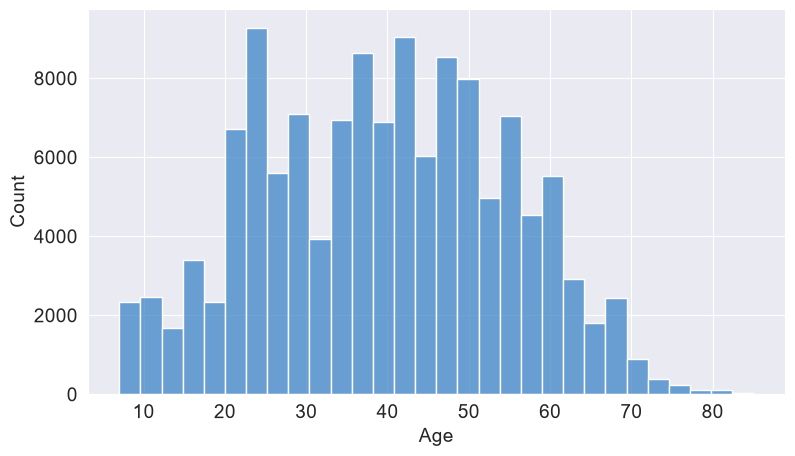

In [736]:
# Age distribution histogram
sns.histplot(df_raw['Age'], bins=30, color=medium_blue);

### ToDo age:
- Add new column 'age_group':
    - 7-11
    - 12-17
    - 18-24
    - 25-34
    - 35-44
    - 45-54
    - 55-64
    - 65-74
    - 75-85 

### Examine flight distance

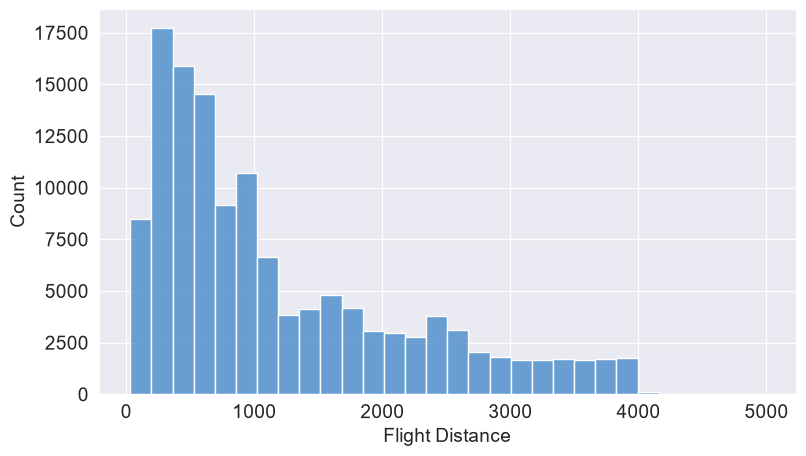

In [739]:
# Flight distnace distribution histogram
sns.histplot(df_raw['Flight Distance'], bins=30, color=medium_blue);

In [119]:
# Check the number of flights with flight distance under 100 miles (extreme short-distance)
df_raw[df_raw['Flight Distance'] < 100]['Flight Distance'].count()

np.int64(1015)

In [120]:
# Flag extremly short-distance flights for possible sensitivity analysis later
flag_extreme_short_distance = df_raw['Flight Distance'] < 100

### Check for duplicates

In [122]:
# Check for completely identical rows
df_raw.duplicated().sum()

np.int64(0)

In [123]:
# Check for identical rows except for IDs
df_raw.drop(columns='ID').duplicated().sum()

np.int64(0)

### --> NO DUPLICATES

### Check gender distibution

In [742]:
df_raw['Gender'].value_counts()

Gender
Female    65899
Male      63981
Name: count, dtype: int64

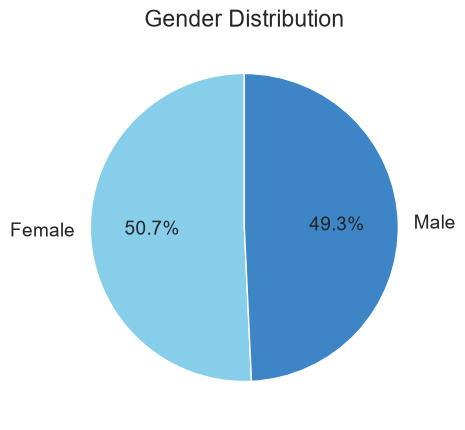

In [759]:
gender_count = df_raw['Gender'].value_counts()
gender_count.plot(kind='pie', labels=['Female', 'Male'], autopct='%.1f%%', colors=[sky_blue, medium_blue], startangle=90)
plt.title('Gender Distribution');

### Check customer type distribution

In [746]:
df_raw['Customer Type'].value_counts()

Customer Type
Returning     106100
First-time     23780
Name: count, dtype: int64

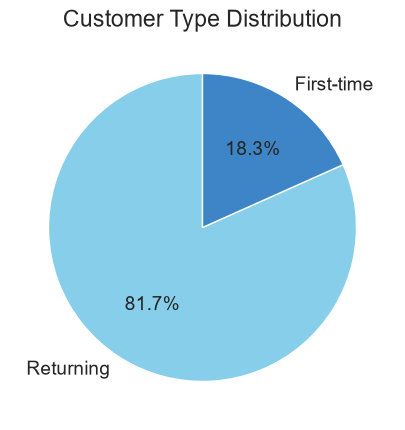

In [750]:
customer_type_count = df_raw['Customer Type'].value_counts()
customer_type_count.plot(kind='pie', labels=['Returning', 'First-time'], autopct='%.1f%%', colors=[sky_blue, medium_blue], startangle=90)
plt.title('Customer Type Distribution');

### Check type of travel distribution

In [757]:
df_raw['Type of Travel'].value_counts()

Type of Travel
Business    89693
Personal    40187
Name: count, dtype: int64

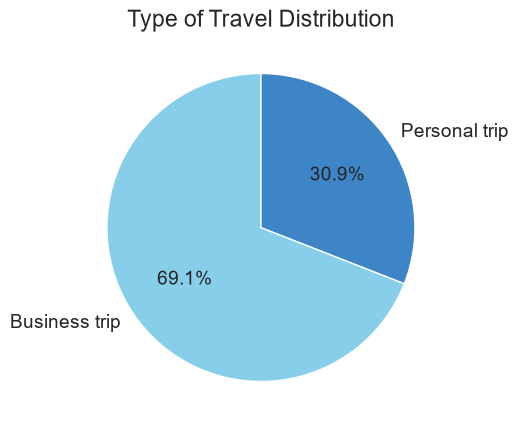

In [758]:
type_of_travel_count = df_raw['Type of Travel'].value_counts()
type_of_travel_count.plot(kind='pie', labels=['Business trip', 'Personal trip'], autopct='%.1f%%', colors=[sky_blue, medium_blue], startangle=90)
plt.title('Type of Travel Distribution');

### Check class distribution

In [760]:
df_raw['Class'].value_counts()

Class
Business        62160
Economy         58309
Economy Plus     9411
Name: count, dtype: int64

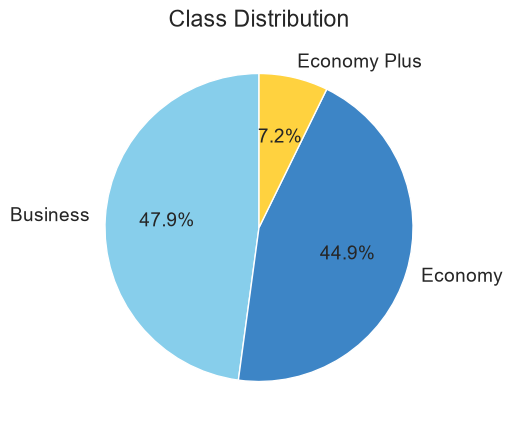

In [928]:
class_count = df_raw['Class'].value_counts()
class_count.plot(kind='pie', labels=['Business', 'Economy', 'Economy Plus'], autopct='%.1f%%', 
                 colors=[sky_blue, medium_blue, sunny_yellow], startangle=90)
plt.title('Class Distribution');

### Check departure delay distribution

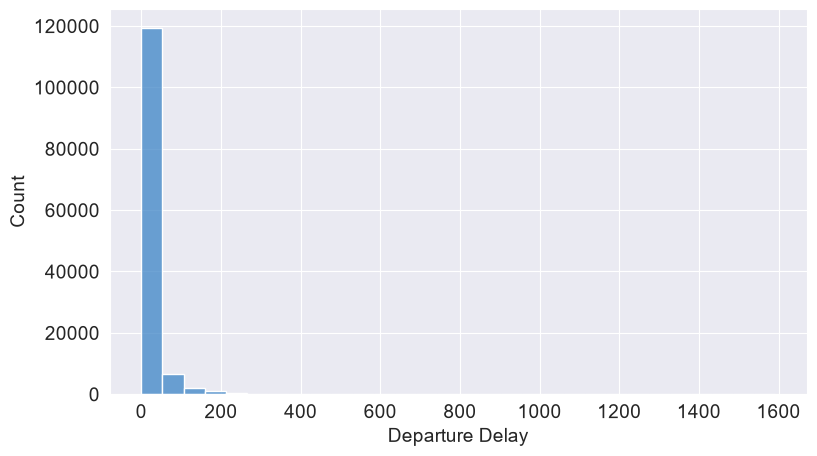

In [737]:
# Departure delay distribution histogram
sns.histplot(df_raw['Departure Delay'], bins=30, color=medium_blue);

### Check arival delay distribution

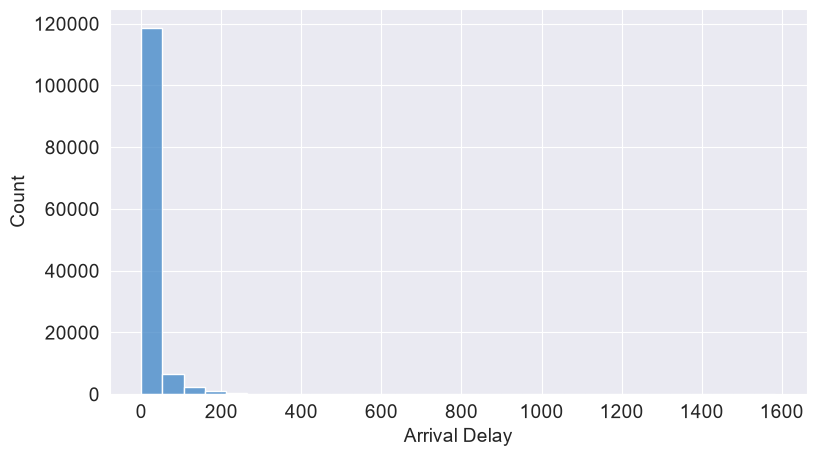

In [738]:
# Arrival delay distribution histogram
sns.histplot(df_raw['Arrival Delay'], bins=30, color=medium_blue);

## Findings on data distribution:
- Relatively equal proportions of male/female passengers
- Class: 7% Economy Plus, the rest - almost half/half Business class (48%) and Economy (45%)
- Majority Returning customers (~80%)
- Majority Business travellers (~70%)
- Age: 7-85, mostly ca. 20-60 y.o.
- Flight distance: mostly short-distance (up to 932 miles) and medium-distance on the lower end, around 1000 miles
- Departure and arrival delay: mostly 0 to low delay up to 1 hour

### Check answers 0="not applicable" in the rated categories

In [124]:
# Check the amount of answers 0="not applicable" in rated categories

rated_categories = ['Departure and Arrival Time Convenience', 'Ease of Online Booking', 'Check-in Service', \
                    'Online Boarding', 'Gate Location', 'On-board Service', 'Seat Comfort', 'Leg Room Service', \
                    'Cleanliness', 'Food and Drink', 'In-flight Service', 'In-flight Wifi Service', \
                    'In-flight Entertainment', 'Baggage Handling']

(df_raw[rated_categories] == 0).sum()

Departure and Arrival Time Convenience    6681
Ease of Online Booking                    5682
Check-in Service                             1
Online Boarding                           3080
Gate Location                                1
On-board Service                             5
Seat Comfort                                 1
Leg Room Service                           598
Cleanliness                                 14
Food and Drink                             132
In-flight Service                            5
In-flight Wifi Service                    3916
In-flight Entertainment                     18
Baggage Handling                             0
dtype: int64

### ToDos:
1. Check Food and Drink & In-flight Entertainment 0s with respect to flight distance
2. Check Leg Room Service 0s with respect to age

In [125]:
# Check Food and Drink 0s for flight distance
df_raw.groupby(df_raw['Food and Drink'] == 0)['Flight Distance'].median()

Food and Drink
False    844.0
True     797.0
Name: Flight Distance, dtype: float64

In [163]:
# Check Leg Room Service 0s for age
df_raw[df_raw['Leg Room Service'] == 0].Age.mean()

np.float64(54.063545150501675)

In [161]:
# Check In-flight Entertainment for flight distance
df_raw.groupby(df_raw['In-flight Entertainment'] ==0)['Flight Distance'].median()

In-flight Entertainment
False     844.0
True     1203.0
Name: Flight Distance, dtype: float64

In [162]:
df_raw.groupby(df_raw['In-flight Entertainment'] ==0)['Flight Distance'].min()

In-flight Entertainment
False    31
True     89
Name: Flight Distance, dtype: int64

### --> Findings on categories 'Food and Drink','In-flight Entertainment' and 'Leg Room Service' with answers 0="not applicable":
- 'Food and Drink' and 'In-flight Entertainment' with answers 0="not applicable" do not seem to be connected to flight distance (low distance -> no food, no entertainment) - passengers who did rate these categories and those who didn't show similar average flight distance. Average flight distance for unrated 'Food and Drink' (844 miles) is even higher than when food was rated (797 miles)
- 'Leg Room Service' with answers 0="not applicable" doesn't seem to be connected to age (young children -> leg room irrelevant) - average age of the passengers who did't rate 'Leg Room Service' is 54

### ToDos:
1. Delete rows with the answers 0="not applicable" for the categories with the very low number of 0s or low number of 0s and no meaningful explanation:
   - Check-in Service (1)
   - Gate location (1)
   - On-board Service (5)
   - Seat Comfort (1)
   - Leg Room Service (598)
   - Cleanliness (14)
   - Food and Drink (132)
   - In-flight Service (5)
   - In-flight Entertainment (18)
2. Create new indicator columns (reason: large amount of answers 0="not applicable"):
   - did_rate_time_convenience (true/false)
   - did_rate_online_booking (true/false)
   - did_rate_online_boarding (true/false)
   - did_rate_inflight_wifi (true/false)
3. Replace remaining 0s in the rated categories with NaN (important for clean correlations)

# 2. Datenbereinigung & -Modifizierung

## ToDos:
1. Create a copy of df_raw
2. Standardize column names (lower case, no spaces, no hyphens)
3. Replace NaNs in Arrival Delay with Departure Delay values (reason: necessary for the new category 'arrival_delay_category')
4. Standardize data type float64 --> int64 (Arrival Delay)
5. Add new categories:
    - 'age_group'
    - 'distance_category': Very short-distance, Short-distance, Medium-distance, Long-distance
    - 'departure_delay_category': 0 min, 1-14 min, 15-59 min, 1-3 h, Over 3 h
    - 'arrival_delay_category': 0 min, 1-14 min, 15-59 min, 1-3 h, Over 3 h
6. Do log transformation for delays (reason: extreme high-end outliers). New columns:
    - 'departure_delay_log'
    - 'arrival_delay_log'
7. Rename column 'satisfaction' in 'is_satisfied' and replace 'Satisfied'/'Neutral or Dissatisfied' with True/False
8. Add new columns with numerical or boolean values (important for correlations):
    - 'is_female': True/False (~Gender)
    - 'is_returning': True/False (~Customer Type)
    - 'purpose_is_business': True/False (~Type of Travel)
    - 'class_num': 0/1/2 (0=economy, 1=economy plus, 2=business) (~Class)
9. Add new indicator columns (reason: large amount of answers 0="not applicable"):
    - did_rate_time_convenience (True/False)
    - did_rate_online_booking (True/False)
    - did_rate_online_boarding (True/False)
    - did_rate_inflight_wifi (True/False)
10. Delete rows with the answers 0="not applicable" for the categories with the low number of 0s:
    - Check-in Service (1)
    - Gate location (1)
    - On-board Service (5)
    - Seat Comfort (1)
    - Leg Room Service (598)
    - Cleanliness (14)
    - Food and Drink (132)
    - In-flight Service (5)
    - In-flight Entertainment (18)
11. Replace remaining 0s in the rated categories with NaN (important for clean correlations; no problem for Random Forest 1.4 or newer, no problem for PRCA if indicator columns "did_rate..." included in the model; for k-Means I'd have to impute but I'm not planning to do k-Means)
12. Create a new dictionary df with modified fields and descriptions

## 2.1 Create a copy of df_raw

In [510]:
# Create a copy of df_raw
df_clean = df_raw.copy()
df_clean.head()

,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,Male,48,First-time,Business,Business,821,2,5.0,3,...,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821,26,39.0,2,...,5,4,5,5,3,5,2,5,5,Satisfied
2,3,Male,41,Returning,Business,Business,853,0,0.0,4,...,3,5,3,5,5,3,4,3,3,Satisfied
3,4,Male,50,Returning,Business,Business,1905,0,0.0,2,...,5,5,5,4,4,5,2,5,5,Satisfied
4,5,Female,49,Returning,Business,Business,3470,0,1.0,3,...,3,4,4,5,4,3,3,3,3,Satisfied


## 2.2 Standardize column names

In [511]:
# Change column names to lower case and delete spaces
df_clean.columns = df_clean.columns.str.lower().str.replace(' ', '_')
df_clean.head(2)

,id,gender,age,customer_type,type_of_travel,class,flight_distance,departure_delay,arrival_delay,departure_and_arrival_time_convenience,...,on-board_service,seat_comfort,leg_room_service,cleanliness,food_and_drink,in-flight_service,in-flight_wifi_service,in-flight_entertainment,baggage_handling,satisfaction
0,1,Male,48,First-time,Business,Business,821,2,5.0,3,...,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821,26,39.0,2,...,5,4,5,5,3,5,2,5,5,Satisfied


In [512]:
# Delete hyphens
df_clean.columns = df_clean.columns.str.replace('-', '')
df_clean.head(2)

,id,gender,age,customer_type,type_of_travel,class,flight_distance,departure_delay,arrival_delay,departure_and_arrival_time_convenience,...,onboard_service,seat_comfort,leg_room_service,cleanliness,food_and_drink,inflight_service,inflight_wifi_service,inflight_entertainment,baggage_handling,satisfaction
0,1,Male,48,First-time,Business,Business,821,2,5.0,3,...,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821,26,39.0,2,...,5,4,5,5,3,5,2,5,5,Satisfied


## 2.3 Replace NaNs in arrival_delay with departure_delay values

In [513]:
# Check rows with arrival_delay NaN
df_clean[df_clean.arrival_delay.isna()]

,id,gender,age,customer_type,type_of_travel,class,flight_distance,departure_delay,arrival_delay,departure_and_arrival_time_convenience,...,onboard_service,seat_comfort,leg_room_service,cleanliness,food_and_drink,inflight_service,inflight_wifi_service,inflight_entertainment,baggage_handling,satisfaction
246,247,Male,11,Returning,Business,Business,719,38,NaN,1,...,4,4,3,4,4,3,4,4,4,Neutral or Dissatisfied
883,884,Male,39,Returning,Business,Business,396,0,NaN,3,...,3,4,3,3,3,3,3,3,3,Satisfied
1965,1966,Male,36,Returning,Business,Economy,383,2,NaN,4,...,5,2,2,2,2,2,2,2,3,Satisfied
2407,2408,Female,55,Returning,Business,Business,2904,58,NaN,5,...,4,3,4,4,5,4,4,4,4,Neutral or Dissatisfied
2448,2449,Male,21,Returning,Personal,Economy Plus,767,5,NaN,3,...,4,1,2,1,1,2,1,1,1,Neutral or Dissatisfied
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129000,129001,Male,46,First-time,Business,Business,2704,7,NaN,3,...,4,4,2,4,4,4,3,4,3,Neutral or Dissatisfied
129003,129004,Female,17,First-time,Business,Economy,2704,0,NaN,3,...,2,1,4,1,1,3,3,1,4,Neutral or Dissatisfied
129014,129015,Male,57,Returning,Business,Business,2704,0,NaN,4,...,4,4,4,5,2,4,4,4,4,Satisfied
129015,129016,Female,22,Returning,Business,Business,2611,8,NaN,3,...,4,4,3,4,4,4,3,4,3,Satisfied


In [514]:
# Fill arrival_delay NaNs with departure_delay values
df_clean.arrival_delay = df_clean.arrival_delay.fillna(df_clean.departure_delay)

# Check is successful
df_clean.isna().any().any()

np.False_

## 2.4 Standardize data type float64 --> int64 (arrival_delay)

In [515]:
# Change data type of arrival_delay to int64
df_clean.arrival_delay = df_clean.arrival_delay.astype('int64')

# Check if successful
df_clean.arrival_delay.dtype

dtype('int64')

## 2.5 Add new categories
- 'age_group'
- 'distance_category':
    - Very short-distance: <310 miles
    - Short-distance: 310-932 miles
    - Medium-distance: 932 - 2485 miles
    - Long-distance: >2485 miles
- 'departure_delay_category': 0 min, 1-14 min, 15-59 min, 1-3 h, Over 3 h
- 'arrival_delay_category': 0 min, 1-14 min, 15-59 min, 1-3 h, Over 3 h

In [516]:
# Add 'age_group'
df_clean['age_group'] = pd.cut(df_clean.age,
                               bins=[7, 12, 18, 25, 35, 45, 55, 65, 75, 86],
                               labels=['7-11', '12-17', '18-24', '25-34', '35-44', '45-54', '55-64', '65-74', '75-85'],
                               right=False)

df_clean.head()

,id,gender,age,customer_type,type_of_travel,class,flight_distance,departure_delay,arrival_delay,departure_and_arrival_time_convenience,...,seat_comfort,leg_room_service,cleanliness,food_and_drink,inflight_service,inflight_wifi_service,inflight_entertainment,baggage_handling,satisfaction,age_group
0,1,Male,48,First-time,Business,Business,821,2,5,3,...,5,2,5,5,5,3,5,5,Neutral or Dissatisfied,45-54
1,2,Female,35,Returning,Business,Business,821,26,39,2,...,4,5,5,3,5,2,5,5,Satisfied,35-44
2,3,Male,41,Returning,Business,Business,853,0,0,4,...,5,3,5,5,3,4,3,3,Satisfied,35-44
3,4,Male,50,Returning,Business,Business,1905,0,0,2,...,5,5,4,4,5,2,5,5,Satisfied,45-54
4,5,Female,49,Returning,Business,Business,3470,0,1,3,...,4,4,5,4,3,3,3,3,Satisfied,45-54


In [517]:
# Add 'distance_category' (flight distance classification according to Eurocontrol) 

df_clean['distance_category'] = pd.cut(df_clean.flight_distance, 
                                    bins=[0, 310, 932, 2486, np.inf], 
                                    labels=['Very short-distance', 'Short-distance', 'Medium-distance', 'Long-distance'], 
                                    right=False)
            
df_clean.head()

,id,gender,age,customer_type,type_of_travel,class,flight_distance,departure_delay,arrival_delay,departure_and_arrival_time_convenience,...,leg_room_service,cleanliness,food_and_drink,inflight_service,inflight_wifi_service,inflight_entertainment,baggage_handling,satisfaction,age_group,distance_category
0,1,Male,48,First-time,Business,Business,821,2,5,3,...,2,5,5,5,3,5,5,Neutral or Dissatisfied,45-54,Short-distance
1,2,Female,35,Returning,Business,Business,821,26,39,2,...,5,5,3,5,2,5,5,Satisfied,35-44,Short-distance
2,3,Male,41,Returning,Business,Business,853,0,0,4,...,3,5,5,3,4,3,3,Satisfied,35-44,Short-distance
3,4,Male,50,Returning,Business,Business,1905,0,0,2,...,5,4,4,5,2,5,5,Satisfied,45-54,Medium-distance
4,5,Female,49,Returning,Business,Business,3470,0,1,3,...,4,5,4,3,3,3,3,Satisfied,45-54,Long-distance


In [518]:
df_clean.distance_category.unique()

['Short-distance', 'Medium-distance', 'Long-distance', 'Very short-distance']
Categories (4, str): ['Very short-distance' < 'Short-distance' < 'Medium-distance' < 'Long-distance']

In [519]:
df_clean.distance_category.value_counts().sort_index()

distance_category
Very short-distance    20759
Short-distance         49905
Medium-distance        41554
Long-distance          17662
Name: count, dtype: int64

In [520]:
# Add 'departure_delay_category'

df_clean['departure_delay_category'] = pd.cut(df_clean['departure_delay'],
                                              bins=[0, 1, 15, 60, 181, np.inf],
                                              labels=['0 min', '1-14 min', '15-59 min', '1-3 h', 'Over 3 h'],
                                              right=False)

df_clean.head()

,id,gender,age,customer_type,type_of_travel,class,flight_distance,departure_delay,arrival_delay,departure_and_arrival_time_convenience,...,cleanliness,food_and_drink,inflight_service,inflight_wifi_service,inflight_entertainment,baggage_handling,satisfaction,age_group,distance_category,departure_delay_category
0,1,Male,48,First-time,Business,Business,821,2,5,3,...,5,5,5,3,5,5,Neutral or Dissatisfied,45-54,Short-distance,1-14 min
1,2,Female,35,Returning,Business,Business,821,26,39,2,...,5,3,5,2,5,5,Satisfied,35-44,Short-distance,15-59 min
2,3,Male,41,Returning,Business,Business,853,0,0,4,...,5,5,3,4,3,3,Satisfied,35-44,Short-distance,0 min
3,4,Male,50,Returning,Business,Business,1905,0,0,2,...,4,4,5,2,5,5,Satisfied,45-54,Medium-distance,0 min
4,5,Female,49,Returning,Business,Business,3470,0,1,3,...,5,4,3,3,3,3,Satisfied,45-54,Long-distance,0 min


In [521]:
df_clean.departure_delay_category.unique()

['1-14 min', '15-59 min', '0 min', '1-3 h', 'Over 3 h']
Categories (5, str): ['0 min' < '1-14 min' < '15-59 min' < '1-3 h' < 'Over 3 h']

In [522]:
df_clean.departure_delay_category.value_counts().sort_index()

departure_delay_category
0 min        73356
1-14 min     26684
15-59 min    20672
1-3 h         7878
Over 3 h      1290
Name: count, dtype: int64

In [523]:
# Add 'arrival_delay_category'

df_clean['arrival_delay_category'] = pd.cut(df_clean['arrival_delay'],
                                            bins=[0, 1, 15, 60, 181, np.inf],
                                            labels=['0 min', '1-14 min', '15-59 min', '1-3 h', 'Over 3 h'],
                                            right=False)

df_clean.arrival_delay_category.unique()

['1-14 min', '15-59 min', '0 min', '1-3 h', 'Over 3 h']
Categories (5, str): ['0 min' < '1-14 min' < '15-59 min' < '1-3 h' < 'Over 3 h']

In [524]:
df_clean.arrival_delay_category.value_counts().sort_index()

arrival_delay_category
0 min        72900
1-14 min     26198
15-59 min    21403
1-3 h         8046
Over 3 h      1333
Name: count, dtype: int64

In [525]:
df_clean.head(2)

,id,gender,age,customer_type,type_of_travel,class,flight_distance,departure_delay,arrival_delay,departure_and_arrival_time_convenience,...,food_and_drink,inflight_service,inflight_wifi_service,inflight_entertainment,baggage_handling,satisfaction,age_group,distance_category,departure_delay_category,arrival_delay_category
0,1,Male,48,First-time,Business,Business,821,2,5,3,...,5,5,3,5,5,Neutral or Dissatisfied,45-54,Short-distance,1-14 min,1-14 min
1,2,Female,35,Returning,Business,Business,821,26,39,2,...,3,5,2,5,5,Satisfied,35-44,Short-distance,15-59 min,15-59 min


## 2.6 Do log transformation for delays (reason: extreme high-end outliers)

New columns:
- 'departure_delay_log'
- 'arrival_delay_log'

In [526]:
# Do log transformation and create new columns: departure_delay_log and arrival_delay_log

df_clean['departure_delay_log'] = np.log1p(df_clean['departure_delay'])
df_clean['arrival_delay_log'] = np.log1p(df_clean['arrival_delay'])

In [527]:
# Check arrival_delay vs. arrival_delay_log
df_clean[['arrival_delay', 'arrival_delay_log']].describe()

,arrival_delay,arrival_delay_log
count,129880.000000,129880.000000
mean,15.160102,1.266010
std,38.599601,1.631614
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,13.000000,2.639057
max,1584.000000,7.368340


## 2.7 Rename column 'satisfaction' in 'is_satisfied' and replace 'Satisfied'/'Neutral or Dissatisfied' with True/False (important for correlations)

In [528]:
# Rename column 'satisfaction' in 'is_satisfied'

df_clean = df_clean.rename(columns={'satisfaction': 'is_satisfied'})
df_clean.head(2)

,id,gender,age,customer_type,type_of_travel,class,flight_distance,departure_delay,arrival_delay,departure_and_arrival_time_convenience,...,inflight_wifi_service,inflight_entertainment,baggage_handling,is_satisfied,age_group,distance_category,departure_delay_category,arrival_delay_category,departure_delay_log,arrival_delay_log
0,1,Male,48,First-time,Business,Business,821,2,5,3,...,3,5,5,Neutral or Dissatisfied,45-54,Short-distance,1-14 min,1-14 min,1.098612,1.791759
1,2,Female,35,Returning,Business,Business,821,26,39,2,...,2,5,5,Satisfied,35-44,Short-distance,15-59 min,15-59 min,3.295837,3.688879


In [529]:
# Replace 'Satisfied'/'Neutral or Dissatisfied' with True/False

df_clean['is_satisfied'] = df_clean['is_satisfied'].map({'Satisfied': True,
                                                         'Neutral or Dissatisfied': False})

df_clean.is_satisfied.unique()

array([False,  True])

In [530]:
df_clean.head(2)

,id,gender,age,customer_type,type_of_travel,class,flight_distance,departure_delay,arrival_delay,departure_and_arrival_time_convenience,...,inflight_wifi_service,inflight_entertainment,baggage_handling,is_satisfied,age_group,distance_category,departure_delay_category,arrival_delay_category,departure_delay_log,arrival_delay_log
0,1,Male,48,First-time,Business,Business,821,2,5,3,...,3,5,5,False,45-54,Short-distance,1-14 min,1-14 min,1.098612,1.791759
1,2,Female,35,Returning,Business,Business,821,26,39,2,...,2,5,5,True,35-44,Short-distance,15-59 min,15-59 min,3.295837,3.688879


## 2.8 Add new columns with numerical or boolean values (important for correlations):
- 'is_female': True/False (~Gender)
- 'is_returning': True/False (~Customer Type)
- 'purpose_is_business': True/False (~Type of Travel)
- 'class_num': 0/1/2 (0=economy, 1=economy plus, 2=business) (~Class)

In [534]:
# Create new columns with True/False

df_clean['is_female'] = df_clean['gender'] == 'Female'
df_clean['is_returning'] = df_clean['customer_type'] == 'Returning'
df_clean['purpose_is_business'] = df_clean['type_of_travel'] == 'Business'

df_clean.head()

,id,gender,age,customer_type,type_of_travel,class,flight_distance,departure_delay,arrival_delay,departure_and_arrival_time_convenience,...,is_satisfied,age_group,distance_category,departure_delay_category,arrival_delay_category,departure_delay_log,arrival_delay_log,is_female,is_returning,purpose_is_business
0,1,Male,48,First-time,Business,Business,821,2,5,3,...,False,45-54,Short-distance,1-14 min,1-14 min,1.098612,1.791759,False,False,True
1,2,Female,35,Returning,Business,Business,821,26,39,2,...,True,35-44,Short-distance,15-59 min,15-59 min,3.295837,3.688879,True,True,True
2,3,Male,41,Returning,Business,Business,853,0,0,4,...,True,35-44,Short-distance,0 min,0 min,0.000000,0.000000,False,True,True
3,4,Male,50,Returning,Business,Business,1905,0,0,2,...,True,45-54,Medium-distance,0 min,0 min,0.000000,0.000000,False,True,True
4,5,Female,49,Returning,Business,Business,3470,0,1,3,...,True,45-54,Long-distance,0 min,1-14 min,0.000000,0.693147,True,True,True


In [535]:
# Create new numerical column class_num

df_clean['class_num'] = df_clean['class'].map({'Economy': 0, 'Economy Plus': 1, 'Business': 2})

df_clean.head()

,id,gender,age,customer_type,type_of_travel,class,flight_distance,departure_delay,arrival_delay,departure_and_arrival_time_convenience,...,age_group,distance_category,departure_delay_category,arrival_delay_category,departure_delay_log,arrival_delay_log,is_female,is_returning,purpose_is_business,class_num
0,1,Male,48,First-time,Business,Business,821,2,5,3,...,45-54,Short-distance,1-14 min,1-14 min,1.098612,1.791759,False,False,True,2
1,2,Female,35,Returning,Business,Business,821,26,39,2,...,35-44,Short-distance,15-59 min,15-59 min,3.295837,3.688879,True,True,True,2
2,3,Male,41,Returning,Business,Business,853,0,0,4,...,35-44,Short-distance,0 min,0 min,0.000000,0.000000,False,True,True,2
3,4,Male,50,Returning,Business,Business,1905,0,0,2,...,45-54,Medium-distance,0 min,0 min,0.000000,0.000000,False,True,True,2
4,5,Female,49,Returning,Business,Business,3470,0,1,3,...,45-54,Long-distance,0 min,1-14 min,0.000000,0.693147,True,True,True,2


## 2.9 Add new indicator columns:
- did_rate_time_convenience (True/False)
- did_rate_online_booking (True/False)
- did_rate_online_boarding (True/False)
- did_rate_inflight_wifi (True/False)

In [536]:
# Add indicator columns 'did_rate_x'

df_clean['did_rate_time_convenience'] = df_clean['departure_and_arrival_time_convenience'] !=0
df_clean['did_rate_online_booking'] = df_clean['ease_of_online_booking'] !=0
df_clean['did_rate_online_boarding'] = df_clean['online_boarding'] !=0
df_clean['did_rate_inflight_wifi'] = df_clean['inflight_wifi_service'] !=0

df_clean.head()

,id,gender,age,customer_type,type_of_travel,class,flight_distance,departure_delay,arrival_delay,departure_and_arrival_time_convenience,...,departure_delay_log,arrival_delay_log,is_female,is_returning,purpose_is_business,class_num,did_rate_time_convenience,did_rate_online_booking,did_rate_online_boarding,did_rate_inflight_wifi
0,1,Male,48,First-time,Business,Business,821,2,5,3,...,1.098612,1.791759,False,False,True,2,True,True,True,True
1,2,Female,35,Returning,Business,Business,821,26,39,2,...,3.295837,3.688879,True,True,True,2,True,True,True,True
2,3,Male,41,Returning,Business,Business,853,0,0,4,...,0.000000,0.000000,False,True,True,2,True,True,True,True
3,4,Male,50,Returning,Business,Business,1905,0,0,2,...,0.000000,0.000000,False,True,True,2,True,True,True,True
4,5,Female,49,Returning,Business,Business,3470,0,1,3,...,0.000000,0.693147,True,True,True,2,True,True,True,True


## 2.10 Delete rows with the answers 0="not applicable" for the categories with a) an extremely low number of 0s (e.g. Check-in Service) and b) a low number of 0s and no logical explanation (e.g. Food and Drink):
- Check-in Service (1)
- Gate location (1)
- On-board Service (5)
- Seat Comfort (1)
- Leg Room Service (598)
- Cleanliness (14)
- Food and Drink (132)
- In-flight Service (5)
- In-flight Entertainment (18)

In [537]:
# Delete rows with the answers 0="not applicable" for the categories with the low number of 0s

zero_cols = ['checkin_service', 'gate_location', 'onboard_service', 'seat_comfort', 'leg_room_service', 
             'cleanliness', 'food_and_drink', 'inflight_service', 'inflight_entertainment']

before = len(df_clean)
df_clean = df_clean[(df_clean[zero_cols] !=0).all(axis=1)]
print(before - len(df_clean), 'rows dropped')

737 rows dropped


## 2.11 Replace remaining 0s in the rated categories with NaN 

- Reason: important for clean correlations
- No problem for Random Forest 1.4 or newer
- No problem for PRCA if indicator columns "did_rate..." included in the model
- For k-Means I'd have to impute but I'm not planning to do k-Means

In [538]:
# Replace remaining 0s in the rated categories with NaN
nan_cols = ['departure_and_arrival_time_convenience', 'ease_of_online_booking', 'online_boarding', 'inflight_wifi_service']

df_clean[nan_cols] = df_clean[nan_cols].replace(0, np.nan)

# Check
df_clean.info()

<class 'pandas.DataFrame'>
Index: 129143 entries, 0 to 129879
Data columns (total 38 columns):
 #   Column                                  Non-Null Count   Dtype   
---  ------                                  --------------   -----   
 0   id                                      129143 non-null  int64   
 1   gender                                  129143 non-null  str     
 2   age                                     129143 non-null  int64   
 3   customer_type                           129143 non-null  str     
 4   type_of_travel                          129143 non-null  str     
 5   class                                   129143 non-null  str     
 6   flight_distance                         129143 non-null  int64   
 7   departure_delay                         129143 non-null  int64   
 8   arrival_delay                           129143 non-null  int64   
 9   departure_and_arrival_time_convenience  122624 non-null  float64 
 10  ease_of_online_booking                  124176 n

In [539]:
df_clean.describe()

,id,age,flight_distance,departure_delay,arrival_delay,departure_and_arrival_time_convenience,ease_of_online_booking,checkin_service,online_boarding,gate_location,...,leg_room_service,cleanliness,food_and_drink,inflight_service,inflight_wifi_service,inflight_entertainment,baggage_handling,departure_delay_log,arrival_delay_log,class_num
count,129143.000000,129143.000000,129143.000000,129143.000000,129143.000000,122624.000000,124176.000000,129143.000000,126063.000000,129143.000000,...,129143.000000,129143.000000,129143.000000,129143.000000,125468.000000,129143.000000,129143.000000,129143.000000,129143.000000,129143.000000
mean,64982.873458,39.366694,1192.619732,14.625973,15.069388,3.221107,2.882820,3.307419,3.330581,2.977072,...,3.366191,3.287263,3.208196,3.645703,2.816902,3.360252,3.635396,1.232694,1.264824,1.031810
std,37496.462284,15.105717,997.734267,37.740098,38.266810,1.386782,1.300341,1.265930,1.267624,1.279361,...,1.299438,1.313496,1.326765,1.174135,1.257579,1.332769,1.177553,1.615810,1.629845,0.962658
min,1.000000,7.000000,31.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
25%,32495.500000,27.000000,414.000000,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000,2.000000,...,2.000000,2.000000,2.000000,3.000000,2.000000,2.000000,3.000000,0.000000,0.000000,0.000000
50%,65008.000000,40.000000,846.000000,0.000000,0.000000,3.000000,3.000000,3.000000,4.000000,3.000000,...,4.000000,3.000000,3.000000,4.000000,3.000000,4.000000,4.000000,0.000000,0.000000,1.000000
75%,97461.500000,51.000000,1744.000000,12.000000,13.000000,4.000000,4.000000,4.000000,4.000000,4.000000,...,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,5.000000,2.564949,2.639057,2.000000
max,129880.000000,85.000000,4983.000000,1592.000000,1584.000000,5.000000,5.000000,5.000000,5.000000,5.000000,...,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,7.373374,7.368340,2.000000


## New scope after the cleanup and modification:
1. The dataframe df_clean contains:
- 129143 rows (737 rows dropped)
- 38 columns (14 columns added)
2. All of the attributes that will be used for correlations, etc. are available in numerical or boolean format

## 2.12 Create a new dictionary df with modified fields and descriptions

In [171]:
# Fetch original dictionary
df_dic

,Field,Description
0,ID,Unique passenger identifier
1,Gender,Gender of the passenger (Female/Male)
2,Age,Age of the passenger
3,Customer Type,Type of airline customer (First-time/Returning)
4,Type of Travel,Purpose of the flight (Business/Personal)
5,Class,Travel class in the airplane for the passenger seat
6,Flight Distance,Flight distance in miles
7,Departure Delay,Flight departure delay in minutes
8,Arrival Delay,Flight arrival delay in minutes
9,Departure and Arrival Time Convenience,"Satisfaction level with the convenience of the flight departure and arrival times from 1 (lowest) to 5 (highest) - 0 means ""not applicable"""


In [546]:
# Create a new dicionary
df_dic_new = df_dic.copy()

# Update field names and descriptions
df_dic_new['Field'] = df_dic_new['Field'].str.lower().str.replace(' ', '_').str.replace('-', '')
df_dic_new['Field'] = df_dic_new['Field'].str.replace('satisfaction', 'is_satisfied')
df_dic_new['Description'] = df_dic_new['Description'].str.replace(' - 0 means "not applicable"', '').str.replace(
    'Overall satisfaction level with the airline (Satisfied/Neutral or unsatisfied)', 
    'Overall satisfied with the airline (True = Satisfied, False = Neutral or Dissatisfied)')

df_dic_new

,Field,Description
0,id,Unique passenger identifier
1,gender,Gender of the passenger (Female/Male)
2,age,Age of the passenger
3,customer_type,Type of airline customer (First-time/Returning)
4,type_of_travel,Purpose of the flight (Business/Personal)
5,class,Travel class in the airplane for the passenger seat
6,flight_distance,Flight distance in miles
7,departure_delay,Flight departure delay in minutes
8,arrival_delay,Flight arrival delay in minutes
9,departure_and_arrival_time_convenience,Satisfaction level with the convenience of the flight departure and arrival times from 1 (lowest) to 5 (highest)


In [547]:
# Set index to "Field" for convenience
df_dic_new = df_dic_new.set_index('Field')

# Mention further modifications to the original fields
df_dic_new.loc['arrival_delay', 'Description'] += ' (393 missing values filled with departure delay values)'

nan_cols = ['departure_and_arrival_time_convenience', 'ease_of_online_booking', 'online_boarding', 'inflight_wifi_service']
df_dic_new.loc[nan_cols, 'Description'] += ' - NaN means "not applicable" (originally 0)'

df_dic_new

,Description
Field,
id,Unique passenger identifier
gender,Gender of the passenger (Female/Male)
age,Age of the passenger
customer_type,Type of airline customer (First-time/Returning)
type_of_travel,Purpose of the flight (Business/Personal)
class,Travel class in the airplane for the passenger seat
flight_distance,Flight distance in miles
departure_delay,Flight departure delay in minutes
arrival_delay,Flight arrival delay in minutes (393 missing values filled with departure delay values)


In [548]:
# Reset index
df_dic_new = df_dic_new.reset_index()

# Add new fields and descriptions
new_fields = {
    'age_group': 'Age group (7-11, 12-17, 18-24, 25-34, 35-44, 45-54, 55-64, 65-74, 75-85)',
    'distance_category': 'Flight distance category according to Eurocontrol (Very short-distance < 310 mi, Short-distance < 932 mi, Medium-distance 932-2.485 mi, Long-distance > 2.485 mi)',
    'departure_delay_category': 'Departure delay category (0 min, 1-14 min, 15-59 min, 1-3 h, Over 3 h)',
    'arrival_delay_category': 'Arrival delay category (0 min, 1-14 min, 15-59 min, 1-3 h, Over 3 h)',
    'departure_delay_log': 'Log-transformed departure delay, log(1 + minutes)',
    'arrival_delay_log': 'Log-transformed arrival delay, log(1 + minutes)',
    'is_female': 'Passenger is female (True/False)',
    'is_returning': 'Returning customer (True/False)',
    'purpose_is_business': 'Purpose of the flight is business (True/False)',
    'class_num': 'Travel class as number (0 = Economy, 1 = Economy Plus, 2 = Business)',
    'did_rate_time_convenience': 'Time convenience was rated (True) or "not applicable" (False)',
    'did_rate_online_booking': 'Online booking was rated (True) or "not applicable" (False)',
    'did_rate_online_boarding': 'Online boarding was rated (True) or "not applicable" (False)',
    'did_rate_inflight_wifi': 'In-flight wifi was rated (True) or "not applicable" (False)'
}

df_dic_new = pd.concat([df_dic_new,
                        pd.DataFrame(new_fields.items(), columns=['Field', 'Description'])],
                       ignore_index=True)

df_dic_new

,Field,Description
0,id,Unique passenger identifier
1,gender,Gender of the passenger (Female/Male)
2,age,Age of the passenger
3,customer_type,Type of airline customer (First-time/Returning)
4,type_of_travel,Purpose of the flight (Business/Personal)
5,class,Travel class in the airplane for the passenger seat
6,flight_distance,Flight distance in miles
7,departure_delay,Flight departure delay in minutes
8,arrival_delay,Flight arrival delay in minutes (393 missing values filled with departure delay values)
9,departure_and_arrival_time_convenience,"Satisfaction level with the convenience of the flight departure and arrival times from 1 (lowest) to 5 (highest) - NaN means ""not applicable"" (originally 0)"


# 3. Explorative Datenanalyse und Visualisierung

## Ziele und Fragestellungen
1. Verständnis der Zufriedenheitsverteilung im Datensatz: Wie zufrieden sind die Fluggäste insgesamt und wie unterscheidet sich die Zufriedenheit nach Kunden- und Flugmerkmalen? (Frage 1)
2. Identifizierung von Kundensegmenten. Gibt es besonders zufriedene oder besonders unzufriedene Kunden? (Frage 2)
3. Untersuchung des Zusammenhangs zwischen Bewertungen, Fluginformationen und Zufriedenheit. Konkret:
    - Welche Faktoren hängen am stärksten mit der Zufriedenheit zusammen, welche kaum? (Frage 3)
    - Unterscheiden sich Kundensegmente darin, welche Faktoren mit ihrer Zufriedenheit zusammenhängen? (Frage 4)
4. Priorisierung und Ableitung von Ansatzpunkten. Konkret:
    - Wie gut werden die einzelnen Kategorien bewertet, insgesamt und nach Segment? (Frage 5)
    - Wie lassen sich die Kategorien nach Wichtigkeit und Bewertung priorisieren? (Importance-Performance-Analyse) (Frage 6)
    - Wo liegen Ansatzpunkte zur Steigerung der Zufriedenheit, insgesamt und in einzelnen Kundensegmenten? (Frage 7)

## 3.1 Zufriedenheitsverteilung: Wie zufrieden sind die Fluggäste insgesamt und wie unterscheidet sich die Zufriedenheit nach Kunden- und Flugmerkmalen?

### Zufriedeneit insgesamt

In [549]:
# Satisfaction distribution overall (in %)
df_clean.is_satisfied.value_counts(normalize=True)

is_satisfied
False    0.565087
True     0.434913
Name: proportion, dtype: float64

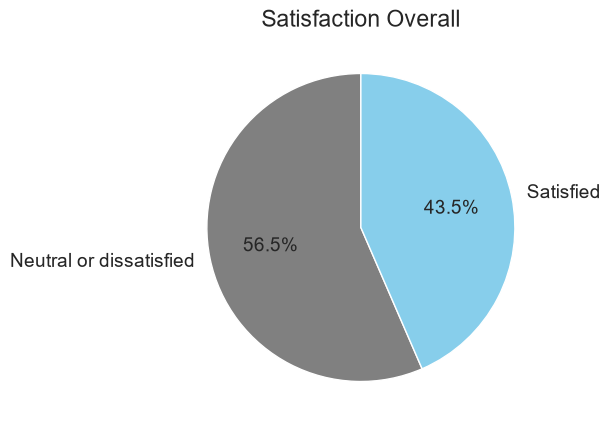

In [550]:
# Visualize 
satisfaction_count = df_clean.is_satisfied.value_counts()
satisfaction_count.plot(kind='pie', labels=['Neutral or dissatisfied', 'Satisfied'],
                        autopct='%.1f%%', colors=['gray', sky_blue], startangle=90)
plt.title('Satisfaction Overall');

### First findings about the overall satisfaction
- The passengers are overall somewhat more unsatisfied or neutral than satisfied: 57% neutral or unsatisfied vs. 44% satisfied

### Satisfaction by gender

In [220]:
# Satisfaction by gender
df_clean.groupby('gender')['is_satisfied'].value_counts(normalize=True)

gender  is_satisfied
Female  False           0.570438
        True            0.429562
Male    False           0.559613
        True            0.440387
Name: proportion, dtype: float64

In [264]:
ct = pd.crosstab(df_clean['gender'], df_clean['is_satisfied'], normalize='index') * 100
ct = ct.rename(columns={True: 'Satisfied', False: 'Neutral or dissatisfied'})
ct

is_satisfied,Neutral or dissatisfied,Satisfied
gender,,
Female,57.043763,42.956237
Male,55.961276,44.038724


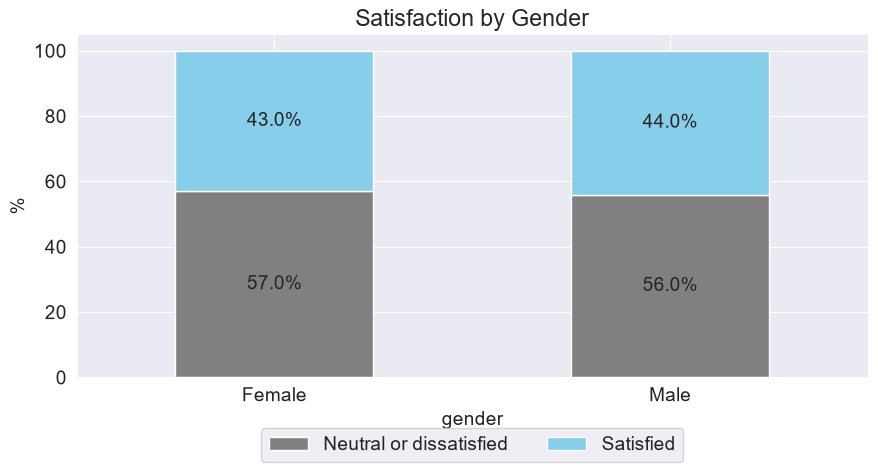

In [270]:
# Visualize satisfaction by gender
ct = pd.crosstab(df_clean['gender'], df_clean['is_satisfied'], normalize='index') * 100
ct = ct.rename(columns={True: 'Satisfied', False: 'Neutral or dissatisfied'})

ax = ct.plot(kind='bar', stacked=True, color=['gray', sky_blue])
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', label_type='center')

plt.ylabel('%')
plt.title('Satisfaction by Gender')
plt.xticks(rotation=0)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.tight_layout()
plt.show()

### Findings about gender and satisfaction levels
- There is practically no difference in satisfaction levels among male and female passengers - both groups are somewhat more unsatisfied or neutral (56-57%) than satisfied (43-44%), which is almost identical with the overall satisfaction distribution accross all passengers

### Satisfaction by age

In [271]:
# Satisfaction by age - underage vs. adults (in %)
df_clean.groupby('is_adult')['is_satisfied'].value_counts(normalize=True)

is_adult  is_satisfied
False     False           0.833333
          True            0.166667
True      False           0.542991
          True            0.457009
Name: proportion, dtype: float64

In [272]:
# Satisfaction by age - underage vs. adults (numbers)
df_clean.groupby('is_adult')['is_satisfied'].value_counts()

is_adult  is_satisfied
False     False            8190
          True             1638
True      False           64787
          True            54528
Name: count, dtype: int64

In [273]:
# Satisfaction by age group (in %)
df_clean.groupby('age_group')['is_satisfied'].value_counts(normalize=True)

age_group  is_satisfied
7-11       False           0.872276
           True            0.127724
12-17      False           0.806684
           True            0.193316
18-24      False           0.649777
           True            0.350223
25-34      False           0.630118
           True            0.369882
35-44      True            0.504690
           False           0.495310
45-54      True            0.581148
           False           0.418852
55-64      False           0.507797
           True            0.492203
65-74      False           0.828365
           True            0.171635
75-85      False           0.711864
           True            0.288136
Name: proportion, dtype: float64

In [274]:
# Satisfaction by age group (numbers)
df_clean.groupby('age_group')['is_satisfied'].value_counts()

age_group  is_satisfied
7-11       False            3483
           True              510
12-17      False            4707
           True             1128
18-24      False            9605
           True             5177
25-34      False           15528
           True             9115
35-44      True            15119
           False           14838
45-54      True            15469
           False           11149
55-64      False            8857
           True             8585
65-74      False            4474
           True              927
75-85      False             336
           True              136
Name: count, dtype: int64

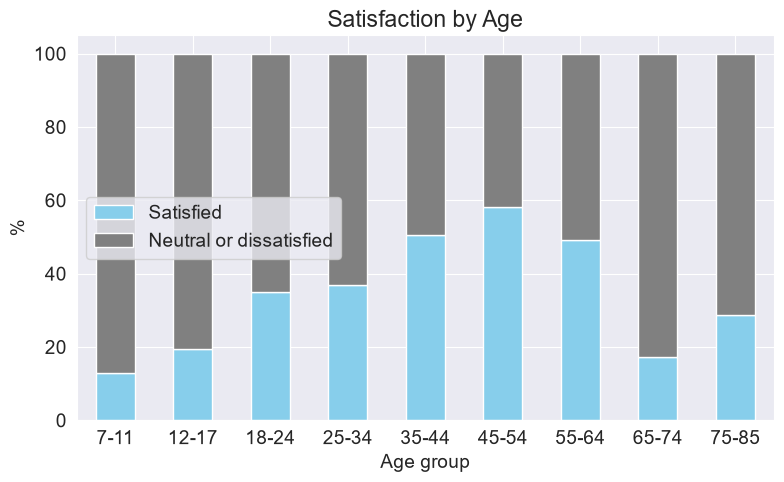

In [300]:
# Visualize satisfaction/dissatisfaction across age groups
ct = pd.crosstab(df_clean['age_group'], df_clean['is_satisfied'], normalize='index') * 100

ct.reindex(columns=[True, False]).plot(kind='bar', stacked=True, color=[sky_blue, 'gray'])
plt.title('Satisfaction by Age')
plt.ylabel('%')
plt.xlabel('Age group')
plt.legend(['Satisfied', 'Neutral or dissatisfied'], loc='center left')
plt.xticks(rotation=0);

### Interesting findings about age and satisfaction levels
- The most satisfied age group is 45-54 y.o. (58% satisfaction), followed by 35-44 y.o. (50%) and 55-64 y.o. (almost 50%)
- The least satisfied age groups are children, elderly and youth: 7-11 y.o. (only 12% satisaction), 65-74 y.o. (17%) and 12-17 y.o. (19%)

### Satisfaction by type of travel (business/personal)

In [277]:
# Satisfaction by type of travel
df_clean.groupby('type_of_travel')['is_satisfied'].value_counts(normalize=True)

type_of_travel  is_satisfied
Business        True            0.584382
                False           0.415618
Personal        False           0.902868
                True            0.097132
Name: proportion, dtype: float64

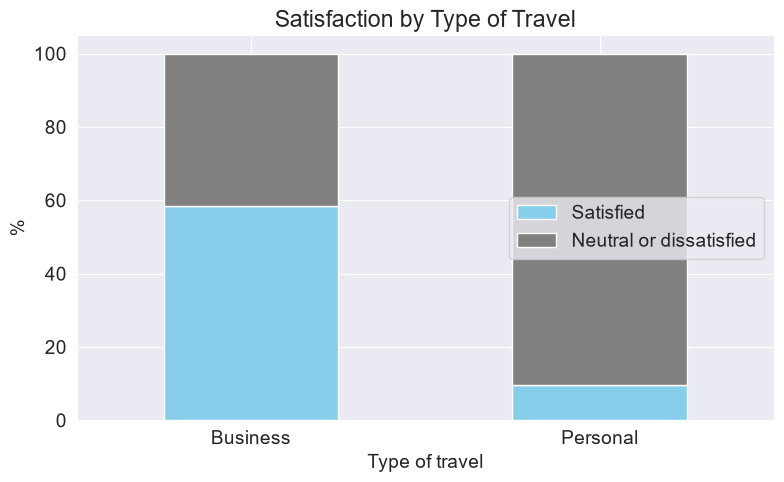

In [280]:
# Visualize satisfaction by type of travel
ct = pd.crosstab(df_clean['type_of_travel'], df_clean['is_satisfied'], normalize='index') * 100

ct.reindex(columns=[True, False]).plot(kind='bar', stacked=True, color=[sky_blue, 'gray'])
plt.title('Satisfaction by Type of Travel')
plt.ylabel('%')
plt.xlabel('Type of travel')
plt.legend(['Satisfied', 'Neutral or dissatisfied'], loc='center right')
plt.xticks(rotation=0);

### Interesting findings abour type of travel and satisfaction
- Passengers on business trips are significantly more satisfied than passengers flying for personal reasons (58% vs. 9%)
- Passengers with personal travel purposes are conspiciously unsatisfied (almost 90% neutral or unsatisfied) - I want to dig deeper into this

### Satisfaction by class (Economy, Economy Plus, Business)

In [281]:
# Satisfaction by class
df_clean.groupby('class')['is_satisfied'].value_counts(normalize=True)

class         is_satisfied
Business      True            0.695713
              False           0.304287
Economy       False           0.813881
              True            0.186119
Economy Plus  False           0.754258
              True            0.245742
Name: proportion, dtype: float64

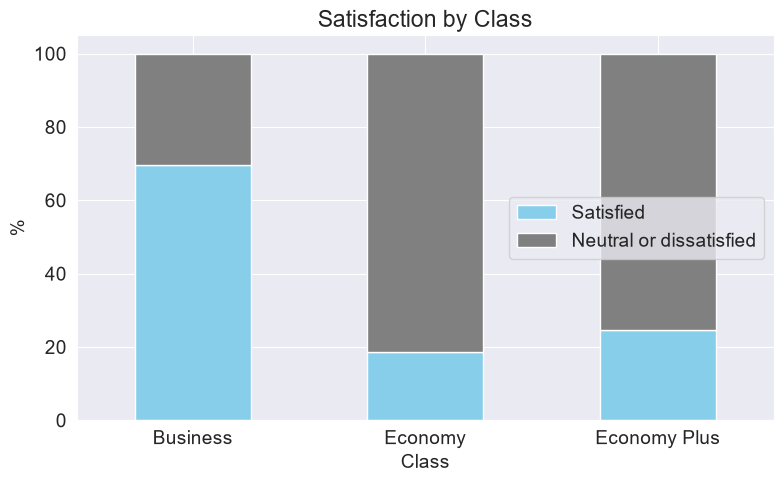

In [282]:
# Visualize satisfaction by class
ct = pd.crosstab(df_clean['class'], df_clean['is_satisfied'], normalize='index') * 100

ct.reindex(columns=[True, False]).plot(kind='bar', stacked=True, color=[sky_blue, 'gray'])
plt.title('Satisfaction by Class')
plt.ylabel('%')
plt.xlabel('Class')
plt.legend(['Satisfied', 'Neutral or dissatisfied'], loc='center right')
plt.xticks(rotation=0);

### Interesting findings about class and satisfaction levels
- Passengers flying business class are significantly more satisfied that economy plus and economy passengers: 68%, 24% and 18% respectively
- --> I want to check if there's a connection between business class and business as a purpose of travel 

### Satisfaction by type of travel AND class

In [301]:
# Satisfaction by type of travel AND class
df_clean.groupby(['type_of_travel', 'class'])['is_satisfied'].value_counts(normalize=True)

type_of_travel  class         is_satisfied
Business        Business      True            0.721595
                              False           0.278405
                Economy       False           0.700589
                              True            0.299411
                Economy Plus  False           0.607815
                              True            0.392185
Personal        Business      False           0.894696
                              True            0.105304
                Economy       False           0.901833
                              True            0.098167
                Economy Plus  False           0.915224
                              True            0.084776
Name: proportion, dtype: float64

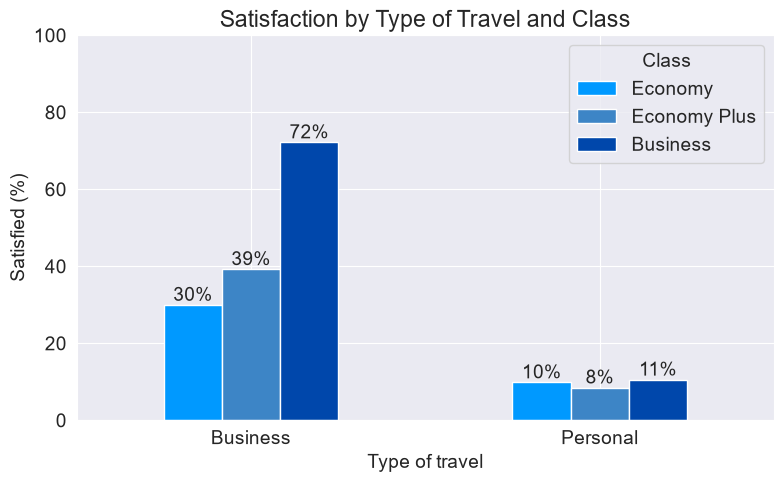

In [313]:
# Visualize satisfaction by type of travel AND class
rate = df_clean.groupby(['type_of_travel', 'class'])['is_satisfied'].mean().unstack() * 100
rate = rate[['Economy', 'Economy Plus', 'Business']]          # logical class order

ax = rate.plot(kind='bar', color=[bright_blue, medium_blue, trendy_blue])
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%')

plt.ylabel('Satisfied (%)')
plt.xlabel('Type of travel')
plt.title('Satisfaction by Type of Travel and Class')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title='Class')
plt.show()

### Very interesting finding about class and type of travel with regard to satisfaction
- Business class only has a positive effect on satisfaction **if** the passenger is **flying business class while on a business trip**
    - Satisfaction on business trips: 72% in business class, 39% in economy plus, 30% in economy
- The majority of passengers travelling for personal reasons are unsatisfied or neutral regardless of the class they are flying: only 8-11% satisfied regardless of class
- Passengers with personal purposes are even less satisfied in economy plus (only 8% satisfied) than in economy (10%)

In [308]:
# Check absolute numbers by type of travel and class
df_clean.groupby(['type_of_travel', 'class']).size()

type_of_travel  class       
Business        Business        59356
                Economy         25283
                Economy Plus     4888
Personal        Business         2602
                Economy         32567
                Economy Plus     4447
dtype: int64

### Satisfaction by customer type (first-time/returning)

In [284]:
# Satisfaction by customer type
df_clean.groupby('customer_type')['is_satisfied'].value_counts(normalize=True)

customer_type  is_satisfied
First-time     False           0.761033
               True            0.238967
Returning      False           0.520936
               True            0.479064
Name: proportion, dtype: float64

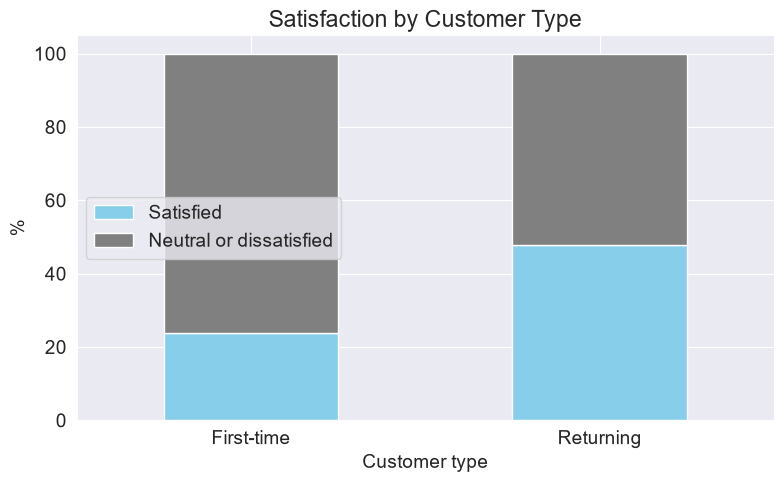

In [286]:
# Visualize satisfaction by customer type
ct = pd.crosstab(df_clean['customer_type'], df_clean['is_satisfied'], normalize='index') * 100

ct.reindex(columns=[True, False]).plot(kind='bar', stacked=True, color=[sky_blue, 'gray'])
plt.title('Satisfaction by Customer Type')
plt.ylabel('%')
plt.xlabel('Customer type')
plt.legend(['Satisfied', 'Neutral or dissatisfied'], loc='center left')
plt.xticks(rotation=0);

### Interesting findings about customer type and satisfaction levels
- Returning customers are significantly more satisfied than first-time pasengers (47% vs. 23%)

### Satisfaction by flight distance

In [287]:
# Satisfaction by flight distance
df_clean.groupby('distance_category')['is_satisfied'].value_counts(normalize=True)

distance_category    is_satisfied
Very short-distance  False           0.652059
                     True            0.347941
Short-distance       False           0.675704
                     True            0.324296
Medium-distance      False           0.516684
                     True            0.483316
Long-distance        True            0.734219
                     False           0.265781
Name: proportion, dtype: float64

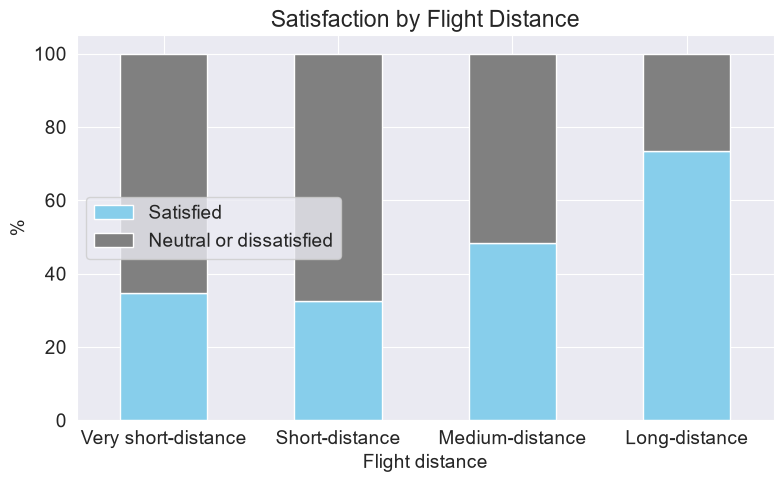

In [288]:
# Visualize satisfaction by flight distance
ct = pd.crosstab(df_clean['distance_category'], df_clean['is_satisfied'], normalize='index') * 100

ct.reindex(columns=[True, False]).plot(kind='bar', stacked=True, color=[sky_blue, 'gray'])
plt.title('Satisfaction by Flight Distance')
plt.ylabel('%')
plt.xlabel('Flight distance')
plt.legend(['Satisfied', 'Neutral or dissatisfied'], loc='center left')
plt.xticks(rotation=0);

### Interesting findings about flight distance and level of satisfaction
- The satisfaction is noticeably higher on medium- to long-distance flights, particularly the latter (73% satisfaction)
- The short-distance flights (310-932 miles) have the lowest satisfaction of all (32%) 

### Satisfaction by type of travel AND flight distance

In [309]:
# Cross-check satisfaction of business travelers by flight distance
df_clean.groupby(['type_of_travel', 'distance_category'])['is_satisfied'].value_counts(normalize=True)

type_of_travel  distance_category    is_satisfied
Business        Very short-distance  False           0.510727
                                     True            0.489273
                Short-distance       False           0.522558
                                     True            0.477442
                Medium-distance      True            0.631064
                                     False           0.368936
                Long-distance        True            0.764681
                                     False           0.235319
Personal        Very short-distance  False           0.897388
                                     True            0.102612
                Short-distance       False           0.906346
                                     True            0.093654
                Medium-distance      False           0.899740
                                     True            0.100260
                Long-distance        False           0.912879
                    

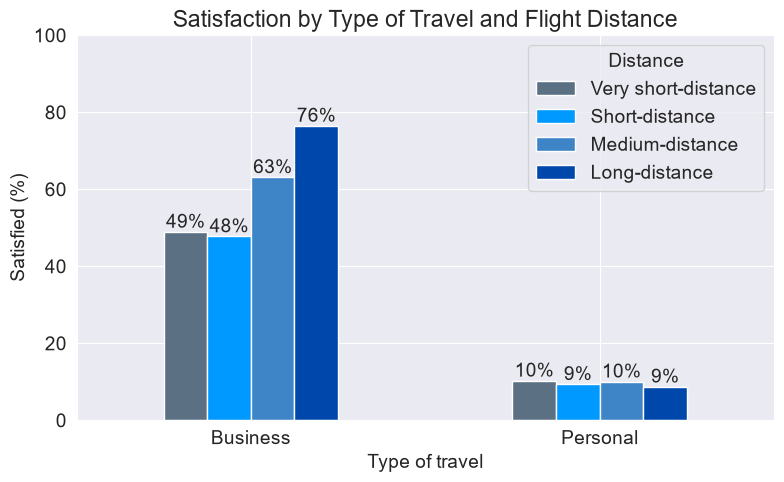

In [317]:
# Visualize satisfaction by type of travel and flight distance
rate = df_clean.groupby(['type_of_travel', 'distance_category'])['is_satisfied'].mean().unstack() * 100
rate = rate[['Very short-distance', 'Short-distance', 'Medium-distance', 'Long-distance']]          # logical distance order

ax = rate.plot(kind='bar', color=[blue_grey, bright_blue, medium_blue, trendy_blue])
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%')

plt.ylabel('Satisfied (%)')
plt.xlabel('Type of travel')
plt.title('Satisfaction by Type of Travel and Flight Distance')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title='Distance')
plt.show()

### Interesting findings about type of travel and flight distance with regard to satisfaction
- Once again, flight distance has little effect on satisfaction per se - only on business trips passengers are more satisfied on medium- and long-distance flights
- So, again it's coming back to passengers with business as a type of travel, who seem to be significantly more satisfied than people travelling for personal reasons
- At this point, we can say that **type/purpose of travel (business vs personal) is more much key to understanding satisfaction** than class or flight distance 

### Satisfaction by type of travel AND customer type

In [315]:
# Satisfaction by customer type AND type of travel
df_clean.groupby(['type_of_travel', 'customer_type'])['is_satisfied'].value_counts(normalize=True)

type_of_travel  customer_type  is_satisfied
Business        First-time     False           0.760352
                               True            0.239648
                Returning      True            0.707411
                               False           0.292589
Personal        First-time     False           0.840796
                               True            0.159204
                Returning      False           0.903184
                               True            0.096816
Name: proportion, dtype: float64

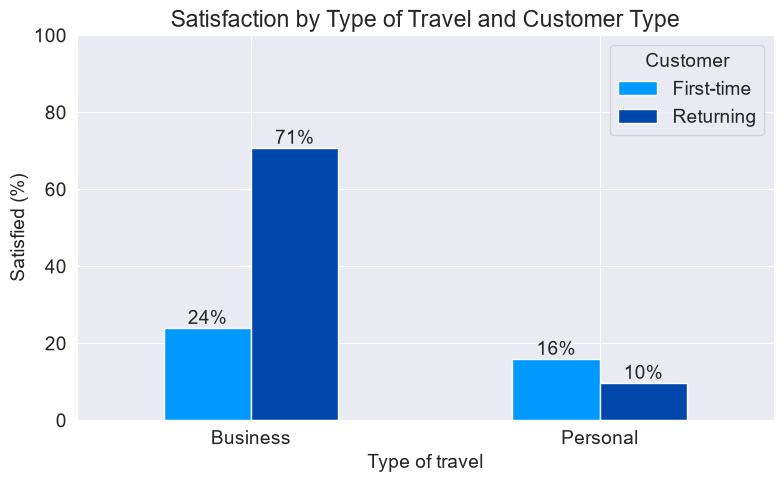

In [348]:
# Visualize satisfaction by customer type AND type of travel
rate = df_clean.groupby(['type_of_travel', 'customer_type'])['is_satisfied'].mean().unstack() * 100
rate = rate[['First-time', 'Returning']]          # Customer type order

ax = rate.plot(kind='bar', color=[bright_blue, trendy_blue])
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%')

plt.ylabel('Satisfied (%)')
plt.xlabel('Type of travel')
plt.title('Satisfaction by Type of Travel and Customer Type')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title='Customer')
plt.show()

### Another interesting finding that confirms the key role of type of travel in understanding satisfaction
- Earlier we've seen that returning customers are significantly more happy than first-time customers
- However, when we look closely and through the prism of the type of travel - again, we do not see much satisfaction among the passengers travelling for personal reasons, whether first time or repeatedly. Personal first-time travellers are even slightly more satisfied than returning ones (16% vs. 10% satisfaction). Business travelers on the other hand, are significantly more happy as returning customers - and that's what seems to be driving the higher satisfaction of the returning customers overall.
- Bottom line: It's **returning customers who fly on business** that are more satisfied than first-time customers.

### Satisfaction by type of travel AND age

In [319]:
# Check satisfaction by type of travel AND age
df_clean.groupby(['type_of_travel', 'age_group'])['is_satisfied'].value_counts(normalize=True)

type_of_travel  age_group  is_satisfied
Business        7-11       False           0.769596
                           True            0.230404
                12-17      False           0.637324
                           True            0.362676
                18-24      False           0.545638
                           True            0.454362
                25-34      False           0.539111
                           True            0.460889
                35-44      True            0.607911
                           False           0.392089
                45-54      True            0.729534
                           False           0.270466
                55-64      True            0.704327
                           False           0.295673
                65-74      False           0.642123
                           True            0.357877
                75-85      False           0.711864
                           True            0.288136
Personal        7-11    

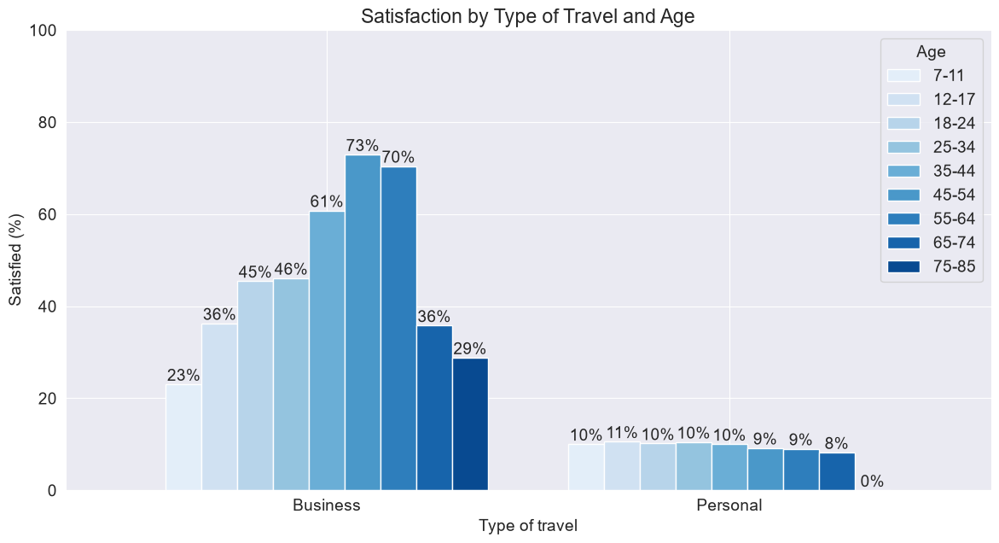

In [349]:
# Visualize satisfaction by type of travel and age
rate = df_clean.groupby(['type_of_travel', 'age_group'])['is_satisfied'].mean().unstack() * 100
rate = rate[['7-11', '12-17', '18-24', '25-34', '35-44', '45-54', '55-64', '65-74', '75-85']]          # Age group order

# Generate 9 blue colors from the color palette 'Blues'
colors = sns.color_palette('Blues', 9)

# Plot
ax = rate.plot(kind='bar', color=colors, figsize=(14, 7), width=0.8)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%')

plt.ylabel('Satisfied (%)')
plt.xlabel('Type of travel')
plt.title('Satisfaction by Type of Travel and Age')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title='Age')
plt.show()

### Key takeaways so far: Differences in satisfaction levels by age are also driven by business travellers!
- The more satisfied age groups that we've seen earlier (35-64 y.o.) are only more satisfied when they travel for business
- The majority of personal travellers is, again, dissatisfied or neutral - regardless of age (only 8-11% satisfaction across all age groups)

### Satisfaction by departure/arrival delay

In [289]:
# Satisfaction by departure delay
df_clean.groupby('departure_delay_category')['is_satisfied'].value_counts(normalize=True)

departure_delay_category  is_satisfied
0 min                     False           0.540330
                          True            0.459670
1-14 min                  False           0.562883
                          True            0.437117
15-59 min                 False           0.622874
                          True            0.377126
1-3 h                     False           0.639800
                          True            0.360200
Over 3 h                  False           0.638027
                          True            0.361973
Name: proportion, dtype: float64

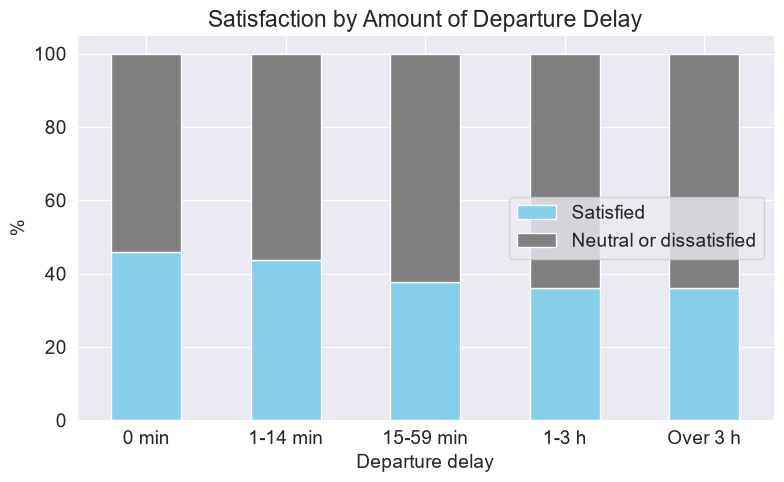

In [295]:
# Visualize satisfaction by departure delay
ct = pd.crosstab(df_clean['departure_delay_category'], df_clean['is_satisfied'], normalize='index') * 100

ct.reindex(columns=[True, False]).plot(kind='bar', stacked=True, color=[sky_blue, 'gray'])
plt.title('Satisfaction by Amount of Departure Delay')
plt.ylabel('%')
plt.xlabel('Departure delay')
plt.legend(['Satisfied', 'Neutral or dissatisfied'], loc='center right')
plt.xticks(rotation=0);

In [290]:
# Satisfaction by arrival delay
df_clean.groupby('arrival_delay_category')['is_satisfied'].value_counts(normalize=True)

arrival_delay_category  is_satisfied
0 min                   False           0.525814
                        True            0.474186
1-14 min                False           0.586298
                        True            0.413702
15-59 min               False           0.638692
                        True            0.361308
1-3 h                   False           0.644595
                        True            0.355405
Over 3 h                False           0.635593
                        True            0.364407
Name: proportion, dtype: float64

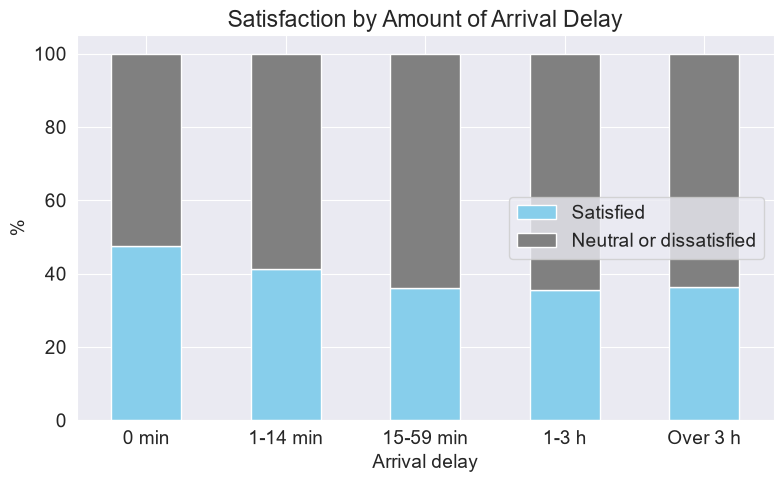

In [296]:
# Visualize satisfaction by arrival delay
ct = pd.crosstab(df_clean['arrival_delay_category'], df_clean['is_satisfied'], normalize='index') * 100

ct.reindex(columns=[True, False]).plot(kind='bar', stacked=True, color=[sky_blue, 'gray'])
plt.title('Satisfaction by Amount of Arrival Delay')
plt.ylabel('%')
plt.xlabel('Arrival delay')
plt.legend(['Satisfied', 'Neutral or dissatisfied'], loc='center right')
plt.xticks(rotation=0);

In [335]:
# Satisfaction by type of travel AND amount of arrival delay
df_clean.groupby(['type_of_travel', 'arrival_delay_category'])['is_satisfied'].value_counts(normalize=True)

type_of_travel  arrival_delay_category  is_satisfied
Business        0 min                   True            0.630216
                                        False           0.369784
                1-14 min                True            0.559452
                                        False           0.440548
                15-59 min               True            0.500101
                                        False           0.499899
                1-3 h                   False           0.506416
                                        True            0.493584
                Over 3 h                False           0.506997
                                        True            0.493003
Personal        0 min                   False           0.873886
                                        True            0.126114
                1-14 min                False           0.918344
                                        True            0.081656
                15-59 min            

### Interesting findings around flight delay and level of satisfaction
1. Surprisingly, there's practically no difference in satisfaction levels whether the delay was 15 min, or 1-2-3 hours. or more
2. It does make a difference however whether there is no delay at all vs. 1-14 minutes of delay **if** we're talking about **arrival** delay. If the arrival is delayed by 1-14 min, the satisfaction drops by ca. 6 points - from 47% to 41%. That's interesting because strictly speaking airlines do not consider anything below 15 minutes a delay, whereas passengers seem to feel differently about that. It's also interesting that a small delay of up to 14 minutes on departure doesn't have the same effect. The reason might be psychological: While at the departure gate, 1-14 minutes of delay might seem negligable or even go unnoticed, but once the destination is reached, passengers might start getting nervous about missing an appointment, a connecting flight or suchlike.
3. Even if the plane departs and arrives strictly on time with 0 delay, the passengers are still somewhat more unsatisfied or neutral (46-47%) than satisfied (53-54%), which is almost identical with the overall satisfaction distribution. The flight punctuality doesn't seem to have a noticeable positive effect on satisfaction. 

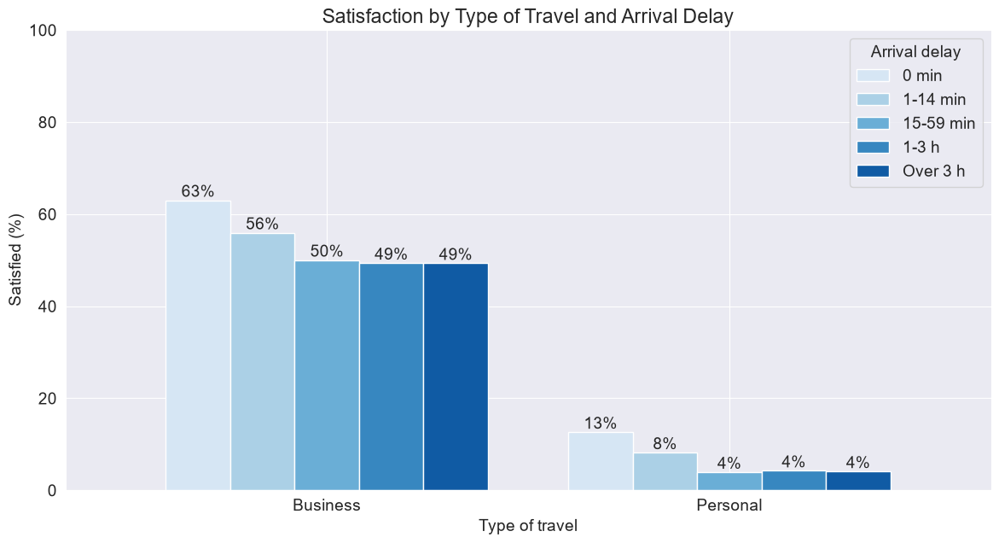

In [371]:
# Visualize satisfaction by type of travel AND amount of arrival delay
rate = df_clean.groupby(['type_of_travel', 'arrival_delay_category'])['is_satisfied'].mean().unstack() * 100
rate = rate[['0 min', '1-14 min', '15-59 min', '1-3 h', 'Over 3 h']]          # Arrival delay category order

# Generate 5 blue colors from the color palette 'Blues'
colors = sns.color_palette('Blues', 5)

# Plot
ax = rate.plot(kind='bar', color=colors, figsize=(14, 7), width=0.8)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%')

plt.ylabel('Satisfied (%)')
plt.xlabel('Type of travel')
plt.title('Satisfaction by Type of Travel and Arrival Delay')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title='Arrival delay')
plt.show()

### Takeaways so far regarding the effect of arrival delay on satisfaction
- Satisfaction drops with arrival delay up to about 15 minutes, then plateaus, for both travel types
    - Business: 63% --> ca. 50%
    - Peronsal: 13% --> 4%
    - Relatively, personal travellers lose more
- Travel type dominates: delayed business travellers are still far more satisfied than punctual personal travellers

In [338]:
# Satisfaction by flight distance and arrival delay
df_clean.groupby(['distance_category', 'arrival_delay_category'])['is_satisfied'].value_counts(normalize=True)

distance_category    arrival_delay_category  is_satisfied
Very short-distance  0 min                   False           0.614171
                                             True            0.385829
                     1-14 min                False           0.669087
                                             True            0.330913
                     15-59 min               False           0.733633
                                             True            0.266367
                     1-3 h                   False           0.737016
                                             True            0.262984
                     Over 3 h                False           0.758427
                                             True            0.241573
Short-distance       0 min                   False           0.638727
                                             True            0.361273
                     1-14 min                False           0.693582
                                

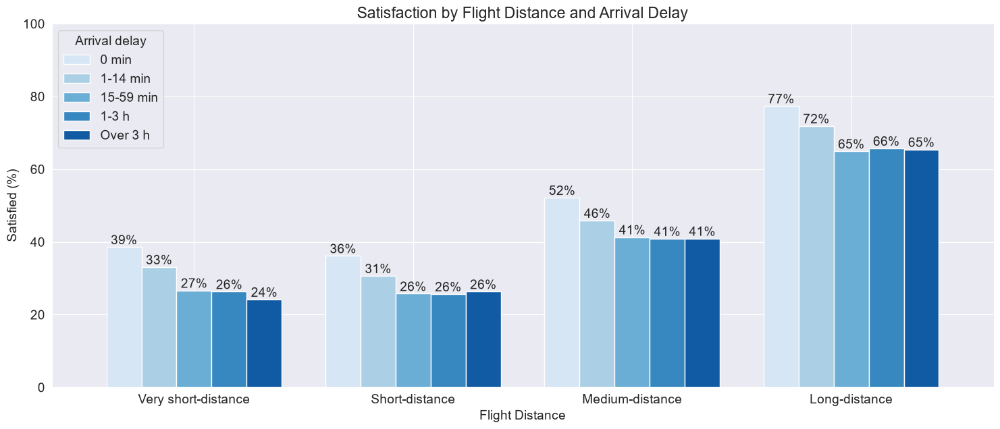

In [339]:
# Visualize satisfaction by flight distance and arrival delay
rate = df_clean.groupby(['distance_category', 'arrival_delay_category'])['is_satisfied'].mean().unstack() * 100
rate = rate[['0 min', '1-14 min', '15-59 min', '1-3 h', 'Over 3 h']]          # Arrival delay category order

# Generate 5 blue colors from the color palette 'Blues'
colors = sns.color_palette('Blues', 5)

# Plot
ax = rate.plot(kind='bar', color=colors, figsize=(18, 7), width=0.8)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%')

plt.ylabel('Satisfied (%)')
plt.xlabel('Flight Distance')
plt.title('Satisfaction by Flight Distance and Arrival Delay')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title='Arrival delay')
plt.show()

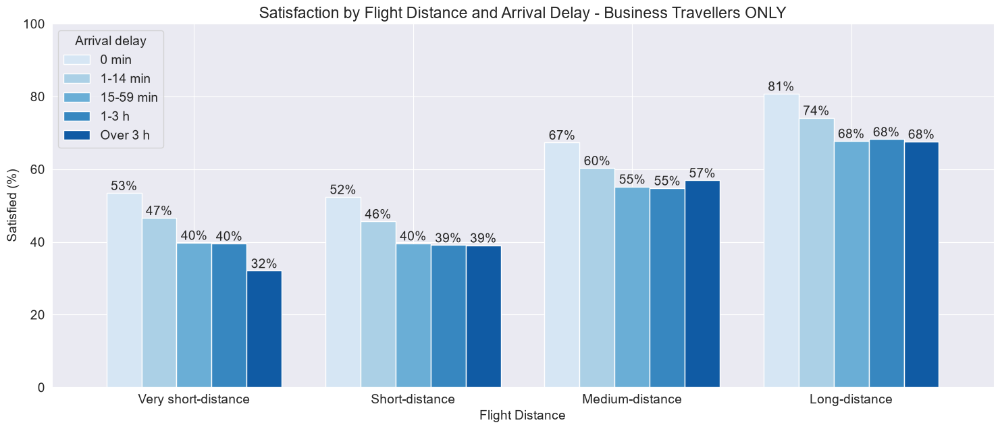

In [342]:
# Visualize satisfaction by flight distance and arrival delay - ONLY FOR BUSINESS TRAVELLERS
rate = df_clean[df_clean['type_of_travel'] == 'Business'].groupby(
    ['distance_category', 'arrival_delay_category'])['is_satisfied'].mean().unstack() * 100
rate = rate[['0 min', '1-14 min', '15-59 min', '1-3 h', 'Over 3 h']]          # Arrival delay category order

# Generate 5 blue colors from the color palette 'Blues'
colors = sns.color_palette('Blues', 5)

# Plot
ax = rate.plot(kind='bar', color=colors, figsize=(18, 7), width=0.8)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%')

plt.ylabel('Satisfied (%)')
plt.xlabel('Flight Distance')
plt.title('Satisfaction by Flight Distance and Arrival Delay - Business Travellers ONLY')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title='Arrival delay')
plt.show()

### Findings on business travellers and their satisfaction depending on flight distance and arrival delay
- Satisfaction rises with flight distance, as already observed earlier. On-time flights: 52–53 % (very short / short), 67 % (medium), 81 % (long). **Long-distance business travellers are the most satisfied group so far**.
- The delay pattern repeats in every distance category: a drop up to about 15 minutes, then a plateau. This confirms my previous finding across all distances.
- Exception: very short flights with over 3 h delay drop further to 32 %. That's plausible: on a short flight, a 3-hour delay can exceed the flight time itself. Delay probably matters relative to trip length, not just in absolute minutes.

-->
### Check if there is any class effect here. Long-distance business travellers fly business class more often?

In [353]:
# Check if there is connection between long-distance and class - for business travellers
pd.crosstab(df_clean[df_clean['type_of_travel'] == 'Business']['distance_category'], df_clean['class'], normalize='index')

class,Business,Economy,Economy Plus
distance_category,,,
Very short-distance,0.450378,0.460025,0.089597
Short-distance,0.483901,0.432927,0.083172
Medium-distance,0.754612,0.206382,0.039006
Long-distance,0.982168,0.013255,0.004577


### Class effect confirmed: 
- Confirmed and exceeded expectations: **Almost all business travellers fly business class on long-distance flights (98%)**
- The **majority of business travellers fly business class on medium-distance flights (75%)**
- On short- and very short-distance flights, almost half of the business travellers fly economy or economy class, not business class

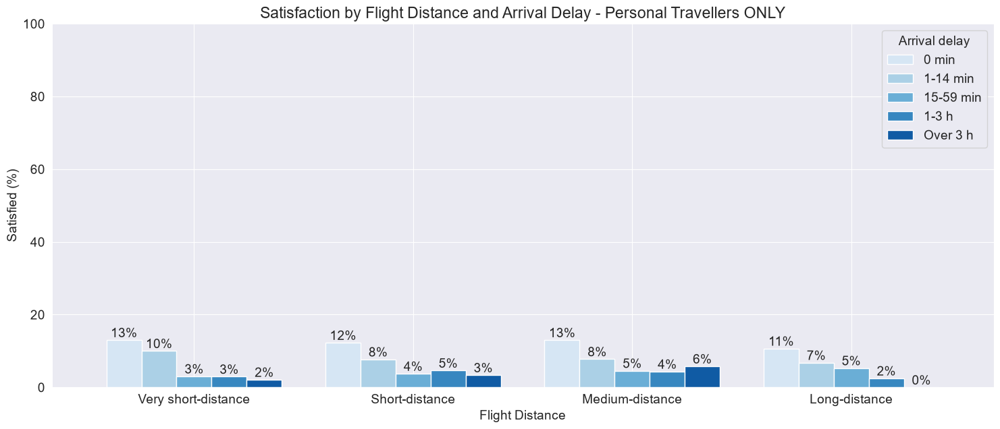

In [366]:
# Visualize satisfaction by flight distance and arrival delay - ONLY FOR PERSONAL TRAVELLERS
rate = df_clean[df_clean['type_of_travel'] == 'Personal'].groupby(
    ['distance_category', 'arrival_delay_category'])['is_satisfied'].mean().unstack() * 100
rate = rate[['0 min', '1-14 min', '15-59 min', '1-3 h', 'Over 3 h']]          # Arrival delay category order

# Generate 5 blue colors from the color palette 'Blues'
colors = sns.color_palette('Blues', 5)

# Plot
ax = rate.plot(kind='bar', color=colors, figsize=(18, 7), width=0.8)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%')

plt.ylabel('Satisfied (%)')
plt.xlabel('Flight Distance')
plt.title('Satisfaction by Flight Distance and Arrival Delay - Personal Travellers ONLY')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title='Arrival delay')
plt.show()

In [364]:
# Check number of personal travellers on flights with over 3 h delay
df_clean[(df_clean['type_of_travel'] == 'Personal') & (df_clean['arrival_delay_category'] == 'Over 3 h')].id.count()

np.int64(369)

In [354]:
# Check what class private travellers flight depending on distance
pd.crosstab(df_clean[df_clean['type_of_travel'] == 'Personal']['distance_category'], df_clean['class'], normalize='index')

class,Business,Economy,Economy Plus
distance_category,,,
Very short-distance,0.058674,0.823175,0.118151
Short-distance,0.066233,0.823177,0.110590
Medium-distance,0.068229,0.821181,0.110590
Long-distance,0.080808,0.796717,0.122475


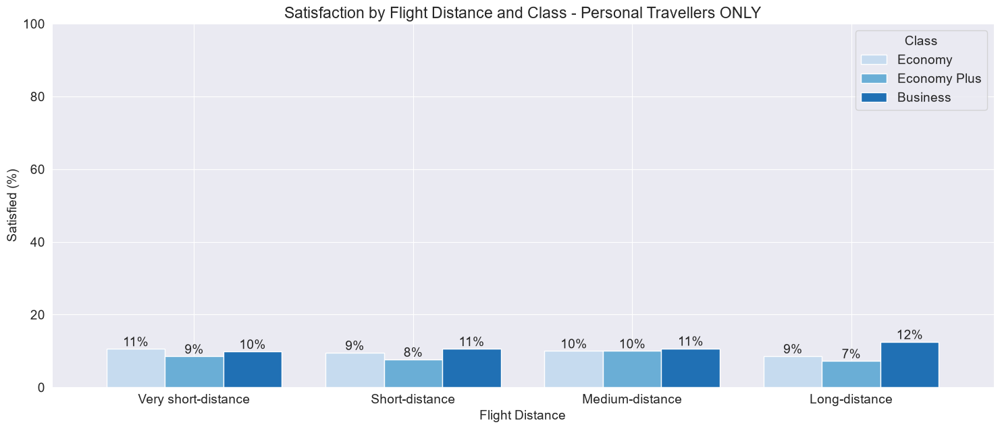

In [365]:
# Satisfaction of personal travellers by class and flight distance
rate = df_clean[df_clean['type_of_travel'] == 'Personal'].groupby(
    ['distance_category', 'class'])['is_satisfied'].mean().unstack() * 100
rate = rate[['Economy', 'Economy Plus', 'Business']]          # Class order

# Generate 3 blue colors from the color palette 'Blues'
colors = sns.color_palette('Blues', 3)

# Plot
ax = rate.plot(kind='bar', color=colors, figsize=(18, 7), width=0.8)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%')

plt.ylabel('Satisfied (%)')
plt.xlabel('Flight Distance')
plt.title('Satisfaction by Flight Distance and Class - Personal Travellers ONLY')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title='Class')
plt.show()

### Check relationship between satisfaction and rated or not rated: online booking, online boarding, time convenience and in-flight wifi

### Rated/not rated online booking vs. satisfaction

In [477]:
# Satisfaction by online booking - did rate/did not rate
df_clean.groupby('did_rate_online_booking')['is_satisfied'].value_counts()

did_rate_online_booking  is_satisfied
False                    True             3523
                         False            1444
True                     False           71533
                         True            52643
Name: count, dtype: int64

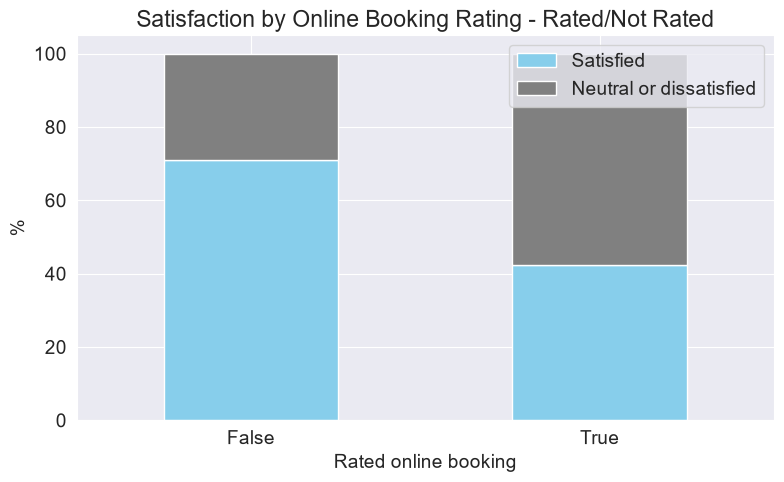

In [409]:
ct = pd.crosstab(df_clean['did_rate_online_booking'], df_clean['is_satisfied'], normalize='index') * 100

ct.reindex(columns=[True, False]).plot(kind='bar', stacked=True, color=[sky_blue, 'gray'])
plt.title('Satisfaction by Online Booking Rating - Rated/Not Rated')
plt.ylabel('%')
plt.xlabel('Rated online booking')
plt.legend(['Satisfied', 'Neutral or dissatisfied'], loc='upper right')
plt.xticks(rotation=0);

### Check for "business travellers" effect on online booking vs. satisfaction 

In [386]:
# Check distribution of business and personal passengers among those who did and did not rate online booking
pd.crosstab(df_clean['did_rate_online_booking'], df_clean['type_of_travel'], normalize='index')

type_of_travel,Business,Personal
did_rate_online_booking,,
False,0.658144,0.341856
True,0.694643,0.305357


In [401]:
# Check satisfaction level among business travellers only who did or did not rate online booking
business = df_clean[df_clean['type_of_travel'] == 'Business']

pd.crosstab(business['did_rate_online_booking'], business['is_satisfied'], normalize='index')

is_satisfied,False,True
did_rate_online_booking,,
False,0.118997,0.881003
True,0.426859,0.573141


In [402]:
# Check satisfaction level among personal travellers who did or did not rate online booking
business = df_clean[df_clean['type_of_travel'] == 'Personal']

pd.crosstab(business['did_rate_online_booking'], business['is_satisfied'], normalize='index')

is_satisfied,False,True
did_rate_online_booking,,
False,0.621319,0.378681
True,0.915475,0.084525


### Visualize satisfaction by type of travel and online booking rating (rated/not rated)

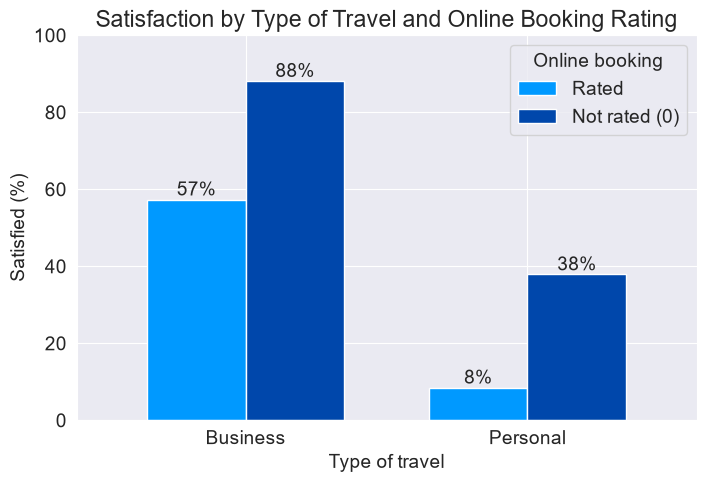

In [411]:
# Visualize satisfaction by type of travel and online boarding rating (did rate/did not rate)
rate = df_clean.groupby(['type_of_travel', 'did_rate_online_booking'])['is_satisfied'].mean().unstack() * 100
rate = rate.rename(columns={True: 'Rated', False: 'Not rated (0)'})[['Rated', 'Not rated (0)']]

ax = rate.plot(kind='bar', color=[bright_blue, trendy_blue], figsize=(8, 5), width=0.7)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%')

plt.title('Satisfaction by Type of Travel and Online Booking Rating')
plt.ylabel('Satisfied (%)')
plt.xlabel('Type of travel')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title='Online booking')
plt.show()

### Takeaway so far regarding online booking rating (rated/not rated) and satisfaction levels
- Passengers who did **not** rate (and possibly did not use?) online booking, show a higher satisfaction level (ca. 70% satisfied) than those who did rate it (slightly above 40% satisfied)
- Type of travel does not explain the difference in satisfaction levels in this case - there is a similar amount of business travellers in both groups, even slightly more among those who did rate online booking and ended up less satisfied:
    - did **not** rate online booking (more satisfied passengers): 65% business travellers
    - **did** rate online booking (less staisfied passengers): 69% business travellers
- Personal passengers who did not rate online booking have an unusually high satisfaction level, not seen anywhere else so far for this group of customers - 38% satisfaction 

### Rated/not rated online *boarding* vs. satisfaction

In [392]:
# Check if online boarding rated/not rated has any effect on satisfaction
df_clean.groupby('did_rate_online_boarding')['is_satisfied'].value_counts()

did_rate_online_boarding  is_satisfied
False                     True             1739
                          False            1341
True                      False           71636
                          True            54427
Name: count, dtype: int64

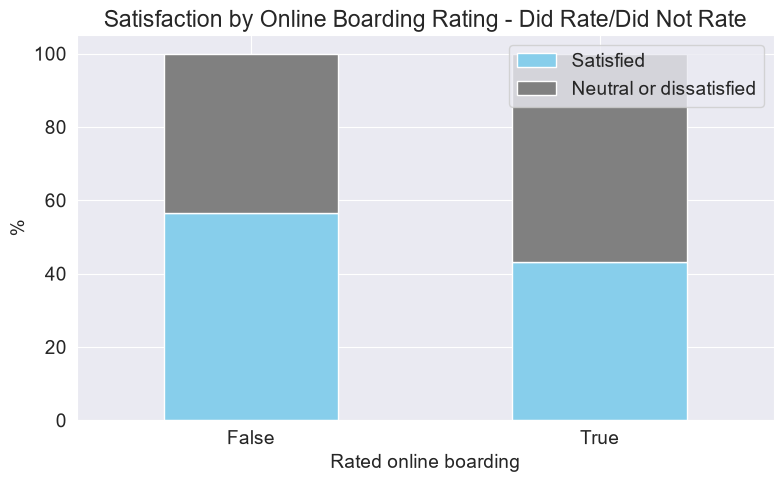

In [393]:
ct = pd.crosstab(df_clean['did_rate_online_boarding'], df_clean['is_satisfied'], normalize='index') * 100

ct.reindex(columns=[True, False]).plot(kind='bar', stacked=True, color=[sky_blue, 'gray'])
plt.title('Satisfaction by Online Boarding Rating - Did Rate/Did Not Rate')
plt.ylabel('%')
plt.xlabel('Rated online boarding')
plt.legend(['Satisfied', 'Neutral or dissatisfied'], loc='upper right')
plt.xticks(rotation=0);

In [394]:
# Check distribution of business and personal passengers among those who did and did not rate online boarding
pd.crosstab(df_clean['did_rate_online_boarding'], df_clean['type_of_travel'], normalize='index')

type_of_travel,Business,Personal
did_rate_online_boarding,,
False,0.456818,0.543182
True,0.699016,0.300984


In [400]:
# Check satisfaction level among business travelers only who did or did not rate online boarding
business = df_clean[df_clean['type_of_travel'] == 'Business']

pd.crosstab(business['did_rate_online_boarding'], business['is_satisfied'], normalize='index')

is_satisfied,False,True
did_rate_online_boarding,,
False,0.203269,0.796731
True,0.419008,0.580992


In [403]:
# Check satisfaction level among personal travelers only who did or did not rate online boarding
business = df_clean[df_clean['type_of_travel'] == 'Personal']

pd.crosstab(business['did_rate_online_boarding'], business['is_satisfied'], normalize='index')

is_satisfied,False,True
did_rate_online_boarding,,
False,0.630604,0.369396
True,0.914872,0.085128


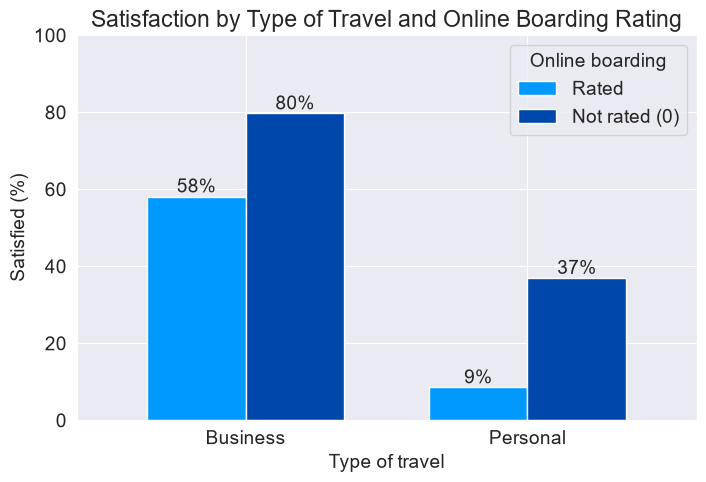

In [412]:
# Visualize satisfaction by type of travel and online boarding rating (did rate/did not rate)
rate = df_clean.groupby(['type_of_travel', 'did_rate_online_boarding'])['is_satisfied'].mean().unstack() * 100
rate = rate.rename(columns={True: 'Rated', False: 'Not rated (0)'})[['Rated', 'Not rated (0)']]

ax = rate.plot(kind='bar', color=[bright_blue, trendy_blue], figsize=(8, 5), width=0.7)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%')

plt.title('Satisfaction by Type of Travel and Online Boarding Rating')
plt.ylabel('Satisfied (%)')
plt.xlabel('Type of travel')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title='Online boarding')
plt.show()

### Takeaways so far regarding online boarding rating (rated/not rated) and satisfaction levels

Similar as online booking above

### Rated/not rated time convenience vs. satisfaction

In [413]:
# Check if time convenience rated/not rated has any effect on satisfaction
df_clean.groupby('did_rate_time_convenience')['is_satisfied'].value_counts()

did_rate_time_convenience  is_satisfied
False                      False            3344
                           True             3175
True                       False           69633
                           True            52991
Name: count, dtype: int64

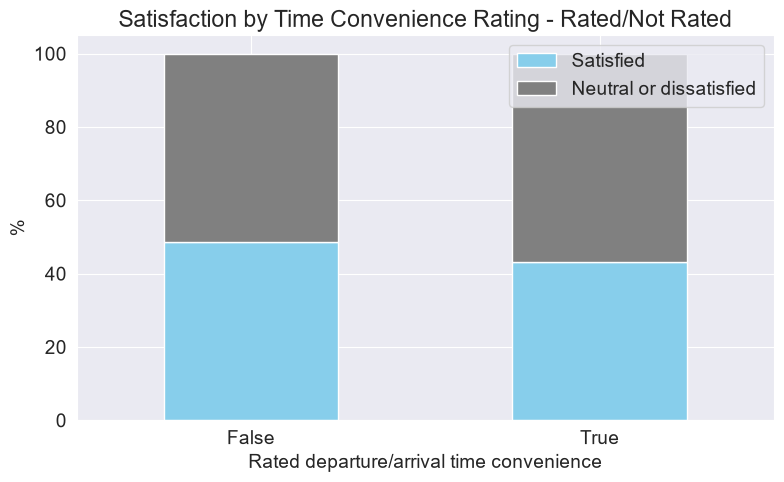

In [414]:
ct = pd.crosstab(df_clean['did_rate_time_convenience'], df_clean['is_satisfied'], normalize='index') * 100

ct.reindex(columns=[True, False]).plot(kind='bar', stacked=True, color=[sky_blue, 'gray'])
plt.title('Satisfaction by Time Convenience Rating - Rated/Not Rated')
plt.ylabel('%')
plt.xlabel('Rated departure/arrival time convenience')
plt.legend(['Satisfied', 'Neutral or dissatisfied'], loc='upper right')
plt.xticks(rotation=0);

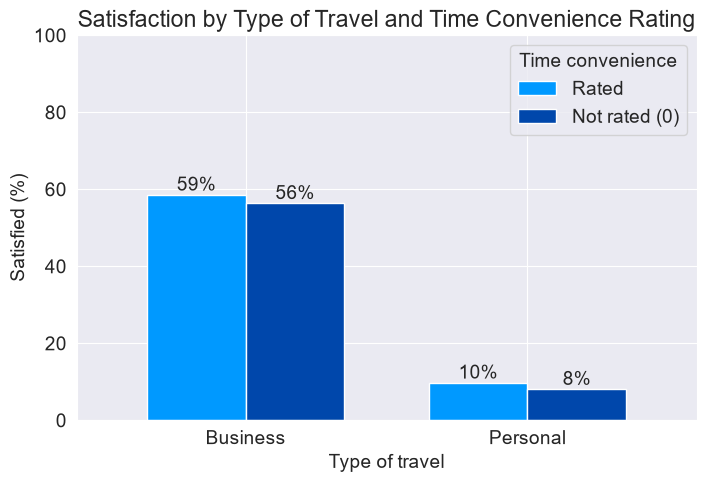

In [417]:
# Satisfaction by type of travel and time convenience rating (did rate/did not rate)
rate = df_clean.groupby(['type_of_travel', 'did_rate_time_convenience'])['is_satisfied'].mean().unstack() * 100
rate = rate.rename(columns={True: 'Rated', False: 'Not rated (0)'})[['Rated', 'Not rated (0)']]

ax = rate.plot(kind='bar', color=[bright_blue, trendy_blue], figsize=(8, 5), width=0.7)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%')

plt.title('Satisfaction by Type of Travel and Time Convenience Rating')
plt.ylabel('Satisfied (%)')
plt.xlabel('Type of travel')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title='Time convenience')
plt.show()

### --> Relation between time convenience rating (rated/not rated) and satisfaction seems normal

### Rated/not rated in-flight wifi vs. satisfaction

In [416]:
# Check if in-flight wifi rated/not rated has any effect on satisfaction
df_clean.groupby('did_rate_inflight_wifi')['is_satisfied'].value_counts()

did_rate_inflight_wifi  is_satisfied
False                   True             3675
True                    False           72977
                        True            52491
Name: count, dtype: int64

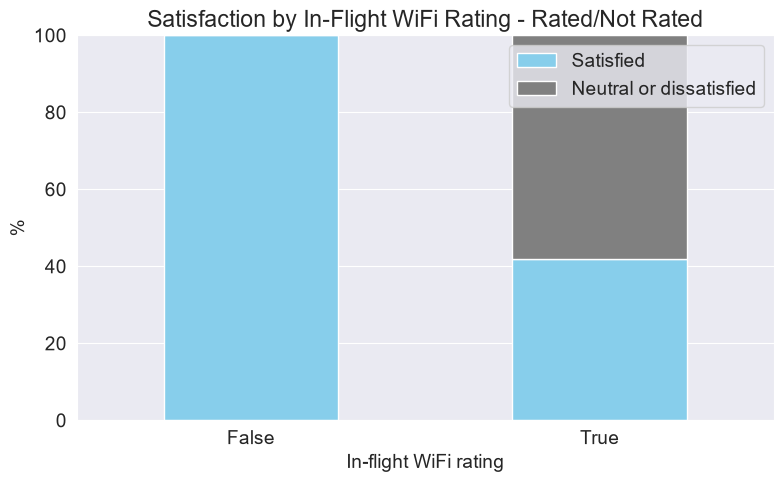

In [420]:
ct = pd.crosstab(df_clean['did_rate_inflight_wifi'], df_clean['is_satisfied'], normalize='index') * 100

ct.reindex(columns=[True, False]).plot(kind='bar', stacked=True, color=[sky_blue, 'gray'])
plt.title('Satisfaction by In-Flight WiFi Rating - Rated/Not Rated')
plt.ylabel('%')
plt.xlabel('In-flight WiFi rating')
plt.legend(['Satisfied', 'Neutral or dissatisfied'], loc='upper right')
plt.xticks(rotation=0);

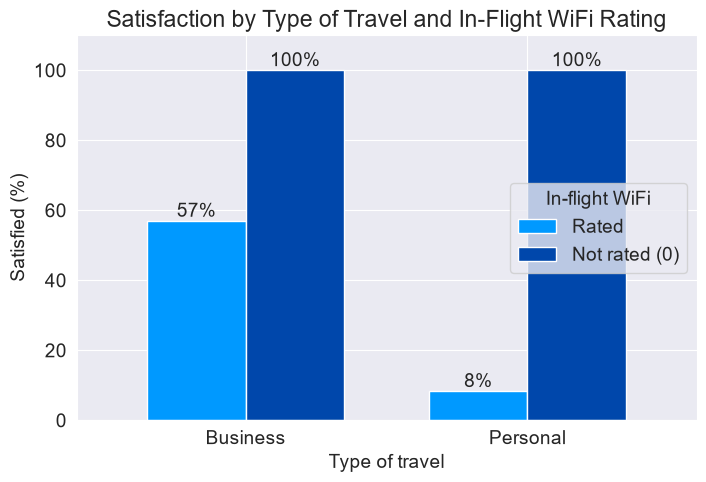

In [426]:
# Satisfaction by type of travel and inflight wifi rating (did rate/did not rate)
rate = df_clean.groupby(['type_of_travel', 'did_rate_inflight_wifi'])['is_satisfied'].mean().unstack() * 100
rate = rate.rename(columns={True: 'Rated', False: 'Not rated (0)'})[['Rated', 'Not rated (0)']]

ax = rate.plot(kind='bar', color=[bright_blue, trendy_blue], figsize=(8, 5), width=0.7)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%')

plt.title('Satisfaction by Type of Travel and In-Flight WiFi Rating')
plt.ylabel('Satisfied (%)')
plt.xlabel('Type of travel')
plt.ylim(0, 110)
plt.xticks(rotation=0)
plt.legend(title='In-flight WiFi', loc='center right')
plt.show()

# ! Achtung: Auffälliges Wifi-Artefakt

## Alle 3.675 Fluggäste ohne Wifi-Bewertung sind zu 100% zufrieden – sowohl Geschäfts- als auch Privatreisende

## To-dos:

1. Die 3.675 Datensätze auf weitere Auffälligkeiten prüfen
2. Prüfen, ob die hohe Zufriedenheit bei "Online Booking (Boarding) nicht bewertet" auf dieselben Datensätze zurückgeht
3. Markierung flag_wifi_artefact hinzufügen
4. Sensitivitätsanalyse mit und ohne diese Datensätze durchführen, um die Auswirkung auf die bisherigen Ergebnisse zu prüfen
5. Die 3.675 Datensätze von der weiteren Analyse ausschließen

### Prüfen, ob die hohe Zufriedenheit bei "Online Booking (Boarding) nicht bewertet" auf dieselben Datensätze zurückgeht

In [430]:
# Double check the online booking effect seen eralier - only among the passengers who DID rate WiFi
df_clean[df_clean['did_rate_inflight_wifi']].groupby('did_rate_online_booking')['is_satisfied'].mean()

did_rate_online_booking
False    0.061118
True     0.422795
Name: is_satisfied, dtype: float64

In [427]:
# Double check the online boarding effect seen eralier - only among the passengers who DID rate WiFi
df_clean[df_clean['did_rate_inflight_wifi']].groupby('did_rate_online_boarding')['is_satisfied'].mean()

did_rate_online_boarding
False    0.092079
True     0.422248
Name: is_satisfied, dtype: float64

### CONFIRMED

High satisfaction of the passengers who did not rate online booking/boarding came from the WiFi artifact

### Markierung flag_wifi_artefact hinzufügen

In [551]:
# Add a flag for the wifi artifact
flag_wifi_artefact = df_clean['did_rate_inflight_wifi'] == False
flag_wifi_artefact.sum()

np.int64(3675)

In [552]:
# Create df_sens for sensitivity analysis with and without the flagged rows
df_sens = df_clean[~flag_wifi_artefact]
len(df_sens)

125468

### Sensitivitätsanalyse mit und ohne diese Datensätze, um die Auswirkung auf die bisherigen Ergebnisse zu prüfen

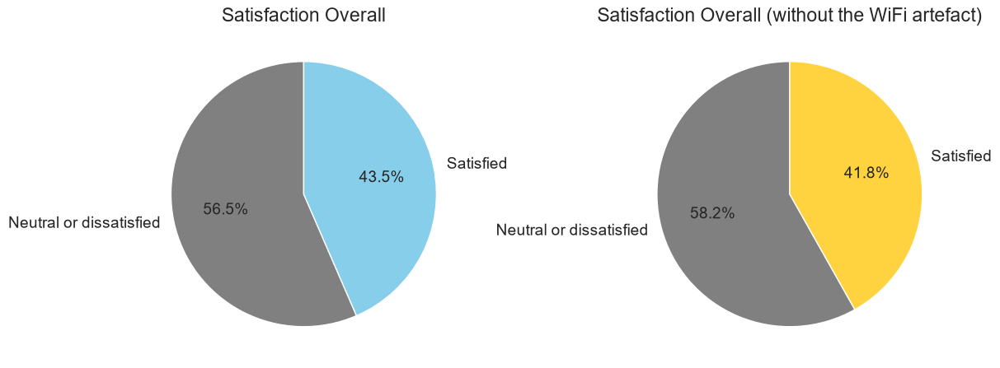

In [935]:
# Sensitivity analysis with and without the wifi artifact - satisfaction overall

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df_clean['is_satisfied'].value_counts().plot(
    kind='pie', ax=axes[0], labels=['Neutral or dissatisfied', 'Satisfied'],
    autopct='%.1f%%', colors=['gray', sky_blue], startangle=90)
axes[0].set_title('Satisfaction Overall')
axes[0].set_ylabel('')

df_sens['is_satisfied'].value_counts().plot(
    kind='pie', ax=axes[1], labels=['Neutral or dissatisfied', 'Satisfied'],
    autopct='%.1f%%', colors=['gray', sunny_yellow], startangle=90)
axes[1].set_title('Satisfaction Overall (without the WiFi artefact)')
axes[1].set_ylabel('')

plt.tight_layout();

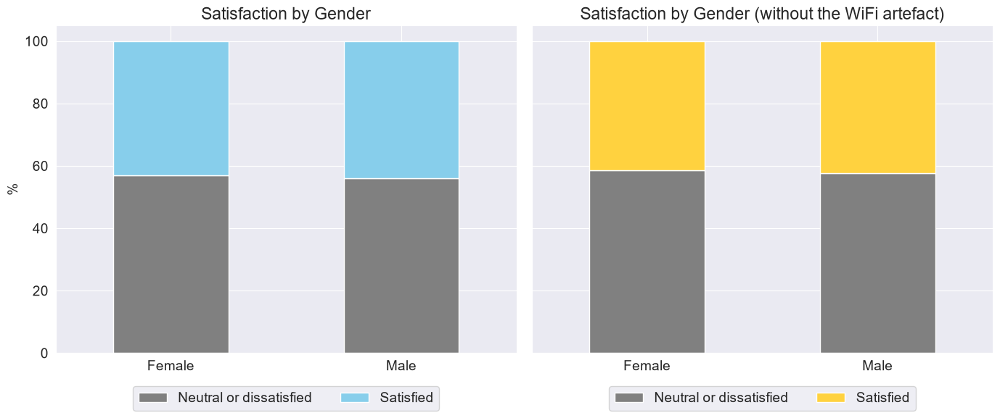

In [945]:
# Sensitivity analysis with and without the wifi artifact - satisfaction by gender

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

for ax, data, color, title in [
    (axes[0], df_clean, sky_blue, 'Satisfaction by Gender'),
    (axes[1], df_sens, sunny_yellow, 'Satisfaction by Gender (without the WiFi artefact)'),
]:
    ct = pd.crosstab(data['gender'], data['is_satisfied'], normalize='index') * 100
    ct = ct.rename(columns={True: 'Satisfied', False: 'Neutral or dissatisfied'})

    ct.plot(kind='bar', stacked=True, color=['gray', color], ax=ax)

    ax.set_title(title)
    ax.set_ylabel('%')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=0)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2)

plt.tight_layout();

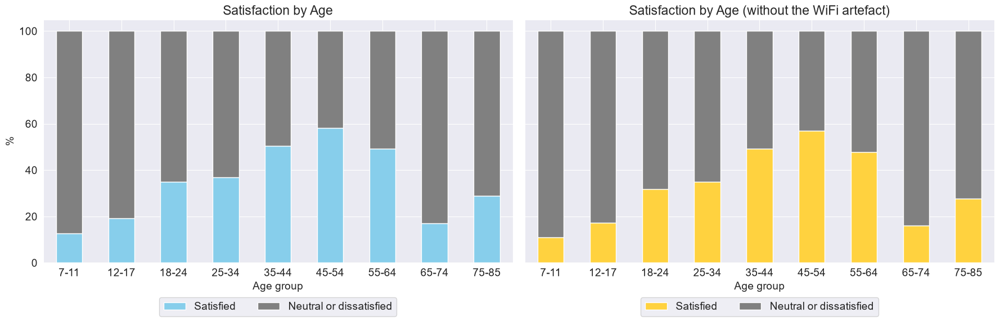

In [936]:
# Sensitivity analysis with and without the wifi artifact - satisfaction by age group

fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

for ax, data, color, title in [
    (axes[0], df_clean, sky_blue, 'Satisfaction by Age'),
    (axes[1], df_sens, sunny_yellow, 'Satisfaction by Age (without the WiFi artefact)'),
]:
    ct = pd.crosstab(data['age_group'], data['is_satisfied'], normalize='index') * 100
    ct = ct.reindex(columns=[True, False])

    ct.plot(kind='bar', stacked=True, color=[color, 'gray'], ax=ax, legend=False)
    ax.set_title(title)
    ax.set_ylabel('%')
    ax.set_xlabel('Age group')
    ax.tick_params(axis='x', rotation=0)
    ax.legend(['Satisfied', 'Neutral or dissatisfied'], loc='upper center',
              bbox_to_anchor=(0.5, -0.12), ncol=2)

plt.tight_layout();

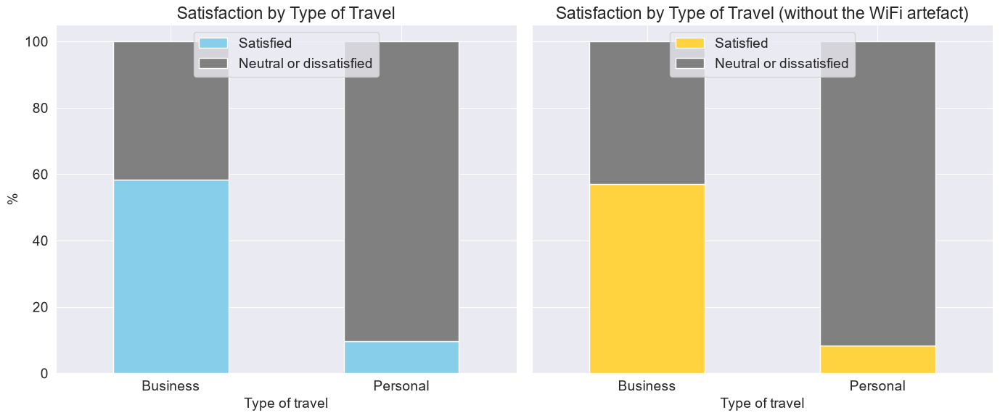

In [940]:
# Sensitivity analysis with and without the wifi artifact - satisfaction by type of travel

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

for ax, data, color, title in [
    (axes[0], df_clean, sky_blue, 'Satisfaction by Type of Travel'),
    (axes[1], df_sens, sunny_yellow, 'Satisfaction by Type of Travel (without the WiFi artefact)'),
]:
    ct = pd.crosstab(data['type_of_travel'], data['is_satisfied'], normalize='index') * 100
    ct = ct.reindex(columns=[True, False])

    ct.plot(kind='bar', stacked=True, color=[color, 'gray'], ax=ax, legend=False)

    ax.set_title(title)
    ax.set_ylabel('%')
    ax.set_xlabel('Type of travel')
    ax.tick_params(axis='x', rotation=0)
    ax.legend(['Satisfied', 'Neutral or dissatisfied'], loc='upper center')

plt.tight_layout();

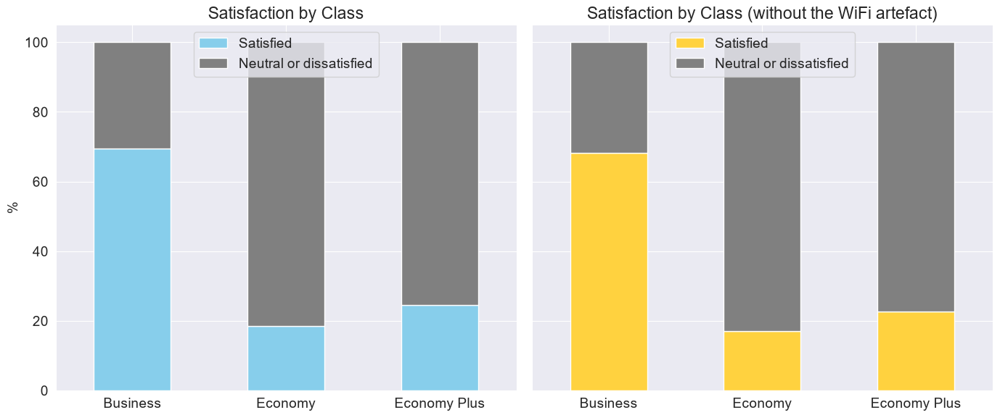

In [941]:
# Sensitivity analysis with and without the wifi artifact - satisfaction by class

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

for ax, data, color, title in [
    (axes[0], df_clean, sky_blue, 'Satisfaction by Class'),
    (axes[1], df_sens, sunny_yellow, 'Satisfaction by Class (without the WiFi artefact)'),
]:
    ct = pd.crosstab(data['class'], data['is_satisfied'], normalize='index') * 100
    ct = ct.reindex(columns=[True, False])

    ct.plot(kind='bar', stacked=True, color=[color, 'gray'], ax=ax, legend=False)

    ax.set_title(title)
    ax.set_ylabel('%')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=0)
    ax.legend(['Satisfied', 'Neutral or dissatisfied'], loc='upper center',)

plt.tight_layout()

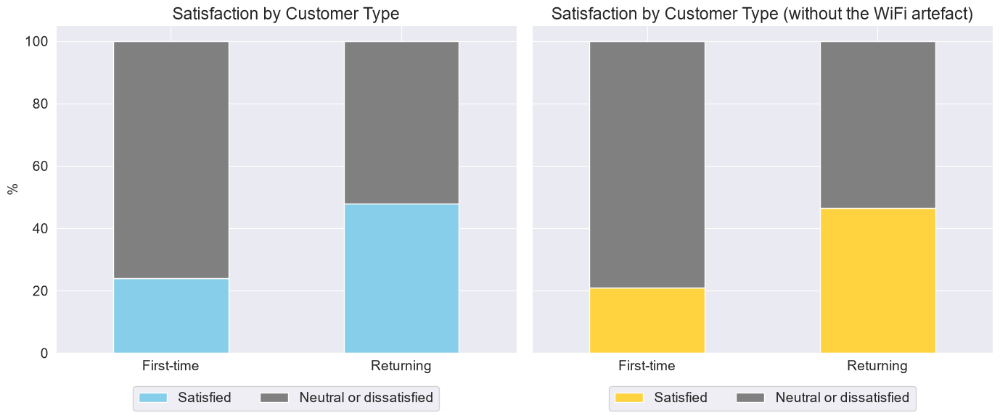

In [946]:
# Sensitivity analysis with and without the wifi artifact - satisfaction by customer type

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

for ax, data, color, title in [
    (axes[0], df_clean, sky_blue, 'Satisfaction by Customer Type'),
    (axes[1], df_sens, sunny_yellow, 'Satisfaction by Customer Type (without the WiFi artefact)'),
]:
    ct = pd.crosstab(data['customer_type'], data['is_satisfied'], normalize='index') * 100
    ct = ct.reindex(columns=[True, False])

    ct.plot(kind='bar', stacked=True, color=[color, 'gray'], ax=ax, legend=False)

    ax.set_title(title)
    ax.set_ylabel('%')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=0)
    ax.legend(['Satisfied', 'Neutral or dissatisfied'], loc='upper center',
              bbox_to_anchor=(0.5, -0.08), ncol=2)

plt.tight_layout();

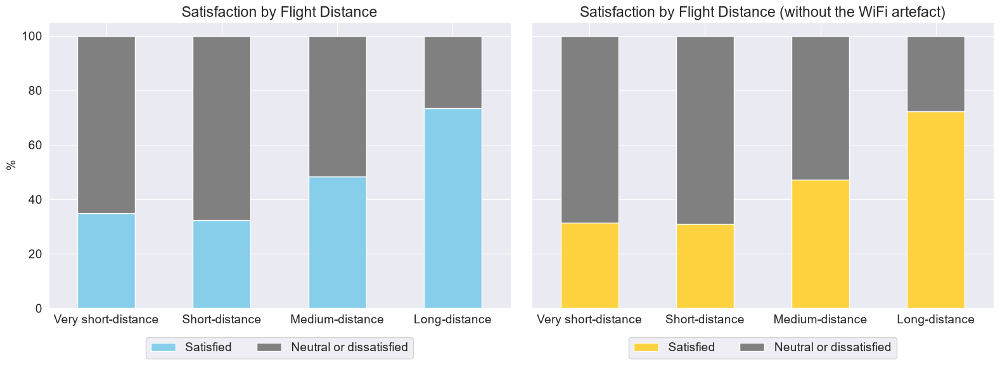

In [947]:
# Sensitivity analysis with and without the wifi artifact - satisfaction by flight distance

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

for ax, data, color, title in [
    (axes[0], df_clean, sky_blue, 'Satisfaction by Flight Distance'),
    (axes[1], df_sens, sunny_yellow, 'Satisfaction by Flight Distance (without the WiFi artefact)'),
]:
    ct = pd.crosstab(data['distance_category'], data['is_satisfied'], normalize='index') * 100
    ct = ct.reindex(columns=[True, False])

    ct.plot(kind='bar', stacked=True, color=[color, 'gray'], ax=ax, legend=False)

    ax.set_title(title)
    ax.set_ylabel('%')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=0)
    ax.legend(['Satisfied', 'Neutral or dissatisfied'], loc='upper center',
              bbox_to_anchor=(0.5, -0.08), ncol=2)

plt.tight_layout();

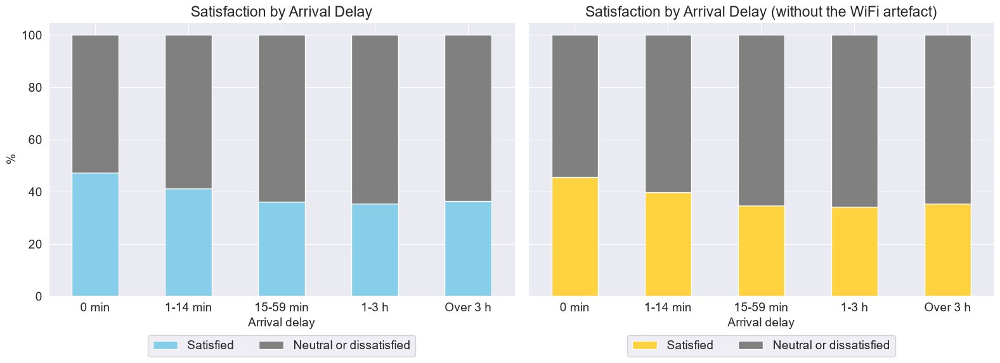

In [948]:
# Sensitivity analysis with and without the wifi artifact - satisfaction by arrival delay

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

for ax, data, color, title in [
    (axes[0], df_clean, sky_blue, 'Satisfaction by Arrival Delay'),
    (axes[1], df_sens, sunny_yellow, 'Satisfaction by Arrival Delay (without the WiFi artefact)'),
]:
    ct = pd.crosstab(data['arrival_delay_category'], data['is_satisfied'], normalize='index') * 100
    ct = ct.reindex(columns=[True, False])

    ct.plot(kind='bar', stacked=True, color=[color, 'gray'], ax=ax, legend=False)

    ax.set_title(title)
    ax.set_ylabel('%')
    ax.set_xlabel('Arrival delay')
    ax.tick_params(axis='x', rotation=0)
    ax.legend(['Satisfied', 'Neutral or dissatisfied'], loc='upper center',
              bbox_to_anchor=(0.5, -0.12), ncol=2)

plt.tight_layout();

### Überprüfe die Ergebnisse in den Gruppen did_rate_online_booking/boarding - mit und ohne den Wifi-Artefakt

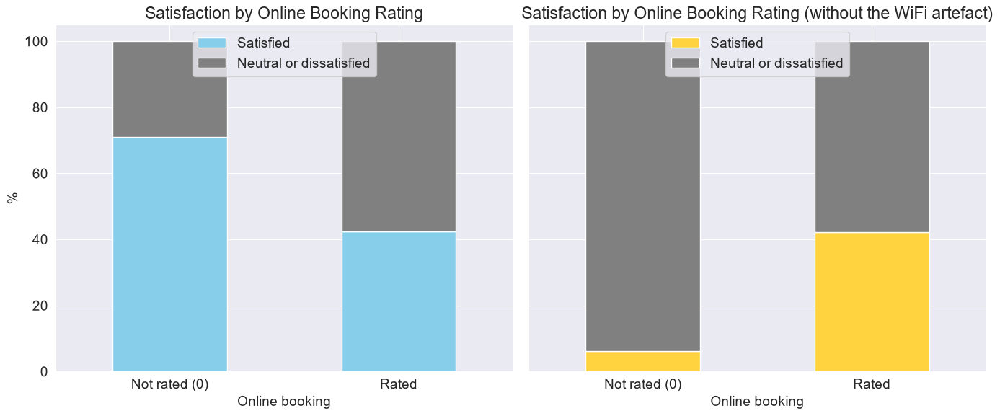

In [951]:
# Sensitivity analysis with and without the wifi artifact - satisfaction by onnline booking rated/not rated

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

for ax, data, color, title in [
    (axes[0], df_clean, sky_blue, 'Satisfaction by Online Booking Rating'),
    (axes[1], df_sens, sunny_yellow, 'Satisfaction by Online Booking Rating (without the WiFi artefact)'),
]:
    ct = pd.crosstab(data['did_rate_online_booking'], data['is_satisfied'], normalize='index') * 100
    ct = ct.reindex(columns=[True, False])
    ct.index = ct.index.map({False: 'Not rated (0)', True: 'Rated'})

    ct.plot(kind='bar', stacked=True, color=[color, 'gray'], ax=ax, legend=False)

    ax.set_title(title)
    ax.set_ylabel('%')
    ax.set_xlabel('Online booking')
    ax.tick_params(axis='x', rotation=0)
    ax.legend(['Satisfied', 'Neutral or dissatisfied'], loc='upper center')

plt.tight_layout();

In [975]:
# Count satisfied/dissatisfied passengers by did_rate_online_booking in df_sens
df_sens.groupby('did_rate_online_booking')['is_satisfied'].value_counts()

did_rate_online_booking  is_satisfied
False                    False            1444
                         True               94
True                     False           71533
                         True            52397
Name: count, dtype: int64

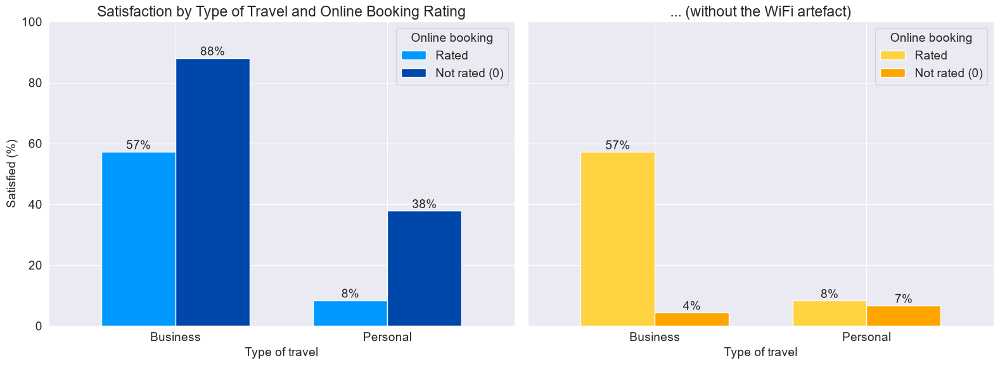

In [955]:
# Sensitivity analysis with and without the wifi artifact - satisfaction by customer type and online booking rated/not rated

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

for ax, data, colors, title in [
    (axes[0], df_clean, [bright_blue, trendy_blue], 'Satisfaction by Type of Travel and Online Booking Rating'),
    (axes[1], df_sens, [sunny_yellow, 'orange'], '... (without the WiFi artefact)'),
]:
    rate = data.groupby(['type_of_travel', 'did_rate_online_booking'])['is_satisfied'].mean().unstack() * 100
    rate = rate.rename(columns={True: 'Rated', False: 'Not rated (0)'})[['Rated', 'Not rated (0)']]

    rate.plot(kind='bar', color=colors, width=0.7, ax=ax, legend=False)
    for container in ax.containers:
        ax.bar_label(container, fmt='%.0f%%')

    ax.set_title(title)
    ax.set_ylabel('Satisfied (%)')
    ax.set_xlabel('Type of travel')
    ax.set_ylim(0, 100)
    ax.tick_params(axis='x', rotation=0)
    ax.legend(title='Online booking')

plt.tight_layout();

In [974]:
# Count satisfied/dissatisied passengers by type of travel and did_rate_online_booking in df_sens
df_sens.groupby(['type_of_travel', 'did_rate_online_booking'])['is_satisfied'].value_counts()

type_of_travel  did_rate_online_booking  is_satisfied
Business        False                    False             389
                                         True               18
                True                     True            49232
                                         False           36820
Personal        False                    False            1055
                                         True               76
                True                     False           34713
                                         True             3165
Name: count, dtype: int64

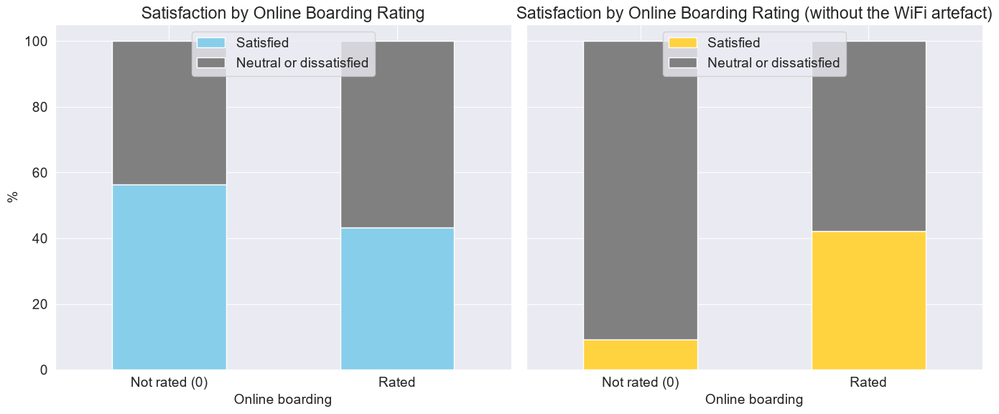

In [957]:
# Sensitivity analysis with and without the wifi artifact - satisfaction by onnline booking rated/not rated

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

for ax, data, color, title in [
    (axes[0], df_clean, sky_blue, 'Satisfaction by Online Boarding Rating'),
    (axes[1], df_sens, sunny_yellow, 'Satisfaction by Online Boarding Rating (without the WiFi artefact)'),
]:
    ct = pd.crosstab(data['did_rate_online_boarding'], data['is_satisfied'], normalize='index') * 100
    ct = ct.reindex(columns=[True, False])
    ct.index = ct.index.map({False: 'Not rated (0)', True: 'Rated'})

    ct.plot(kind='bar', stacked=True, color=[color, 'gray'], ax=ax, legend=False)

    ax.set_title(title)
    ax.set_ylabel('%')
    ax.set_xlabel('Online boarding')
    ax.tick_params(axis='x', rotation=0)
    ax.legend(['Satisfied', 'Neutral or dissatisfied'], loc='upper center')

plt.tight_layout();

In [973]:
# Count satisfied/dissatisfied passengers by did_rate_online_boarding in df_sens
df_sens.groupby('did_rate_online_boarding')['is_satisfied'].value_counts()

did_rate_online_boarding  is_satisfied
False                     False            1341
                          True              136
True                      False           71636
                          True            52355
Name: count, dtype: int64

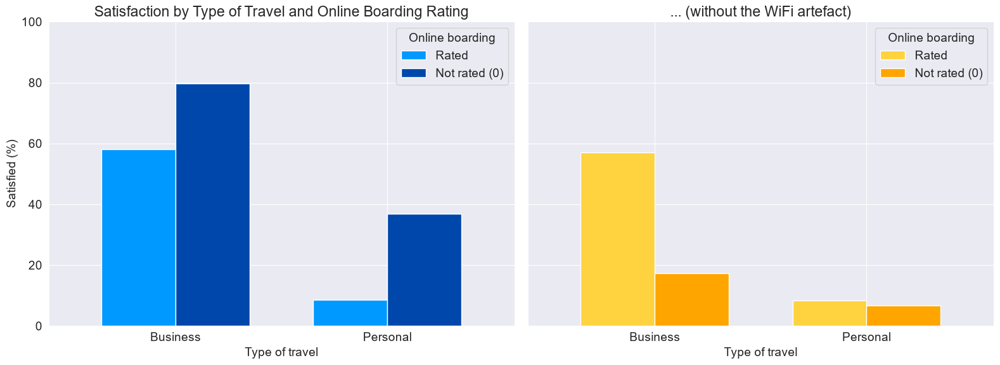

In [965]:
# Sensitivity analysis with and without the wifi artifact - satisfaction by customer type and online boarding rated/not rated

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

for ax, data, colors, title in [
    (axes[0], df_clean, [bright_blue, trendy_blue], 'Satisfaction by Type of Travel and Online Boarding Rating'),
    (axes[1], df_sens, [sunny_yellow, 'orange'], '... (without the WiFi artefact)'),
]:
    rate = data.groupby(['type_of_travel', 'did_rate_online_boarding'])['is_satisfied'].mean().unstack() * 100
    rate = rate.rename(columns={True: 'Rated', False: 'Not rated (0)'})[['Rated', 'Not rated (0)']]

    rate.plot(kind='bar', color=colors, width=0.7, ax=ax, legend=False)

    ax.set_title(title)
    ax.set_ylabel('Satisfied (%)')
    ax.set_xlabel('Type of travel')
    ax.set_ylim(0, 100)
    ax.tick_params(axis='x', rotation=0)
    ax.legend(title='Online boarding')

plt.tight_layout();

In [972]:
# Count satisfied/dissatisfied passengers by type of travel and did_rate_online_boarding in df_sens
df_sens.groupby(['type_of_travel', 'did_rate_online_boarding'])['is_satisfied'].value_counts()

type_of_travel  did_rate_online_boarding  is_satisfied
Business        False                     False             286
                                          True               60
                True                      True            49190
                                          False           36923
Personal        False                     False            1055
                                          True               76
                True                      False           34713
                                          True             3165
Name: count, dtype: int64

In [988]:
# Count passengers who did not rate rate online booking, online boarding by type of travel

cols = ['did_rate_online_booking', 'did_rate_online_boarding']

print('Passengers who did not rate online booking or online boarding (0="not applicable")')
(~df_sens[cols]).groupby(df_sens['type_of_travel']).sum()

Passengers who did not rate online booking or online boarding (0="not applicable")


,did_rate_online_booking,did_rate_online_boarding
type_of_travel,,
Business,407,346
Personal,1131,1131


## Zwischenergebnis: geringere Zufriedenheit von Geschäftsreisenden ohne Bewertung von Online Booking bzw. Online Boarding - ohne die vom Wifi-Artefakt betroffenen Datensätze (3.675)

1. Geschäftsreisende, die Online Booking oder Online Boarding nicht bewertet haben, sind deutlich weniger zufrieden als Geschäftsreisende insgesamt:
    - Online Booking nicht bewertet: nur 4% zufrieden
    - Online Boarding nicht bewertet: unter 20% zufrieden
    - Geschäftsreisende insgesamt: knapp 60% zufrieden
2. Da nur wenige Geschäftsreisende Online Booking (407) bzw. Online Boarding (346) nicht bewertet haben, wird dieser Befund nicht weiter vertieft.

### Überprüfe die Ergbebnisse in der Gruppe did_rate_time_convenience - mit und ohne den Wifi-Artefact

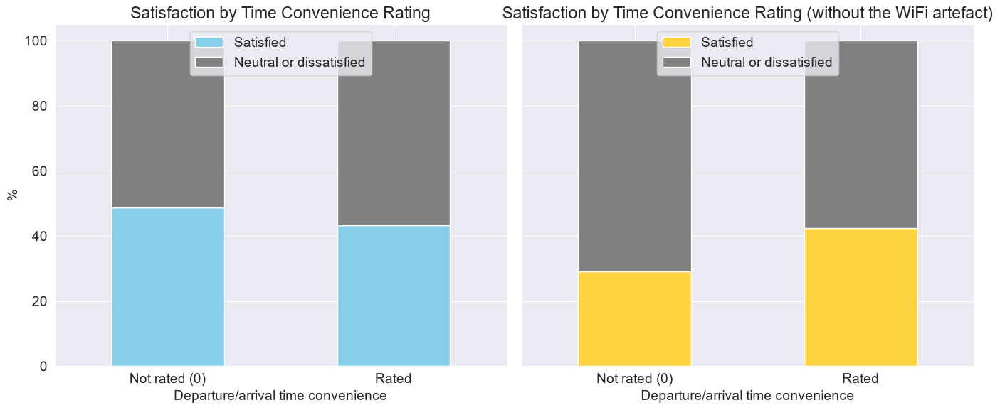

In [964]:
# Sensitivity analysis with and without the wifi artifact - satisfaction by time convenience rated/not rated

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

for ax, data, color, title in [
    (axes[0], df_clean, sky_blue, 'Satisfaction by Time Convenience Rating'),
    (axes[1], df_sens, sunny_yellow, 'Satisfaction by Time Convenience Rating (without the WiFi artefact)'),
]:
    ct = pd.crosstab(data['did_rate_time_convenience'], data['is_satisfied'], normalize='index') * 100
    ct = ct.reindex(columns=[True, False])
    ct.index = ct.index.map({False: 'Not rated (0)', True: 'Rated'})

    ct.plot(kind='bar', stacked=True, color=[color, 'gray'], ax=ax, legend=False)

    ax.set_title(title)
    ax.set_ylabel('%')
    ax.set_xlabel('Departure/arrival time convenience')
    ax.tick_params(axis='x', rotation=0)
    ax.legend(['Satisfied', 'Neutral or dissatisfied'], loc='upper center')

plt.tight_layout();

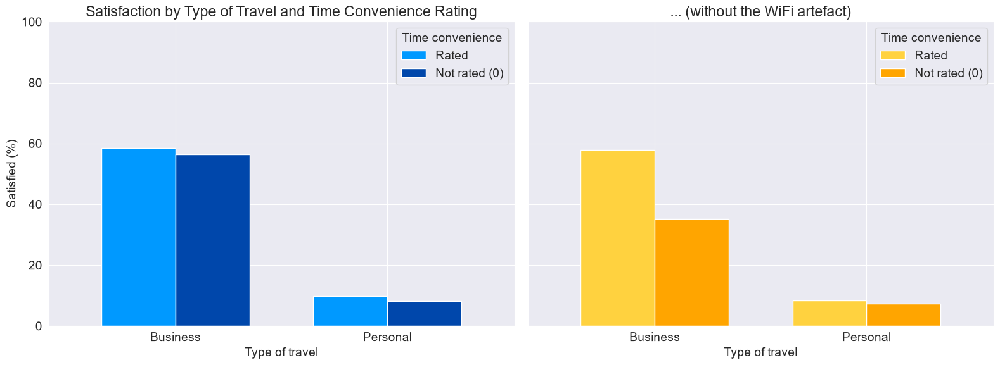

In [963]:
# Sensitivity analysis with and without the wifi artifact - satisfaction by customer type and time convenience rated/not rated

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

for ax, data, colors, title in [
    (axes[0], df_clean, [bright_blue, trendy_blue], 'Satisfaction by Type of Travel and Time Convenience Rating'),
    (axes[1], df_sens, [sunny_yellow, 'orange'], '... (without the WiFi artefact)'),
]:
    rate = data.groupby(['type_of_travel', 'did_rate_time_convenience'])['is_satisfied'].mean().unstack() * 100
    rate = rate.rename(columns={True: 'Rated', False: 'Not rated (0)'})[['Rated', 'Not rated (0)']]

    rate.plot(kind='bar', color=colors, width=0.7, ax=ax, legend=False)

    ax.set_title(title)
    ax.set_ylabel('Satisfied (%)')
    ax.set_xlabel('Type of travel')
    ax.set_ylim(0, 100)
    ax.tick_params(axis='x', rotation=0)
    ax.legend(title='Time convenience')

plt.tight_layout();

In [984]:
# Count passengers who did NOT rate time convenience by type of travel

print('Passengers who did not rate time convenience (0="not applicable")')
(~df_sens['did_rate_time_convenience']).groupby(df_sens['type_of_travel']).sum()

Passengers who did not rate time convenience (0="not applicable")


type_of_travel
Business    3689
Personal    1027
Name: did_rate_time_convenience, dtype: int64

### Check class and customer type of the business passengers who did not rate time convenience

In [979]:
# Check class and customer type of the business passengers who did not rate time convenience

business = df_sens[df_sens['type_of_travel'] == 'Business']
business.groupby('did_rate_time_convenience')[['class_num', 'is_returning']].mean()

,class_num,is_returning
did_rate_time_convenience,,
False,0.693684,0.037409
True,1.402138,0.768721


### -> Mostly Economy (0) or Economy Plus (1) (class_num mean 0,69)), only 3,7% returning

In [982]:
# A better readable table
business = df_sens[df_sens['type_of_travel'] == 'Business']

pd.concat([
    pd.crosstab(business['did_rate_time_convenience'], business['class'], normalize='index'),
    pd.crosstab(business['did_rate_time_convenience'], business['customer_type'], normalize='index'),
], axis=1).mul(100).round(1).rename(index={False: 'Not rated (0)', True: 'Rated'})

,Business,Economy,Economy Plus,First-time,Returning
did_rate_time_convenience,,,,,
Not rated (0),33.4,64.0,2.6,96.3,3.7
Rated,67.3,27.1,5.6,23.1,76.9


### -> From the business travellers who did not rate time convenience: only 33% business class, only 3,7% returning, 96% first-time 

Economy/Economy plus and first-time customers are generally less satisfied, as seen earlier --> that could be the explanation of the low satisfaction among the business travellers here

## Zwischenergebnis: geringere Zufriedenheit von Geschäftsreisenden ohne Bewertung der Time Convenience - ohne die vom Wifi-Artefakt betroffenen Datensätze (3675)

- Geschäftsreisende, die die Time Convenience nicht bewertet haben (3689), sind deutlich weniger zufrieden (ca. 35%) als Geschäftsreisende insgesamt (knapp 60%). Sie flogen überwiegend Economy oder Economy Plus, und nur etwa 4% von ihnen waren wiederkehrende Kunden. Die geringe Zufriedenheit dieser Gruppe lässt sich daher eher durch Reiseklasse und Kundentyp erklären als durch die fehlende Bewertung - wie bereits gesehen, sind Neukunden auf Geschäftsreise sowie Geschäftsreisende in Economy/Economy Plus generell weniger zufrieden. Dieser Befund wird nicht weiter vertieft.

# --> Neuer Umfang ohne den WiFi-Artefakt: 125.468 rows
- 3.675 Fluggäste ausgeschlossen (WiFi-Artefakt: 100% Zufriedenheit im Fall Wifi-Service 0="nicht zutreffend", auch beim Reisezweck 'Personal', wo die Zufriedenheitsquote ansonsten sehr niedrig ist).
- Andere Ergebnisse bisher laut der Sensitivitätsanalyse vom WiFi-Artefakt größtenteils nicht betroffen (Zufriedenheitsverteilung nach Geschlecht, Alter, Reisezweck, Reiseklasse, etc.). Auffälligkeiten in den Segmenten Online Booking/Online Boarding 0="nicht zutreffend" + Reisezweck Business wurden ignoriert, da Segmentgröße verschweigend gering. Auffälligkeit im Segment Time Convenience 0="nicht zutreffend" + Reisezweck Business wurde ignoriert, da Erklärung durch andere Faktoren (Kundentyp und Reiseklasse) plausibel.

Dataframe für die weitere Analyse: df_sens

## Angepasste Ergebnisse zu Frage 1:

### Zufriedenheitsverteilung - ohne WLAN-Artefakt (125.468 Fluggäste)

Insgesamt: 41,8% der Fluggäste sind zufrieden, 58,2% neutral oder unzufrieden.

Nach Merkmalen:
- Geschlecht: kein relevanter Unterschied (Frauen 41,3 %, Männer 42,4 %)
- Alter:
  - Am zufriedensten sind die 45- bis 54-Jährigen (ca.57 %), gefolgt von 35–44 und 55–64 (ca. 48–49 %)
  - Deutlich weniger zufrieden sind Kinder und Jugendliche (ca. 11–17%) sowie Fluggäste ab 65 (ca. 16–27%)
- Reisezweck: größter Unterschied im Datensatz. Geschäftsreisende sind zu 57% zufrieden, Privatreisende nur zu 8 %
- Reiseklasse: Business Class ca. 68%, Economy Plus ca. 23%, Economy ca. 17%
- Kundentyp: Wiederkehrende ca. 47%, Neukunden ca. 20%
- Flugstrecke: Die Zufriedenheit steigt mit der Strecke, von ca. 30% (sehr kurz und kurz) über ca. 47% (Mittelstrecke) bis ca. 72% (Langstrecke). Dieser Effekt hängt eng mit der Reiseklasse zusammen, da Langstrecken fast ausschließlich in der Business Class geflogen werden.
- Ankunftsverspätung: Die Zufriedenheit sinkt von ca. 46% (pünktlich) auf ca. 35% ab etwa 15 Minuten Verspätung und bleibt danach stabil.

Sensitivitätsanalyse: Gegenüber dem Datensatz mit Wifi-Artefakt ändern sich die Anteile nur um 1-2 Prozentpunkte. Die Muster bleiben in allen Merkmalen gleich. Das Artefakt verzerrt also nicht die Zufriedenheitsverteilung insgesamt, sondern vor allem die Ergebnisse zu den Kategorien "nicht bewertet" (Online Booking, Online Boarding, Time Convenience).

# 3.2 Identifizierung von Kundensegmenten

## Frage 2: Identifizierung von Kundensegmenten. Gibt es besonders zufriedene oder besonders unzufriedene Kunden?

In [553]:
# Use DecisionTreeClassifier to identify customer segments that are most satisfied and least satisfied

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

features = ['age', 'is_female', 'is_returning', 'purpose_is_business', 'class_num', 'flight_distance']

X = df_sens[features]
y = df_sens['is_satisfied']

tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=1000,
                              min_impurity_decrease=0.001, random_state=42)
tree.fit(X, y)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1000
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.001
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively insp

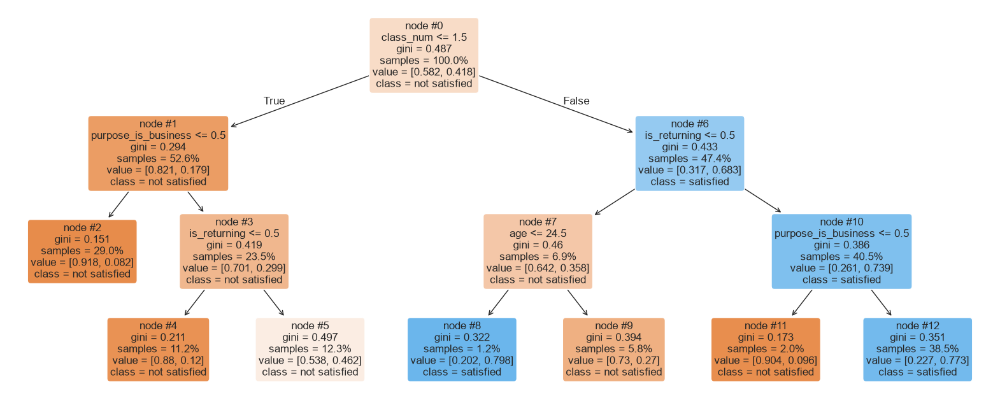

In [554]:
# Plot
plt.figure(figsize=(20, 8))
plot_tree(tree, feature_names=features, class_names=['not satisfied', 'satisfied'],
          filled=True, proportion=True, rounded=True, fontsize=12, node_ids=True)
plt.show()

In [557]:
# Segments as a table, sorted by satisfaction
df_seg = df_sens.assign(segment=tree.apply(X))
df_seg.groupby('segment').agg(passengers=('is_satisfied', 'size'),
                              satisfied=('is_satisfied', 'mean')).sort_values('satisfied', ascending=False)

,passengers,satisfied
segment,,
8,1448,0.798343
12,48282,0.772793
5,15483,0.461668
9,7230,0.270263
4,14029,0.119752
11,2560,0.095703
2,36436,0.082226


In [565]:
# Add column sample_size_%
seg = df_seg.groupby('segment').agg(passengers=('is_satisfied', 'size'),
                                    satisfied=('is_satisfied', 'mean'))
seg['sample_size_%'] = (seg['passengers'] / seg['passengers'].sum() * 100).round(1)
seg = seg.sort_values('satisfied', ascending=False)
seg

,passengers,satisfied,sample_size_%
segment,,,
8,1448,0.798343,1.2
12,48282,0.772793,38.5
5,15483,0.461668,12.3
9,7230,0.270263,5.8
4,14029,0.119752,11.2
11,2560,0.095703,2.0
2,36436,0.082226,29.0


In [566]:
# Display satisfied in % and rename column into 'satisfied_%'
seg['satisfied'] = (seg['satisfied'] * 100).round(1)
seg = seg.rename(columns={'satisfied': 'satisfied_%'})
seg

,passengers,satisfied_%,sample_size_%
segment,,,
8,1448,79.8,1.2
12,48282,77.3,38.5
5,15483,46.2,12.3
9,7230,27.0,5.8
4,14029,12.0,11.2
11,2560,9.6,2.0
2,36436,8.2,29.0


In [567]:
# Add column 'description'
descriptions = {
    2:  'Economy/Economy Plus, personal trip',
    4:  'Economy/Economy Plus, business trip, first-time',
    5:  'Economy/Economy Plus, business trip, returning',
    8:  'Business Class, first-time, age <= 24',
    9:  'Business Class, first-time, age > 24',
    11: 'Business Class, returning, personal trip',
    12: 'Business Class, returning, business trip',
}

seg['description'] = seg.index.map(descriptions)
seg

,passengers,satisfied_%,sample_size_%,description
segment,,,,
8,1448,79.8,1.2,"Business Class, first-time, age <= 24"
12,48282,77.3,38.5,"Business Class, returning, business trip"
5,15483,46.2,12.3,"Economy/Economy Plus, business trip, returning"
9,7230,27.0,5.8,"Business Class, first-time, age > 24"
4,14029,12.0,11.2,"Economy/Economy Plus, business trip, first-time"
11,2560,9.6,2.0,"Business Class, returning, personal trip"
2,36436,8.2,29.0,"Economy/Economy Plus, personal trip"


## Erkenntnisse zu Frage 2: 

### Zufriedenste und am wenigsten zufriedene Segmente

1. Zufriedenstes Segment relevanter Größe (38,5%): Stammkunden auf Geschäftsreise in der Business Class (ca. 77% zufrieden)
2. Am wenigsten zufriedenes Segment (29%): Privatreisende in Economy/Economy Plus (nur ca. 8% zufrieden) → Warum ist diese Gruppe so unzufrieden? Was könnte helfen?
3. Eigentlich das zufriedenste Segment, aber sehr klein (1,2%) und daher nur zur Dokumentation: Erstkunden bis 24 Jahre in der Business Class (ca. 80% zufrieden)
4. Überraschend unzufrieden (unter 10 %), aber sehr klein (2%) und daher nur zur Dokumentation: Wiederkehrende Kunden in der Business Class auf Privatreise

#### Segmente mit unzureichender Zufriedenheit, die eine genauere Betrachtung lohnen:

- Wiederkehrende Kunden auf Geschäftsreise in Economy/Economy Plus (ca.12%), ca. 46% zufrieden --> Was könnte die Zufriedenheit dieser Gruppe steigern?
- Neukunden auf Geschäftsreise in Economy/Economy Plus (ca. 11%), 12% zufrieden --> Warum ist diese Gruppe so unzufrieden? Was könnte helfen?
- Neukunden in der Business Class über 24 Jahre (ca. 6 %), 27% zufrieden --> Was könnte die Zufriedenheit dieser Gruppe steigern?

#### Ebenfalls einen Blick wert:
- Geschäfts- vs. Privatreisende (großer Unterschied in der Zufriedenheit, wie zuvor gezeigt und in den Segmenten erneut bestätigt)

## 3.3 Untersuchung des Zusammenhangs zwischen Bewertungen, Fluginformationen und Zufriedenheit
    
### - Welche Faktoren hängen am stärksten mit der Zufriedenheit zusammen, welche kaum? (Frage 3)
### - Unterscheiden sich Kundensegmente darin, welche Faktoren mit ihrer Zufriedenheit zusammenhängen? (Frage 4)

## Ratings vs satisfaction overall

In [585]:
# Create df for correlation analysis with the relevant columns

# Relevant columns
rated_cols = ['departure_and_arrival_time_convenience', 'ease_of_online_booking',
              'checkin_service', 'online_boarding', 'gate_location', 'onboard_service',
              'seat_comfort', 'leg_room_service', 'cleanliness', 'food_and_drink',
              'inflight_service', 'inflight_wifi_service', 'inflight_entertainment',
              'baggage_handling']

passenger_cols = ['age', 'is_returning', 'purpose_is_business', 'class_num']

flight_cols = ['flight_distance', 'arrival_delay_log']

# df_ratings: id + is_satisfied + rated_cols
df_ratings = df_sens[['id', 'is_satisfied'] + rated_cols].copy()

# df_passenger_flight_info_ratings: id + is_satisfied + arrival_delay_log + passenger_cols + rated_cols
df_passenger_flight_info_ratings = df_sens[['id', 'is_satisfied', 'arrival_delay_log'] + passenger_cols + rated_cols].copy()

In [577]:
df_ratings.head(2)

,id,is_satisfied,departure_and_arrival_time_convenience,ease_of_online_booking,checkin_service,online_boarding,gate_location,onboard_service,seat_comfort,leg_room_service,cleanliness,food_and_drink,inflight_service,inflight_wifi_service,inflight_entertainment,baggage_handling
0,1,False,3.0,3.0,4,3.0,3,3,5,2,5,5,5,3.0,5,5
1,2,True,2.0,2.0,3,5.0,2,5,4,5,5,3,5,2.0,5,5


In [582]:
df_passenger_flight_info_ratings.head(2)

,id,is_satisfied,arrival_delay_log,age,is_returning,purpose_is_business,class_num,departure_and_arrival_time_convenience,ease_of_online_booking,checkin_service,...,gate_location,onboard_service,seat_comfort,leg_room_service,cleanliness,food_and_drink,inflight_service,inflight_wifi_service,inflight_entertainment,baggage_handling
0,1,False,1.791759,48,False,True,2,3.0,3.0,4,...,3,3,5,2,5,5,5,3.0,5,5
1,2,True,3.688879,35,True,True,2,2.0,2.0,3,...,2,5,4,5,5,3,5,2.0,5,5


In [583]:
# Correlations between rated categories and satisfaction
df_ratings.drop(columns='id').corr(method='spearman')

,is_satisfied,departure_and_arrival_time_convenience,ease_of_online_booking,checkin_service,online_boarding,gate_location,onboard_service,seat_comfort,leg_room_service,cleanliness,food_and_drink,inflight_service,inflight_wifi_service,inflight_entertainment,baggage_handling
is_satisfied,1.000000,-0.057962,0.235983,0.234968,0.596911,0.001291,0.343979,0.372936,0.335977,0.315043,0.216353,0.280673,0.371110,0.422110,0.286265
departure_and_arrival_time_convenience,-0.057962,1.000000,0.506044,0.119329,0.056731,0.506796,0.078590,-0.006803,-0.005452,0.002386,-0.008727,0.105734,0.373489,-0.032687,0.102709
ease_of_online_booking,0.235983,0.506044,1.000000,0.018679,0.352764,0.500573,0.033928,0.025918,0.079240,0.013765,0.026063,0.030089,0.689338,0.030515,0.030489
checkin_service,0.234968,0.119329,0.018679,1.000000,0.228848,-0.039400,0.242087,0.197486,0.150789,0.172498,0.082098,0.257145,0.056958,0.126013,0.253767
online_boarding,0.596911,0.056731,0.352764,0.228848,1.000000,-0.003136,0.188556,0.446188,0.146887,0.353260,0.249408,0.125276,0.447985,0.314952,0.136069
gate_location,0.001291,0.506796,0.500573,-0.039400,-0.003136,1.000000,-0.030095,0.001812,-0.005322,-0.004508,-0.002282,-0.009104,0.351907,0.002228,-0.008595
onboard_service,0.343979,0.078590,0.033928,0.242087,0.188556,-0.030095,1.000000,0.152763,0.364731,0.128981,0.058724,0.565694,0.118925,0.431534,0.536664
seat_comfort,0.372936,-0.006803,0.025918,0.197486,0.446188,0.001812,0.152763,1.000000,0.125326,0.670575,0.561445,0.105365,0.130544,0.613925,0.113239
leg_room_service,0.335977,-0.005452,0.079240,0.150789,0.146887,-0.005322,0.364731,0.125326,1.000000,0.101602,0.034014,0.371494,0.144543,0.312865,0.370057
cleanliness,0.315043,0.002386,0.013765,0.172498,0.353260,-0.004508,0.128981,0.670575,0.101602,1.000000,0.650662,0.107826,0.139937,0.688940,0.115357


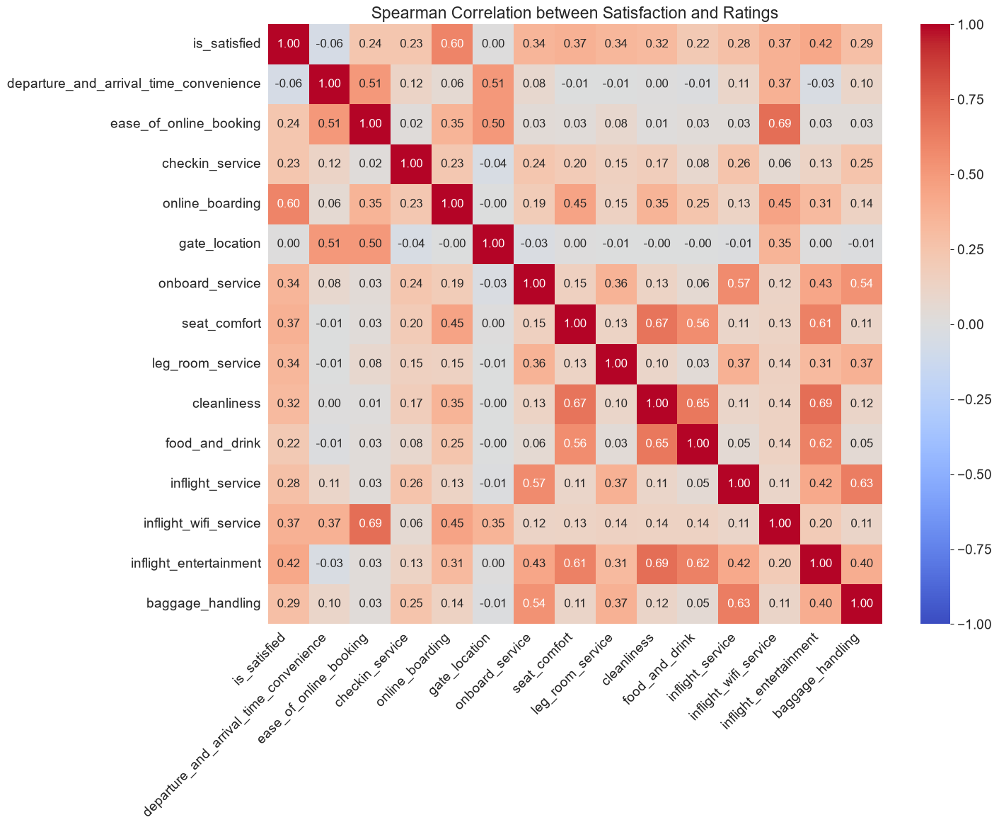

In [598]:
# Visualize correlations between rated categories and satisfaction
corr_ratings = df_ratings.drop(columns='id').corr(method='spearman')

plt.figure(figsize=(14, 11))
sns.heatmap(corr_ratings, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, annot_kws={'size': 12})
plt.title('Spearman Correlation between Satisfaction and Ratings')
plt.xticks(rotation=45, ha='right');

In [584]:
# Correlations between satisfaction, passenger information, delay and rated categories
df_passenger_flight_info_ratings.drop(columns='id').corr(method='spearman')

,is_satisfied,arrival_delay_log,age,is_returning,purpose_is_business,class_num,departure_and_arrival_time_convenience,ease_of_online_booking,checkin_service,online_boarding,gate_location,onboard_service,seat_comfort,leg_room_service,cleanliness,food_and_drink,inflight_service,inflight_wifi_service,inflight_entertainment,baggage_handling
is_satisfied,1.000000,-0.096354,0.155885,0.199109,0.456541,0.500441,-0.057962,0.235983,0.234968,0.596911,0.001291,0.343979,0.372936,0.335977,0.315043,0.216353,0.280673,0.371110,0.422110,0.286265
arrival_delay_log,-0.096354,1.000000,-0.011967,-0.006557,0.006768,-0.017114,-0.012757,-0.024209,-0.035357,-0.058287,0.006696,-0.050530,-0.037914,-0.023346,-0.032207,-0.030242,-0.059695,-0.048461,-0.047217,-0.038541
age,0.155885,-0.011967,1.000000,0.298454,0.042238,0.144141,-0.009871,0.012487,0.039660,0.191930,-0.001770,0.076149,0.156171,0.060216,0.049424,0.018359,-0.027549,0.011175,0.081980,-0.019521
is_returning,0.199109,-0.006557,0.298454,1.000000,-0.308563,0.109534,0.110718,0.014805,0.035481,0.182263,-0.006696,0.065333,0.146562,0.056922,0.076642,0.054366,-0.005760,-0.001895,0.106068,-0.004096
purpose_is_business,0.456541,0.006768,0.042238,-0.308563,1.000000,0.542604,-0.263034,0.128230,-0.019720,0.220658,0.031831,0.062878,0.122888,0.137416,0.081189,0.066635,0.016996,0.122838,0.152492,0.026314
class_num,0.500441,-0.017114,0.144141,0.109534,0.542604,1.000000,-0.125270,0.115753,0.145149,0.330199,0.006334,0.218298,0.225431,0.210569,0.134492,0.085122,0.171120,0.055943,0.200914,0.178221
departure_and_arrival_time_convenience,-0.057962,-0.012757,-0.009871,0.110718,-0.263034,-0.125270,1.000000,0.506044,0.119329,0.056731,0.506796,0.078590,-0.006803,-0.005452,0.002386,-0.008727,0.105734,0.373489,-0.032687,0.102709
ease_of_online_booking,0.235983,-0.024209,0.012487,0.014805,0.128230,0.115753,0.506044,1.000000,0.018679,0.352764,0.500573,0.033928,0.025918,0.079240,0.013765,0.026063,0.030089,0.689338,0.030515,0.030489
checkin_service,0.234968,-0.035357,0.039660,0.035481,-0.019720,0.145149,0.119329,0.018679,1.000000,0.228848,-0.039400,0.242087,0.197486,0.150789,0.172498,0.082098,0.257145,0.056958,0.126013,0.253767
online_boarding,0.596911,-0.058287,0.191930,0.182263,0.220658,0.330199,0.056731,0.352764,0.228848,1.000000,-0.003136,0.188556,0.446188,0.146887,0.353260,0.249408,0.125276,0.447985,0.314952,0.136069


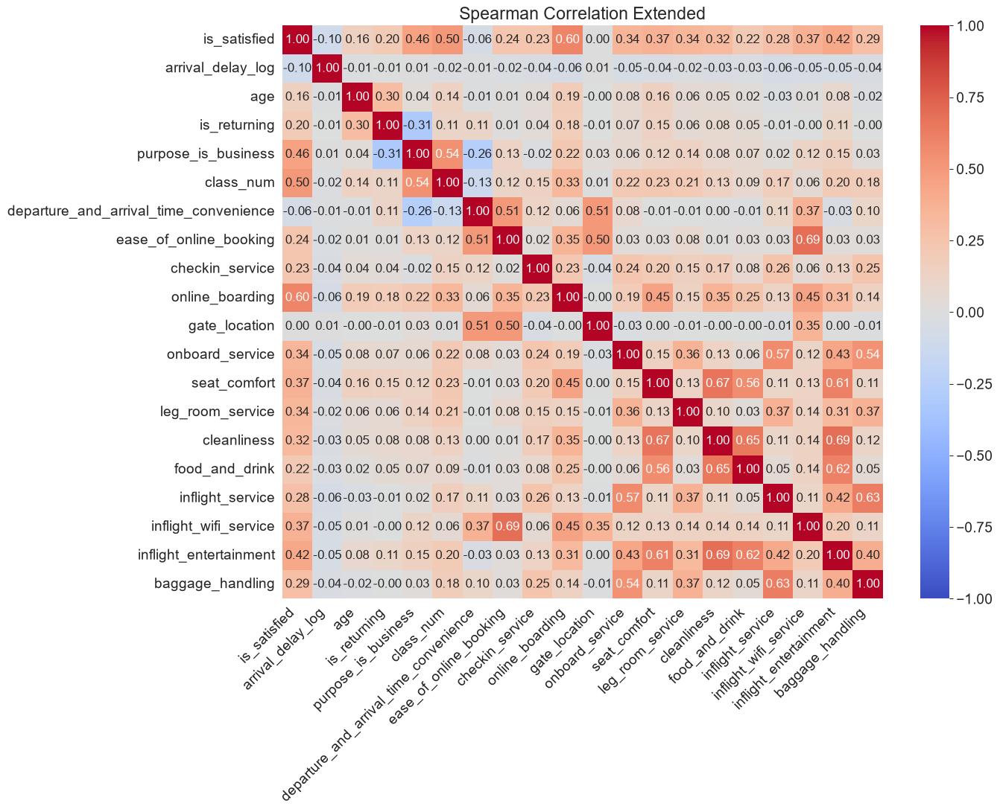

In [601]:
# Visualize correlations between satisfaction, passenger information, delay and rated categories
corr_ratings_extended = df_passenger_flight_info_ratings.drop(columns='id').corr(method='spearman')

plt.figure(figsize=(13, 10))
sns.heatmap(corr_ratings_extended, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, annot_kws={'size': 12})
plt.title('Spearman Correlation Extended')
plt.xticks(rotation=45, ha='right');

## Ergebnisse zu Frage 3: 

### Welche Faktoren hängen am stärksten mit der Zufriedenheit zusammen, welche kaum?

### Zusammenhänge zwischen Zufriedenheit und bewerteten Kategorien
- Online Boarding zeigt die höchste positive Korrelation (0,60), gefolgt von der Reiseklasse (0,50)
- Mittlere Korrelationen: Reisezweck (0,46), In-flight Entertainment (0,42), Seat Comfort (0,37), WLAN (0,37), Leg Room (0,34), On-board Service (0,32), Cleanliness (0,32)
- Schwache Korrelationen: Online Booking (0,24), Check-in Service (0,23), Food and Drink (0,22), In-flight Service (0,28), Baggage Handling (0,29)
- Vernachlässigbar: Time Convenience (0,06), Gate Location (0,00)

### Korrelation zwischen Zufriedenheit und weiteren Faktoren:
- Schwach negative Korrelation: Ankunftsverspätung (−0,10)

## Frage 4: Unterscheiden sich Kundensegmente darin, welche Faktoren mit ihrer Zufriedenheit zusammenhängen? 

### Business travellers

In [603]:
# Correlations between satisfaction and ratings, etc. for business travellers
corr_business = df_passenger_flight_info_ratings[df_passenger_flight_info_ratings['purpose_is_business'] == True].drop(
    columns=['id', 'purpose_is_business']).corr(method='spearman')
corr_business

,is_satisfied,arrival_delay_log,age,is_returning,class_num,departure_and_arrival_time_convenience,ease_of_online_booking,checkin_service,online_boarding,gate_location,onboard_service,seat_comfort,leg_room_service,cleanliness,food_and_drink,inflight_service,inflight_wifi_service,inflight_entertainment,baggage_handling
is_satisfied,1.000000,-0.115164,0.224044,0.432032,0.394304,0.088503,0.153824,0.351725,0.648047,-0.016437,0.455686,0.470335,0.371398,0.407321,0.267085,0.397857,0.340634,0.520850,0.401730
arrival_delay_log,-0.115164,1.000000,-0.016682,-0.006150,-0.035975,-0.016465,-0.013539,-0.044942,-0.072335,0.006283,-0.074260,-0.056734,-0.042259,-0.049365,-0.034501,-0.083544,-0.045433,-0.077140,-0.064558
age,0.224044,-0.016682,1.000000,0.439595,0.205977,0.001383,0.015215,0.065720,0.178767,-0.002027,0.145059,0.168617,0.147838,0.046167,0.006423,0.026880,0.012614,0.121763,0.037888
is_returning,0.432032,-0.006150,0.439595,1.000000,0.369508,0.036803,0.070289,0.037009,0.315511,0.006120,0.108923,0.234979,0.125994,0.129254,0.095162,0.000191,0.047561,0.196093,0.006056
class_num,0.394304,-0.035975,0.205977,0.369508,1.000000,0.032134,0.069689,0.249213,0.312009,-0.015051,0.297555,0.240697,0.221450,0.138956,0.074646,0.273307,-0.017442,0.191223,0.276659
departure_and_arrival_time_convenience,0.088503,-0.016465,0.001383,0.036803,0.032134,1.000000,0.765406,0.023098,0.125147,0.767178,0.028736,0.004318,0.009159,0.000843,0.004365,0.027975,0.588116,0.006369,0.030543
ease_of_online_booking,0.153824,-0.013539,0.015215,0.070289,0.069689,0.765406,1.000000,0.028240,0.221211,0.665720,0.033797,0.012997,0.015243,0.003712,0.009664,0.033958,0.613552,0.013181,0.034192
checkin_service,0.351725,-0.044942,0.065720,0.037009,0.249213,0.023098,0.028240,1.000000,0.296931,-0.025034,0.265534,0.254140,0.192978,0.211946,0.114345,0.270552,0.086204,0.194043,0.273797
online_boarding,0.648047,-0.072335,0.178767,0.315511,0.312009,0.125147,0.221211,0.296931,1.000000,-0.013712,0.271714,0.526445,0.207159,0.435967,0.319557,0.220812,0.382523,0.419741,0.231851
gate_location,-0.016437,0.006283,-0.002027,0.006120,-0.015051,0.767178,0.665720,-0.025034,-0.013712,1.000000,-0.021801,-0.003655,-0.006492,-0.004622,-0.006921,-0.008705,0.470549,-0.004249,-0.010591


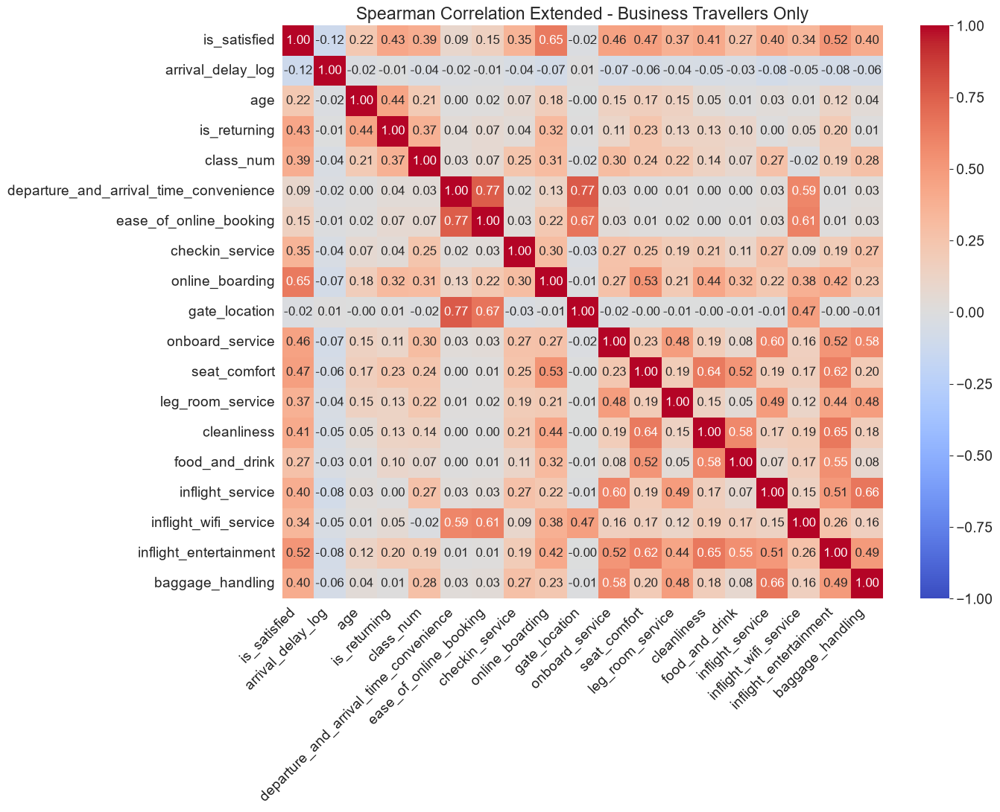

In [604]:
# Visualize correlations between satisfaction, passenger information, delay and rated categories - BUSINESS TRAVELLERS ONLY
plt.figure(figsize=(13, 10))
sns.heatmap(corr_business, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, annot_kws={'size': 12})
plt.title('Spearman Correlation Extended - Business Travellers Only')
plt.xticks(rotation=45, ha='right');

### Personal travellers

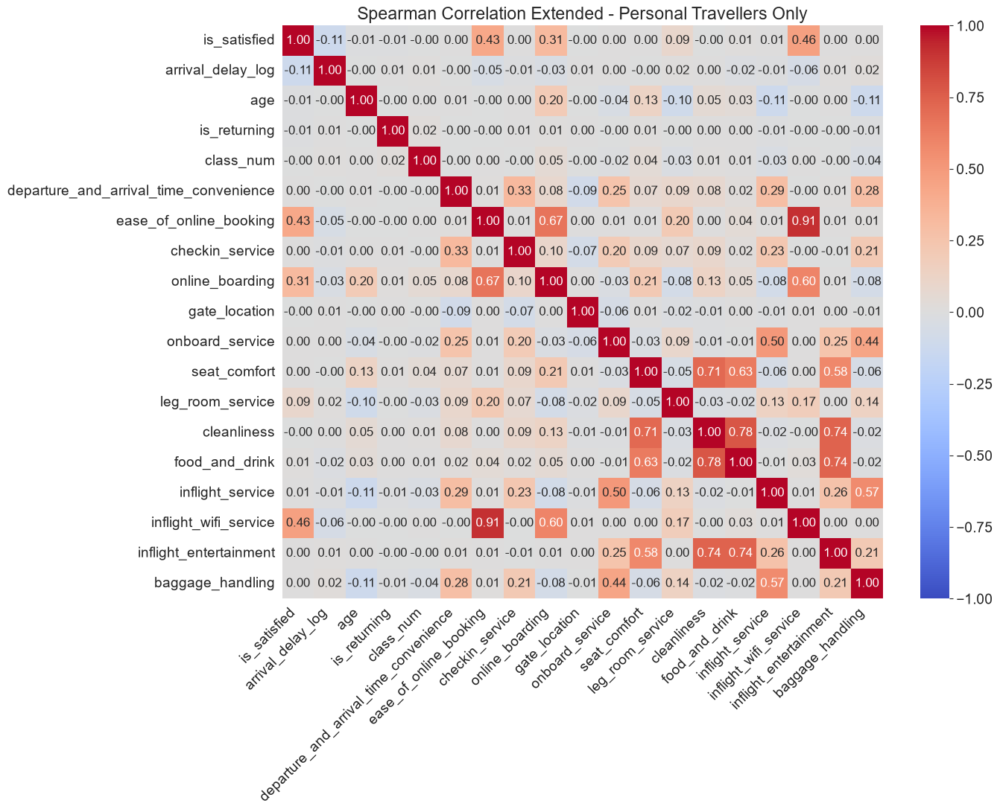

In [605]:
# Correlations between satisfaction and ratings, etc. for personal travellers
corr_personal = df_passenger_flight_info_ratings[df_passenger_flight_info_ratings['purpose_is_business'] == False].drop(
    columns=['id', 'purpose_is_business']).corr(method='spearman')

plt.figure(figsize=(13, 10))
sns.heatmap(corr_personal, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, annot_kws={'size': 12})
plt.title('Spearman Correlation Extended - Personal Travellers Only')
plt.xticks(rotation=45, ha='right');

# ! Auffälliger Korrelationsbefund bei Privatreisenden:

- Bei Privatreisenden besteht zwischen der Zufriedenheit und den meisten Bewertungen keine oder nahezu keine Korrelation
- Nur drei Kategorien zeigen eine mittlere Korrelation: Wifi, Online Booking und Online Boarding

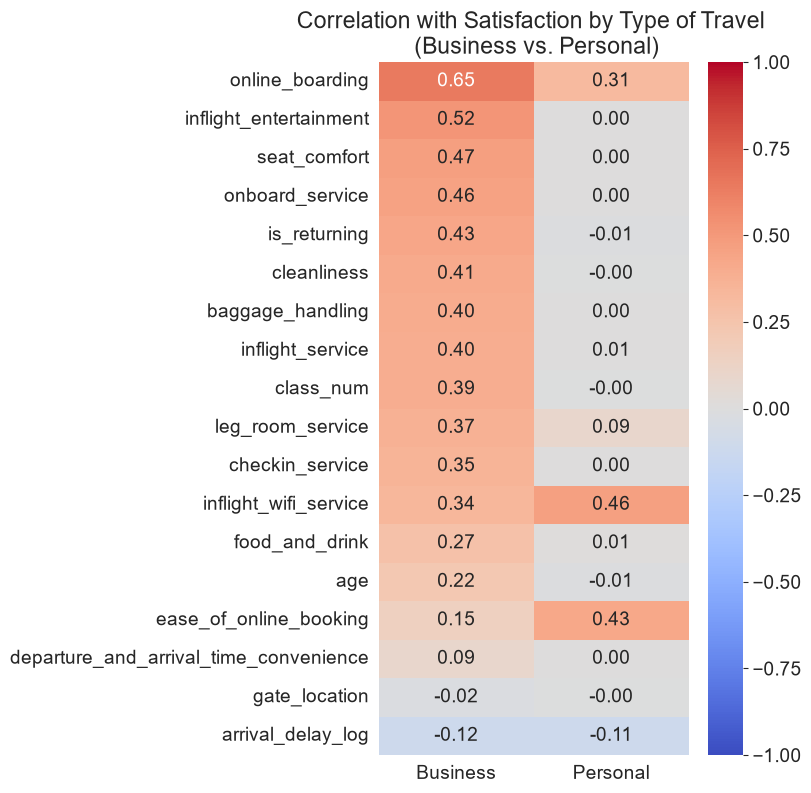

In [1030]:
# Compare correlations between business and personal travellers
sat_corr = pd.DataFrame({
    'Business': corr_business['is_satisfied'],
    'Personal': corr_personal['is_satisfied']
}).drop('is_satisfied').sort_values('Business', ascending=False)

plt.figure(figsize=(5, 9))
sns.heatmap(sat_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation with Satisfaction by Type of Travel \n (Business vs. Personal)')
plt.show()

### Compare ratings of personal vs. business travellers

In [616]:
# Average ratings of business vs. personal travellers
df_sens.groupby('type_of_travel')[rated_cols].mean().round(2).T

type_of_travel,Business,Personal
departure_and_arrival_time_convenience,2.97,3.74
ease_of_online_booking,3.00,2.63
checkin_service,3.28,3.34
online_boarding,3.50,2.91
gate_location,3.01,2.92
onboard_service,3.44,3.27
seat_comfort,3.55,3.18
leg_room_service,3.49,3.11
cleanliness,3.36,3.12
food_and_drink,3.27,3.07


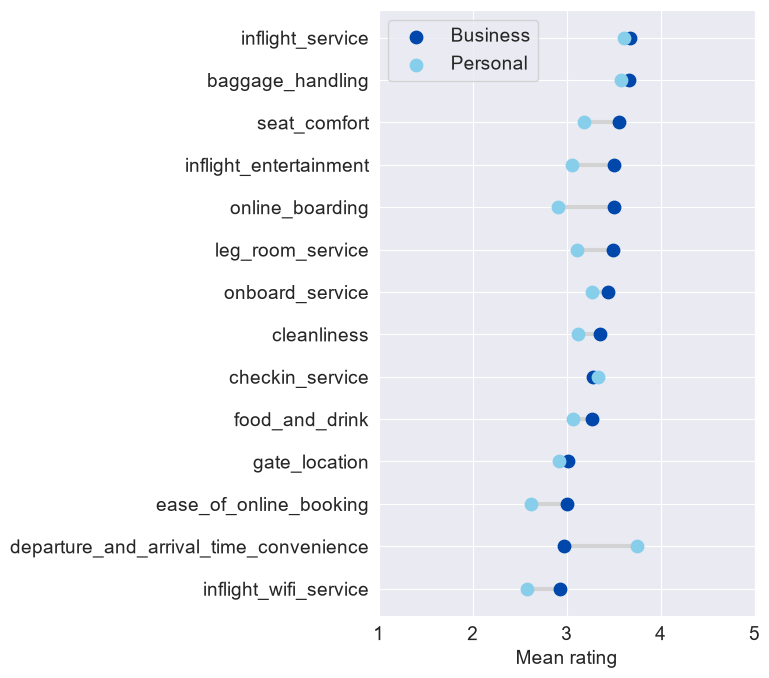

In [628]:
# Compare average ratings among personal and business travellers - dumbbell chart
means = df_sens.groupby('type_of_travel')[rated_cols].mean().T
means = means.sort_values('Business')

fig, ax = plt.subplots(figsize=(8, 7))
ax.hlines(means.index, means['Personal'], means['Business'], color='lightgray', linewidth=3)
ax.scatter(means['Business'], means.index, color=trendy_blue, s=80, label='Business', zorder=3)
ax.scatter(means['Personal'], means.index, color=sky_blue, s=80, label='Personal', zorder=3)
ax.set_xlim(1, 5)
ax.set_xlabel('Mean rating')
ax.legend()
plt.tight_layout();

In [996]:
# Check rating dstribution among personal and business travellers (in %)

for travel in ['Personal', 'Business']:
    d = df_sens.loc[df_sens['type_of_travel'] == travel, rated_cols]
    counts = d.apply(lambda s: s.value_counts(normalize=True)).T.mul(100).round(1)
    counts.columns = counts.columns.astype(int)
    print(travel)
    display(counts)

Personal


,1,2,3,4,5
departure_and_arrival_time_convenience,8.8,9.9,12.1,36.5,32.7
ease_of_online_booking,17.8,29.8,30.1,16.6,5.6
checkin_service,11.9,11.7,27.6,28.4,20.4
online_boarding,14.9,24.1,27.2,22.3,11.4
gate_location,14.8,18.0,34.8,25.2,7.2
onboard_service,13.1,14.0,26.1,26.2,20.6
seat_comfort,16.4,17.3,19.6,24.9,21.8
leg_room_service,11.6,23.8,24.4,21.8,18.4
cleanliness,16.3,18.5,22.4,22.6,20.2
food_and_drink,16.0,21.6,21.6,20.9,19.9


Business


,1,2,3,4,5
departure_and_arrival_time_convenience,19.1,21.3,21.1,20.7,17.8
ease_of_online_booking,17.3,21.8,22.1,21.1,17.7
checkin_service,12.8,12.9,27.2,27.8,19.4
online_boarding,8.5,14.6,19.1,33.7,24.1
gate_location,17.8,19.0,24.1,22.6,16.5
onboard_service,10.5,14.1,20.0,31.7,23.6
seat_comfort,9.5,13.0,17.3,33.2,27.0
leg_room_service,9.0,16.7,17.0,30.7,26.5
cleanliness,11.4,14.2,24.0,27.8,22.6
food_and_drink,10.8,20.8,21.3,24.9,22.2


In [1004]:
# Calculate percentage of 4+ ratings per category per type of travel

top2 = df_sens.groupby('type_of_travel')[rated_cols].agg(
    lambda s: (s.dropna() >= 4).mean() * 100).T.round(1)
top2.sort_values('Business', ascending=False)

type_of_travel,Business,Personal
inflight_service,63.5,61.6
baggage_handling,63.3,60.3
seat_comfort,60.2,46.7
inflight_entertainment,58.3,41.0
online_boarding,57.8,33.7
leg_room_service,57.2,40.2
onboard_service,55.4,46.8
cleanliness,50.4,42.8
checkin_service,47.2,48.8
food_and_drink,47.1,40.8


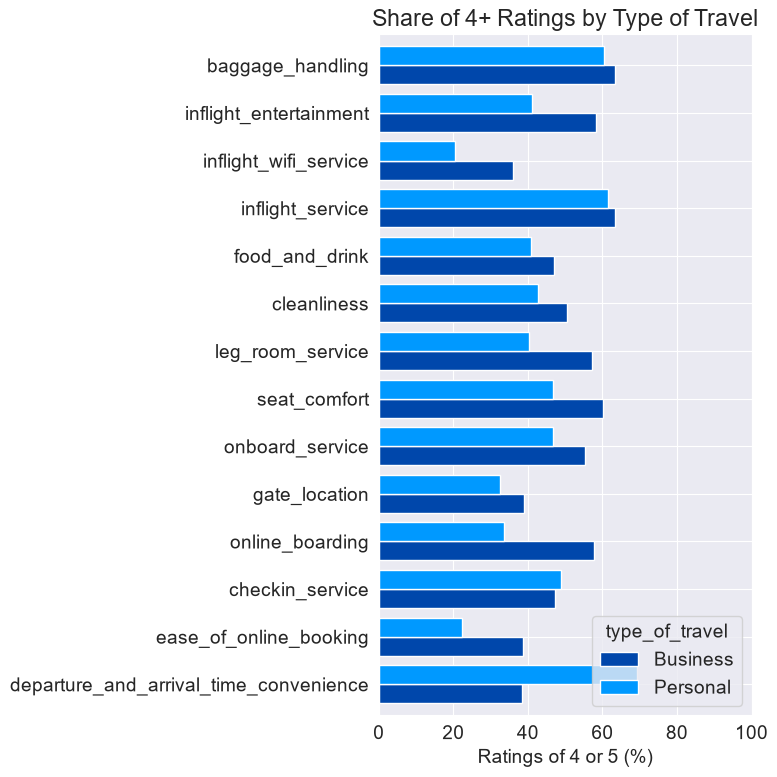

In [1005]:
# Visualize percentage of 4+ ratings per category per type of travel

top2.plot(kind='barh', color=[trendy_blue, bright_blue], figsize=(8, 8), width=0.8)
plt.xlim(0, 100)
plt.xlabel('Ratings of 4 or 5 (%)')
plt.title('Share of 4+ Ratings by Type of Travel')
plt.tight_layout()
plt.show()

In [1056]:
# Show personal travellers's average ratings and correlation between satisfaction & ratings

personal = df_sens[df_sens['type_of_travel'] == 'Personal']

table = pd.DataFrame({
    'correlation': personal[rated_cols].corrwith(personal['is_satisfied'], method='spearman'),
    'mean_rating': personal[rated_cols].mean(),
}).round(2).sort_values('correlation', ascending=False)

print('Personal Travellers: Average Ratings and Correlation with Satisfaction')
table

Personal Travellers: Average Ratings and Correlation with Satisfaction


,correlation,mean_rating
inflight_wifi_service,0.46,2.57
ease_of_online_booking,0.43,2.63
online_boarding,0.31,2.91
leg_room_service,0.09,3.11
food_and_drink,0.01,3.07
inflight_service,0.01,3.61
onboard_service,0.00,3.27
gate_location,-0.00,2.92
checkin_service,0.00,3.34
departure_and_arrival_time_convenience,0.00,3.74


# Ein weiteres Datenartefakt?

### Die Korrelations-Heatmap der Privatreisenden wirkt als reale Daten unplausibel
- Es erscheint unplausibel, dass die Zufriedenheit nur mit Wifi (0,46), Online Booking (0,43) und Online Boarding (0,31) zusammenhängt und von Faktoren wie Verpflegung, Sauberkeit oder Beinfreiheit völlig unbeeinflusst bleibt (alle praktisch 0,00)

### Der Anteil der Bewertungen ab 4 spiegelt die geringe Zufriedenheit der Privatreisenden (9%) nicht wider#

### Privatreisende vergeben zwar in den meisten Kategorien seltener eine 4 oder 5 als Geschäftsreisende, der Anteil ist aber nicht auffallend niedrig
- Einige Kategorien erhalten sogar einen hohen Anteil an Bewertungen ab 4: In-flight Service (über 60%), Baggage Handling (ca. 60%), Time Convenience (ca.70 %)
- Mittlerer Anteil an Bewertungen ab 4: Check-in Service (knapp 50%), Seat Comfort und On-board Service (ca. 45%)
- In-flight Entertainment, Food and Drink, Cleanliness und Leg Room erhalten zu ca. 40% eine 4 oder 5
- Keine dieser gut oder recht gut bewerteten Kategorien (mit Ausnahme der digitalen) scheint die Zufriedenheit der Privatreisenden zu beeinflussen

### Die Frage ist:
- Gibt es andere, nicht erfasste Faktoren, die die Zufriedenheit der Privatreisenden negativ beeinflussen und nicht im Datensatz enthalten sind, etwa Ticketpreise?
- Oder handelt es sich um ein weiteres Datenartefakt?

# Empfehlungen hinsichtlich Reisetyp "personal" (Privatreisende) und weitere Dateneingrenzung
1. Daten überprüfen
   - Wenn synthetisch generiert: Wie wurden die Daten generiert? Evtl. Regeln anpassen, für mehr Realitätsnähe
   - Wenn real: Sind die Daten fehlerfrei? Evtl. Fehler beheben
2. Wenn Daten real und korrekt, könnte es sinnvoll sein, die Kategorien mit dem meisten Impact (hohe Korrelation) und der schwächsten Performance (basierend auf Durchschnittsbewertung) anzugehen und den entsprechenden Service zu verbessern, um die Zufriedenheit der privat Reisenden zu erhöhen. Laut der aktuellen Analyse, hat das Segment "customer type: personal" keine Kategorien mit starker positiven Zufriedenheitskorrelation >= 0,5. Kategorien, die am Nähesten in Frage kommen, wären diese:
   - In-flight WiFi Service (Korrelation 0,46, Durchschnittsbewertung 2,57)
   - Online Booking (Korrelation 0,43, Durchschnittsbewertung 2,63)
   - Online Boarding (Korrelation 0,31, Durchschnittsbewertung 2,91)

Für weitere Analyse im Rahmen des Projektes, wegen Verdacht auf einen Artefakt, werde ich die Privatreisenden ausschließen (39.009 Datensätze).

# --> Neuer Umfang: ***Business*** travellers

In [1231]:
# Count customer type personal
(df_sens['type_of_travel'] == 'Personal').sum()

np.int64(39009)

In [632]:
df_business = df_sens[df_sens['type_of_travel'] == 'Business'].copy()
df_business

,id,gender,age,customer_type,type_of_travel,class,flight_distance,departure_delay,arrival_delay,departure_and_arrival_time_convenience,...,departure_delay_log,arrival_delay_log,is_female,is_returning,purpose_is_business,class_num,did_rate_time_convenience,did_rate_online_booking,did_rate_online_boarding,did_rate_inflight_wifi
0,1,Male,48,First-time,Business,Business,821,2,5,3.0,...,1.098612,1.791759,False,False,True,2,True,True,True,True
1,2,Female,35,Returning,Business,Business,821,26,39,2.0,...,3.295837,3.688879,True,True,True,2,True,True,True,True
2,3,Male,41,Returning,Business,Business,853,0,0,4.0,...,0.000000,0.000000,False,True,True,2,True,True,True,True
3,4,Male,50,Returning,Business,Business,1905,0,0,2.0,...,0.000000,0.000000,False,True,True,2,True,True,True,True
4,5,Female,49,Returning,Business,Business,3470,0,1,3.0,...,0.000000,0.693147,True,True,True,2,True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129867,129868,Male,47,Returning,Business,Economy Plus,447,0,0,4.0,...,0.000000,0.000000,False,True,True,1,True,True,True,True
129868,129869,Female,18,First-time,Business,Economy,337,0,0,NaN,...,0.000000,0.000000,True,False,True,0,False,True,True,True
129869,129870,Male,20,First-time,Business,Economy,447,8,0,2.0,...,2.197225,0.000000,False,False,True,0,True,True,True,True
129870,129871,Female,23,First-time,Business,Business,337,46,58,2.0,...,3.850148,4.077537,True,False,True,2,True,True,True,True


### Anzahl underage Geschäftsreisender überprüfen

In [654]:
len(df_business[df_business['age'] < 18])

2739

In [656]:
# Calculate %-share of minors among business travellers
(df_business['age'] < 18).mean() * 100

np.float64(3.1679755722365512)

## Minderjährige auf Geschäftsreisen, weitere Dateneingrenzung

Anzahl minderjährige Geschäftsreisende: 2.739

Diese werden ausgeschlossen, da Geschäftsreisen bei ihnen unplausibel sind.

# --> Neuer Umfang: ADULT business travellers

In [657]:
# Exclude minors
df_business_adult = df_business[df_business['age'] >= 18].copy()
df_business_adult

,id,gender,age,customer_type,type_of_travel,class,flight_distance,departure_delay,arrival_delay,departure_and_arrival_time_convenience,...,departure_delay_log,arrival_delay_log,is_female,is_returning,purpose_is_business,class_num,did_rate_time_convenience,did_rate_online_booking,did_rate_online_boarding,did_rate_inflight_wifi
0,1,Male,48,First-time,Business,Business,821,2,5,3.0,...,1.098612,1.791759,False,False,True,2,True,True,True,True
1,2,Female,35,Returning,Business,Business,821,26,39,2.0,...,3.295837,3.688879,True,True,True,2,True,True,True,True
2,3,Male,41,Returning,Business,Business,853,0,0,4.0,...,0.000000,0.000000,False,True,True,2,True,True,True,True
3,4,Male,50,Returning,Business,Business,1905,0,0,2.0,...,0.000000,0.000000,False,True,True,2,True,True,True,True
4,5,Female,49,Returning,Business,Business,3470,0,1,3.0,...,0.000000,0.693147,True,True,True,2,True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129867,129868,Male,47,Returning,Business,Economy Plus,447,0,0,4.0,...,0.000000,0.000000,False,True,True,1,True,True,True,True
129868,129869,Female,18,First-time,Business,Economy,337,0,0,NaN,...,0.000000,0.000000,True,False,True,0,False,True,True,True
129869,129870,Male,20,First-time,Business,Economy,447,8,0,2.0,...,2.197225,0.000000,False,False,True,0,True,True,True,True
129870,129871,Female,23,First-time,Business,Business,337,46,58,2.0,...,3.850148,4.077537,True,False,True,2,True,True,True,True


# --> New scope (83720 rows):
- only passengers who did rate in-flight wifi (WiFi artifact excluded)
- business travellers only (personal travellers artifact excluded)
- adults only (minors excluded for logical reasons - minors cannot be business travellers)
- new dataframe: df_business_adult

# Airline Passenger Satisfaction - ***Adult*** Business Travellers ONLY

## Kundensegmente neu ermitteln - Welche erwachsene Geschäftsreisende sind am meisten zufrieden, welche am wenigsten?

In [658]:
# New tree
# Use DecisionTreeClassifier to identify customer segments that are most satisfied and least satisfied

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

features_business_adult = ['age', 'is_female', 'is_returning', 'class_num', 'flight_distance']

X = df_business_adult[features_business_adult]
y = df_business_adult['is_satisfied']

tree_business_adult = DecisionTreeClassifier(max_depth=3, min_samples_leaf=1000,
                              min_impurity_decrease=0.001, random_state=42)
tree_business_adult.fit(X, y)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1000
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.001
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively insp

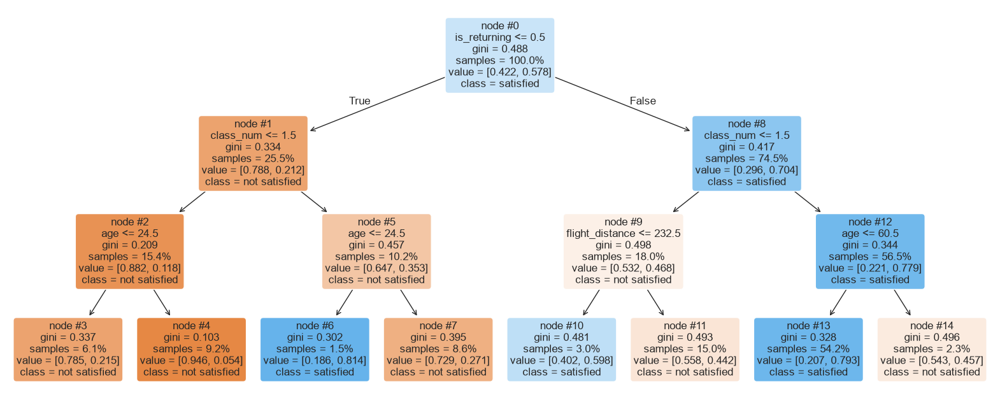

In [660]:
# Plot
plt.figure(figsize=(20, 8))
plot_tree(tree_business_adult, feature_names=features_business_adult, class_names=['not satisfied', 'satisfied'],
          filled=True, proportion=True, rounded=True, fontsize=12, node_ids=True)
plt.show()

In [661]:
# Segments as a table, sorted by satisfaction
df_seg_business_adult = df_business_adult.assign(segment=tree_business_adult.apply(X))
df_seg_business_adult.groupby('segment').agg(passengers=('is_satisfied', 'size'),
                              satisfied=('is_satisfied', 'mean')).sort_values('satisfied', ascending=False)

,passengers,satisfied
segment,,
6,1282,0.814353
13,45379,0.792922
10,2497,0.597918
14,1921,0.456533
11,12566,0.441907
7,7222,0.270562
3,5137,0.214717
4,7716,0.054432


In [663]:
# Add column sample_size_%, display satisfaction in %, rename satisfied in 'satisfied_%'
seg_business_adult = df_seg_business_adult.groupby('segment').agg(passengers=('is_satisfied', 'size'),
                                    satisfied=('is_satisfied', 'mean'))

seg_business_adult['sample_size_%'] = (seg_business_adult['passengers'] / seg_business_adult['passengers'].sum() * 100).round(1)
seg_business_adult = seg_business_adult.sort_values('satisfied', ascending=False)

seg_business_adult['satisfied'] = (seg_business_adult['satisfied'] * 100).round(1)
seg_business_adult = seg_business_adult.rename(columns={'satisfied': 'satisfied_%'})

seg_business_adult

,passengers,satisfied_%,sample_size_%
segment,,,
6,1282,81.4,1.5
13,45379,79.3,54.2
10,2497,59.8,3.0
14,1921,45.7,2.3
11,12566,44.2,15.0
7,7222,27.1,8.6
3,5137,21.5,6.1
4,7716,5.4,9.2


In [664]:
# Add column 'description'
descriptions2 = {
    3:  '(Business trip +) First-time, Economy/Economy Plus, age <= 24',
    4:  '(Business trip +) First-time, Economy/Economy Plus, age > 24',
    6:  '(Business trip +) First-time, Business class, age <= 24',
    7:  '(Business trip +) First-time, Business class, age > 24',
    10: '(Business trip +) Returning, Economy/Economy Plus, flight distance <= 232',
    11: '(Business trip +) Returning, Economy/Economy Plus, flight distance > 232',
    13: '(Business trip +) Returning, Business class, age <= 60',
    14: '(Business trip +) Returning, Business class, age > 60'
}

seg_business_adult['description'] = seg_business_adult.index.map(descriptions2)
seg_business_adult

,passengers,satisfied_%,sample_size_%,description
segment,,,,
6,1282,81.4,1.5,"(Business trip +) First-time, Business class, age <= 24"
13,45379,79.3,54.2,"(Business trip +) Returning, Business class, age <= 60"
10,2497,59.8,3.0,"(Business trip +) Returning, Economy/Economy Plus, flight distance <= 232"
14,1921,45.7,2.3,"(Business trip +) Returning, Business class, age > 60"
11,12566,44.2,15.0,"(Business trip +) Returning, Economy/Economy Plus, flight distance > 232"
7,7222,27.1,8.6,"(Business trip +) First-time, Business class, age > 24"
3,5137,21.5,6.1,"(Business trip +) First-time, Economy/Economy Plus, age <= 24"
4,7716,5.4,9.2,"(Business trip +) First-time, Economy/Economy Plus, age > 24"


## Kundensegmente unter den erwachsenen Geschäftsreisenden

### Am zufriedensten vs. am wenigsten zufrieden:
- Zufriedenstes Segment relevanter Größe (ca. 54%, Segment 13): Stammkunden in der Business Class bis 60 Jahre (ca. 79% zufrieden)
- Eigentlich das zufriedenste Segment, aber sehr klein (1,2%, Segment 6) und daher nur zur Dokumentation: Erstkunden bis 24 Jahre in der Business Class (ca. 81 % zufrieden)
- Am wenigsten zufriedenes Segment (ca. 9%, Segment 4): Erstkunden in Economy oder Economy Plus über 24 Jahre (ca. 5,5% zufrieden) --> Warum ist diese Gruppe so unzufrieden? Was könnte helfen?

### Überwiegend neutral oder unzufrieden, eine genauere Betrachtung wert:
- Segment 11 (15%): Stammkunden in Economy/Economy Plus auf Strecken über 232 Meilen, ca. 44 % zufrieden --> Was könnte die Zufriedenheit dieser Gruppe steigern?
- Segment 7 (ca. 9%): Erstkunden in der Business Class über 24 Jahre, ca. 27 % zufrieden --> Warum ist diese Gruppe unzufrieden? Was könnte helfen?
- Segment 3 (ca. 6%): Erstkunden in Economy/Economy Plus bis 24 Jahre, ca. 21,5% zufrieden --> Warum ist diese Gruppe unzufrieden? Was könnte helfen?

### Allgemeine Tendenzen und relevante Merkmalskombinationen:
- Neukunden vs. wiederkehrende Kunden: Neukunden sind durchgängig weniger zufrieden, mit Ausnahme des kleinen Segments 6
- Business Class vs. Economy/Economy Plus: Letztere sind weniger zufrieden
- Neukunden in Economy/Economy Plus: geringe Zufriedenheit

## Untersuchung des Zusammenhangs zwischen Bewertungen, Fluginformationen und Zufriedenheit

In [665]:
# Update dfs used for correlations - exclude personal travellers and minors

df_ratings = df_business_adult[['id', 'is_satisfied'] + rated_cols].copy()

df_passenger_flight_info_ratings = df_business_adult[['id', 'is_satisfied', 'arrival_delay_log'] + passenger_cols + rated_cols].copy()

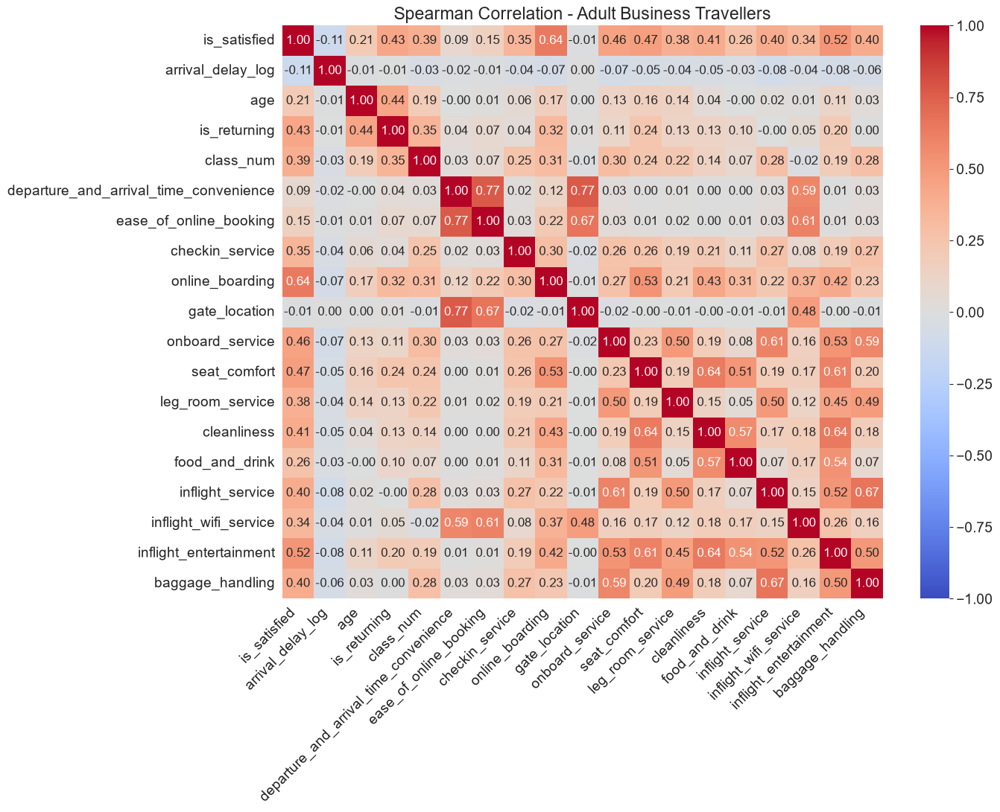

In [667]:
# Correlations - all adult business travellers
corr_business_adult = df_passenger_flight_info_ratings.drop(columns=['id', 'purpose_is_business']).corr(method='spearman')

plt.figure(figsize=(13, 10))
sns.heatmap(corr_business_adult, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, annot_kws={'size': 12})
plt.title('Spearman Correlation - Adult Business Travellers')
plt.xticks(rotation=45, ha='right');

### Compare correlations for these segments: 
1) All adult business travellers
2) Most satisfied (79% satisfied): Returning + Business class + <= 60 y.o.
3) Least satisfied (9% satisfied): First-time + Economy/Economy Plus + age > 24
4) 44% satisfied: Returning + Economy/Economy Plus + flight distance > 232 miles
5) 27% satisfied: First-time + Business class + age > 24
6) 21% satisfied: First-time + Economy/Economy Plus + age <= 24
7) Returning customers
8) First-time customer
9) Business class
10) Economy/Economy Plus
11) Rirst-time + Economy/Economy Plus 

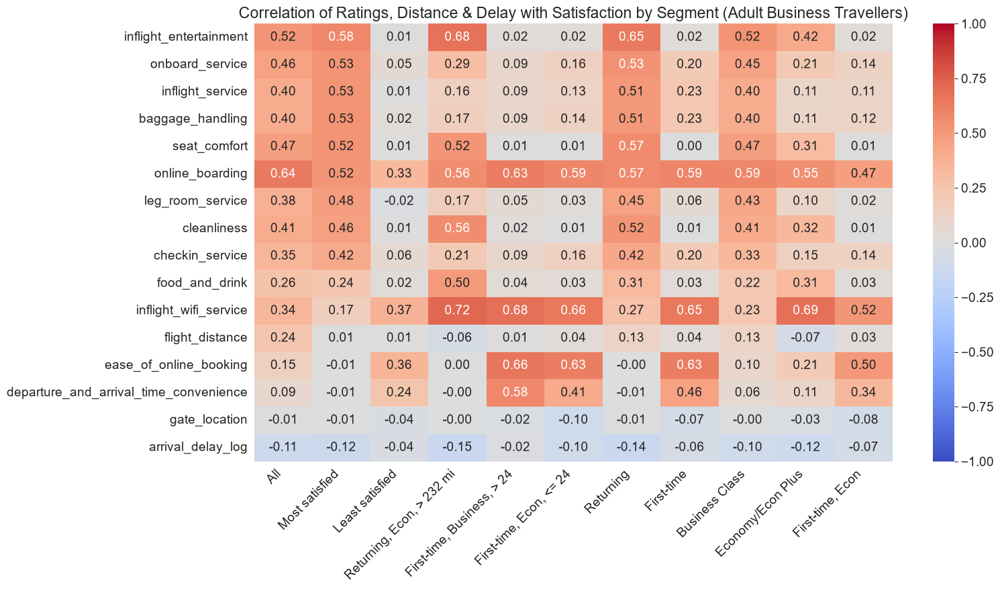

In [685]:
# Compare correlations between segments - satisfaction vs. ratings, distance and arrival delay log

returning = df_business_adult['customer_type'] == 'Returning'
business_class = df_business_adult['class'] == 'Business'

corr_cols = ['flight_distance'] + ['arrival_delay_log'] + rated_cols

segments = {
    'All':                              pd.Series(True, index=df_business_adult.index),
    'Most satisfied':                   returning & business_class & (df_business_adult['age'] <= 60),
    'Least satisfied':                  ~returning & ~business_class & (df_business_adult['age'] > 24),
    'Returning, Econ, > 232 mi':         returning & ~business_class & (df_business_adult['flight_distance'] > 232),
    'First-time, Business, > 24':       ~returning & business_class & (df_business_adult['age'] > 24),
    'First-time, Econ, <= 24':            ~returning & ~business_class & (df_business_adult['age'] <= 24),
    'Returning':                        returning,
    'First-time':                       ~returning,
    'Business Class':                   business_class,
    'Economy/Econ Plus':                 ~business_class,
    'First-time, Econ':                  ~returning & ~business_class,
}

sat_corr = pd.DataFrame({
    name: df_business_adult.loc[mask, corr_cols].corrwith(df_business_adult.loc[mask, 'is_satisfied'], method='spearman')
    for name, mask in segments.items()
}).sort_values('Most satisfied', ascending=False)

plt.figure(figsize=(16, 9))
sns.heatmap(sat_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation of Ratings, Distance & Delay with Satisfaction by Segment (Adult Business Travellers)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# ! Ein weiterer auffälliger Korrelationsbefund

## Erneut zeigen viele Segmente auffällig geringe Korrelationen zwischen Zufriedenheit und Bewertungen

(mit Ausnahme von Online Booking, Online Boarding, Wifi und Time Convenience) - ein ähnliches Muster wie zuvor bei den Privatreisenden (das Artefakt der Privatreisenden wurde bereits ausgeschlossen)

## Artefakt bei Neukunden?

### --> Heatmap neu gruppieren

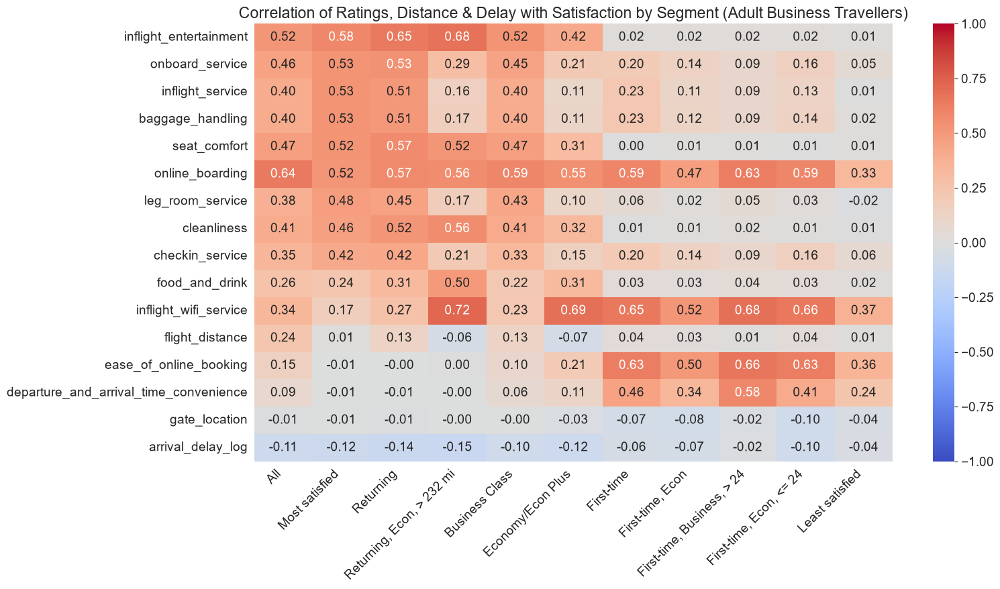

In [686]:
# Regroup the heatmap - place first-time segments (including least satisfied) last
order = ['All', 
         'Most satisfied',
         'Returning', 'Returning, Econ, > 232 mi',
         'Business Class', 'Economy/Econ Plus',
         'First-time', 'First-time, Econ', 'First-time, Business, > 24', 'First-time, Econ, <= 24',
         'Least satisfied']
sat_corr = sat_corr[order]

plt.figure(figsize=(16, 9))
sns.heatmap(sat_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation of Ratings, Distance & Delay with Satisfaction by Segment (Adult Business Travellers)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout();

## Die neu gruppierte Korrelations-Heatmap zeigt ein Muster und deutet auf ein weiteres mögliches Artefakt hin:

- Wiederkehrende Kunden (Most satisfied, Returning, Returning Econ > 232 mi) und teilweise auch die Reiseklasse (Business Class stärker als Economy/Economy Plus) zeigen breit gestreute Korrelationen zwischen Zufriedenheit und dem Erlebnis an Bord: Entertainment, On-board Service, In-flight Service, Baggage Handling, Seat Comfort, Leg Room, Cleanliness, etc.
- Neukunden dagegen (alle fünf Erstkunden-Spalten, einschließlich und vor allem Least satisfied) zeigen keine oder nahezu keine Korrelation zwischen Zufriedenheit und Faktoren wie In-flight Entertainment, Seat Comfort, Cleanliness oder Food and Drink. Ihre Zufriedenheit hängt fast ausschließlich mit Online Booking, Online Boarding, Wifi und Time Convenience zusammen - ein ähnliches "digitales" Muster wie bei den Privatreisenden, ergänzt um den Faktor Time Convenience. Insgesamt wirkt dieses Muster nicht plausibel.

### Konstant über alle Segmente:
- Online Boarding ist der stärkste oder einer der stärksten Faktoren
- Gate Location und Verspätung sind vernachlässigbar

### Mögliches Artefakt: Neukunden
- In realen Daten ist es eher unwahrscheinlich, dass die Zufriedenheit von Neukunden fast ausschließlich von digitalen bzw. zeitbezogenen Bewertungen abhängt und von Sitzkomfort, Verpflegung, Entertainment und Sauberkeit völlig oder nahezu völlig unabhängig ist.
- Das Artefakt scheint mit dem Kundentyp zusammenzuhängen: wiederkehrende Kunden in Economy/Economy Plus zeigen das breite Korrelationsmuster, Neukunden in der Business Class das "digitale" Muster.

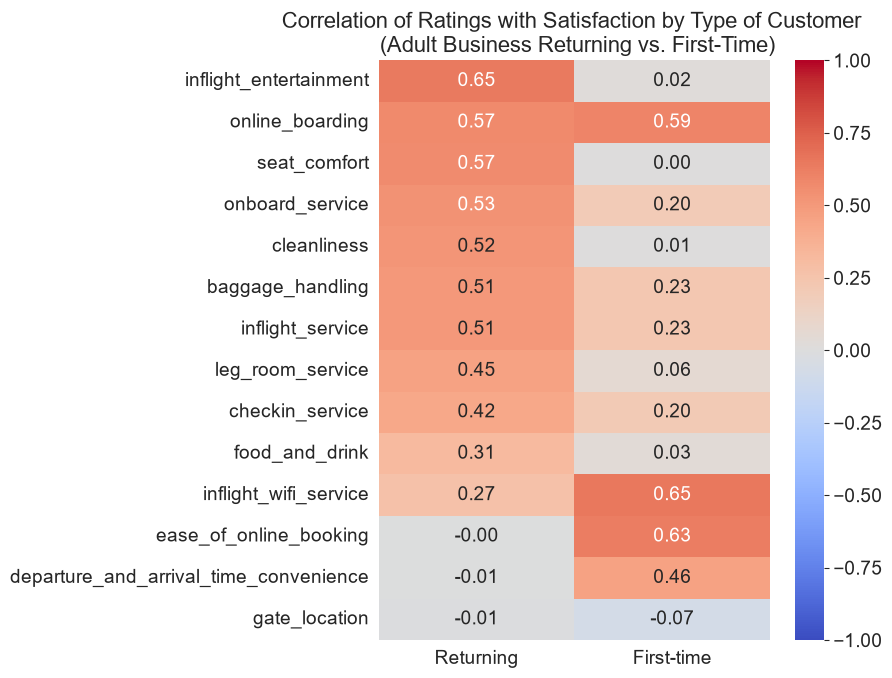

In [1028]:
# Compare ratings' correlation with happiness for returning and first-time customers

returning = df_business_adult['customer_type'] == 'Returning'
business_class = df_business_adult['class'] == 'Business'

corr_cols = rated_cols

segments = {
    'Returning':  returning, 
    'First-time': ~returning,
}

sat_corr = pd.DataFrame({
    name: df_business_adult.loc[mask, corr_cols].corrwith(df_business_adult.loc[mask, 'is_satisfied'], method='spearman')
    for name, mask in segments.items()
}).sort_values('Returning', ascending=False)

plt.figure(figsize=(9, 7))
sns.heatmap(sat_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation of Ratings with Satisfaction by Type of Customer \n (Adult Business Returning vs. First-Time)', fontsize=16)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### --> As seen here clearly one more time: 
- returning business customers show a broad pattern of correlation between ratings and satisfaction
- first-time business customers' satisfaction is driven almost exclusively by wifi, online booking, online boarding and time convenience

In [860]:
# For first-time adult business travellers - check average ratings for categories with high correlation with satisfaction
df_business_adult[df_business_adult['customer_type'] == 'First-time'][
    ['online_boarding', 'ease_of_online_booking', 'inflight_wifi_service', 'departure_and_arrival_time_convenience']].mean()

online_boarding                           2.841632
ease_of_online_booking                    2.838560
inflight_wifi_service                     2.816547
departure_and_arrival_time_convenience    2.876543
dtype: float64

### First-time customers: check average ratings and correlation with satisfaction

In [1010]:
# Show first-time customers's correlation between satisfaction & categories and average ratings

first = df_business_adult[df_business_adult['customer_type'] == 'First-time']

table = pd.DataFrame({
    'correlation': first[rated_cols].corrwith(first['is_satisfied'], method='spearman'),
    'mean_rating': first[rated_cols].mean(),
}).round(2).sort_values('correlation', ascending=False)

print('First-time customers: average ratings and correlation with satisfaction')
table

First-time customers: average ratings and correlation with satisfaction


,correlation,mean_rating
inflight_wifi_service,0.65,2.82
ease_of_online_booking,0.63,2.84
online_boarding,0.59,2.84
departure_and_arrival_time_convenience,0.46,2.88
inflight_service,0.23,3.69
baggage_handling,0.23,3.68
checkin_service,0.20,3.21
onboard_service,0.20,3.24
leg_room_service,0.06,3.22
food_and_drink,0.03,3.05


# Empfehlungen hinsichtlich Neukunden:
1. Daten überprüfen
   - Wenn synthetisch generiert: Wie wurden die Daten generiert? Evtl. Regeln anpassen, für mehr Realitätsnähe
   - Wenn real: Sind die Daten fehlerfrei? Evtl. Fehler beheben
2. Wenn Daten real und korrekt, könnte es sinnvoll sein, die Kategorien mit dem größten Impact (Zufriedenheitskorrelation) und der schwächsten Performance (auf der Basis von Durschnittsbewertung) anzugehen und den entsprechenden Service zu verbessern, um die Zufriedenheit von Neukunden zu erhöhen. Das wären laut Analyse:
   - In-Flight WiFi-Service (Korrelation 0,65, Durschschnittsbewertung 2,82)
   - Online Booking (Korrelation 0,63, Durchschnittsbewertung 2,84)
   - Online Boarding (Korrelation 0,59, Durschschnittsbewertung 2,84)

Für weitere Analyse im Rahmen des Projektes, wegen Verdacht auf ein Artefakt, werde ich die Neukunden ausschließen (21.357 Datensätze).

# --> Neuer Umfang: ***Returning*** adult business travellers

In [1232]:
# Count customer type first-time
(df_business['customer_type'] == 'First-time').sum()

np.int64(22694)

Anmerkung 08.11.2026: Wrong dataframe für die Kalkulation der erwachsenen Neukunden verwendet - df_business statt df_business_adult

Korrekter Code:
(df_business_adult['customer_type'] == 'First-time').sum()

Korrekte Zahl: 
21.357

## Side quest: Examine the suspicious rating variables

In [707]:
# Check satisfaction by customer type and wifi rating
print('Satisfaction by customer type and wifi rating')
(df_business_adult.groupby(['customer_type', 'inflight_wifi_service'])['is_satisfied'].mean().unstack() *100).round(1)

Satisfaction by customer type and wifi rating


inflight_wifi_service,1.0,2.0,3.0,4.0,5.0
customer_type,,,,,
First-time,0.0,1.7,1.9,49.7,100.0
Returning,65.8,56.0,57.8,80.3,98.7


#### Odd! First-time customers wifi: Satisfaction 0% at 1, 100% at 5!

In [709]:
# Check satisfaction by customer type and online booking rating
print('Satisfaction by customer type and online booking rating')
(df_business_adult.groupby(['customer_type', 'ease_of_online_booking'])['is_satisfied'].mean().unstack() * 100).round(1)

Satisfaction by customer type and online booking rating


ease_of_online_booking,1.0,2.0,3.0,4.0,5.0
customer_type,,,,,
First-time,0.2,1.7,4.6,47.1,93.7
Returning,71.4,70.3,70.3,70.1,70.8


#### Odd? Returning customers online booking: satisfaction ~identical regardless of rating (70-71%)

In [711]:
# Check satisfaction by customer type and time convenience rating
print('Satisfaction by customer type and time convenience rating')
(df_business_adult.groupby(['customer_type', 'departure_and_arrival_time_convenience'])['is_satisfied'].mean().unstack() * 100).round(1)

Satisfaction by customer type and time convenience rating


departure_and_arrival_time_convenience,1.0,2.0,3.0,4.0,5.0
customer_type,,,,,
First-time,2.1,4.7,7.9,35.1,61.7
Returning,71.3,70.4,70.4,70.2,70.5


#### Odd? Returning customers time convenience: same as online booking

In [713]:
# Check satisfaction by customer type and online boarding rating
print('Satisfaction by customer type and online boarding rating')
(df_business_adult.groupby(['customer_type', 'online_boarding'])['is_satisfied'].mean().unstack() * 100).round(1)

Satisfaction by customer type and online boarding rating


online_boarding,1.0,2.0,3.0,4.0,5.0
customer_type,,,,,
First-time,1.3,2.5,4.7,46.4,87.9
Returning,40.9,31.8,29.2,80.5,100.0


#### Odd! Returning customers online boarding: 100% satisfaction at 5!

## --> Question: Compromised rating variables - online booking/boarding, wifi, time? 
1. inflight_wifi_service
    - First-time: 0 satisfaction at 1, close to 0 satisfaction between 2-3, then jump to 50% satisfaction at 4, then 100% (!) at 5 
2. ease_of_online_booking
    - First-time: similar to wifi, big jump at 4
    - Returning: constant 70-71% satisfaction regardless of rating
3. departure_and_arrival_time_convenience
    - First-time: same as online booking
    - Returning: same as online booking
4. online_boarding: same as online booking
    - First-time: same as online booking
    - Returning: satisfaction constantly *falling* between 1-3, then increase at 4 and 100% (!) satisfaction at 5

## Check all rating variables for returning customers

In [1044]:
# Check all ratings variables for returning customers, display satisfaction in%

ret = df_business_adult[df_business_adult['customer_type'] == 'Returning']
check_ret = (pd.DataFrame({c: ret.groupby(c)['is_satisfied'].mean() for c in rated_cols}).T * 100).round(1)

print('Satisaction by category rating - Returning customers')
check_ret

Satisaction by category rating - Returning customers


,1.0,2.0,3.0,4.0,5.0
departure_and_arrival_time_convenience,71.3,70.4,70.4,70.2,70.5
ease_of_online_booking,71.4,70.3,70.3,70.1,70.8
checkin_service,37.6,39.4,72.9,74.4,99.9
online_boarding,40.9,31.8,29.2,80.5,100.0
gate_location,71.6,70.2,70.0,69.8,70.4
onboard_service,29.0,38.4,52.2,82.9,98.3
seat_comfort,41.4,33.1,27.7,80.2,99.3
leg_room_service,31.0,44.9,45.9,84.6,90.9
cleanliness,26.5,28.4,66.9,80.6,99.1
food_and_drink,29.2,62.5,63.8,80.8,86.6


In [1045]:
# Add column 'pattern' to check_ret table

patterns_check_ret = {
    'departure_and_arrival_time_convenience': 'Flat',
    'ease_of_online_booking': 'Flat',
    'checkin_service': 'Near 100% satisfaction at 5',
    'online_boarding': 'Satisfaction falls as rating rises from 1-3, then jumps at 4, then 100% at 5!',
    'gate_location': 'Flat',
    'onboard_service': 'Near 100% satisfaction at 5',
    'seat_comfort': 'Satisfaction falls as rating rises from 1-3, then jumps at 4, then ~100% at 5',
    'leg_room_service': 'Nothing special',
    'cleanliness': 'Near 100% satisfaction at 5',
    'food_and_drink': 'Nothing special',
    'inflight_service': 'Satisfaction falls as rating rises from 1-3, then jumps at 4, then ~100% at 5',
    'inflight_wifi_service': 'Satisfaction falls as rating rises from 1-3, then jumps at 4, then ~100% at 5',
    'inflight_entertainment': 'Near 100% satisfaction at 5',
    'baggage_handling': 'Near 100% satisfaction at 5'
}

check_ret['pattern'] = check_ret.index.map(patterns_check_ret)

print('Patterns in Satisfaction by Category Rating - Returning Customers')
check_ret

Patterns in Satisfaction by Category Rating - Returning Customers


,1.0,2.0,3.0,4.0,5.0,pattern
departure_and_arrival_time_convenience,71.3,70.4,70.4,70.2,70.5,Flat
ease_of_online_booking,71.4,70.3,70.3,70.1,70.8,Flat
checkin_service,37.6,39.4,72.9,74.4,99.9,Near 100% satisfaction at 5
online_boarding,40.9,31.8,29.2,80.5,100.0,"Satisfaction falls as rating rises from 1-3, then jumps at 4, then 100% at 5!"
gate_location,71.6,70.2,70.0,69.8,70.4,Flat
onboard_service,29.0,38.4,52.2,82.9,98.3,Near 100% satisfaction at 5
seat_comfort,41.4,33.1,27.7,80.2,99.3,"Satisfaction falls as rating rises from 1-3, then jumps at 4, then ~100% at 5"
leg_room_service,31.0,44.9,45.9,84.6,90.9,Nothing special
cleanliness,26.5,28.4,66.9,80.6,99.1,Near 100% satisfaction at 5
food_and_drink,29.2,62.5,63.8,80.8,86.6,Nothing special


In [1046]:
# Check all ratings variables for first-time customers, display satisfaction in%

ft = df_business_adult[df_business_adult['customer_type'] == 'First-time']
check_ft = (pd.DataFrame({c: ft.groupby(c)['is_satisfied'].mean() for c in rated_cols}).T * 100).round(1)

print('Satisaction by rated categories - First-time customers')
check_ft

Satisaction by rated categories - First-time customers


,1.0,2.0,3.0,4.0,5.0
departure_and_arrival_time_convenience,2.1,4.7,7.9,35.1,61.7
ease_of_online_booking,0.2,1.7,4.6,47.1,93.7
checkin_service,7.5,8.1,23.7,24.2,33.4
online_boarding,1.3,2.5,4.7,46.4,87.9
gate_location,31.0,26.3,16.5,16.7,31.2
onboard_service,7.9,8.5,23.6,23.0,34.0
seat_comfort,20.4,22.1,20.3,21.5,21.4
leg_room_service,10.2,22.5,21.8,22.9,23.2
cleanliness,19.9,22.4,20.3,21.5,21.6
food_and_drink,19.1,21.3,19.5,22.6,23.2


In [1047]:
# Add column 'description' to check_ft table

patterns_ft = {
    'departure_and_arrival_time_convenience': 'Big jump at 4',
    'ease_of_online_booking': 'Big jump at 4',
    'checkin_service': 'Nothing special',
    'online_boarding': 'Big jump at 4',
    'gate_location': 'Satisfaction almost identical at 1 and 5, falling between 2-3',
    'onboard_service': 'Nothing special',
    'seat_comfort': 'Flat',
    'leg_room_service': 'Flat between 2-5',
    'cleanliness': 'Flat',
    'food_and_drink': 'Flat',
    'inflight_service': 'Satisfaction falls as rating rises from 1-3',
    'inflight_wifi_service': 'Satisfaction close to 0 between 1-3, then jumps at 4, 100% at 5!',
    'inflight_entertainment': 'Flat',
    'baggage_handling': 'Satisfaction falls as rating rises from 1-3'
}

check_ft['pattern'] = check_ft.index.map(patterns_ft)

print('Patterns in Satisaction by Category Rating - First-Time Customers')
check_ft

Patterns in Satisaction by Category Rating - First-Time Customers


,1.0,2.0,3.0,4.0,5.0,pattern
departure_and_arrival_time_convenience,2.1,4.7,7.9,35.1,61.7,Big jump at 4
ease_of_online_booking,0.2,1.7,4.6,47.1,93.7,Big jump at 4
checkin_service,7.5,8.1,23.7,24.2,33.4,Nothing special
online_boarding,1.3,2.5,4.7,46.4,87.9,Big jump at 4
gate_location,31.0,26.3,16.5,16.7,31.2,"Satisfaction almost identical at 1 and 5, falling between 2-3"
onboard_service,7.9,8.5,23.6,23.0,34.0,Nothing special
seat_comfort,20.4,22.1,20.3,21.5,21.4,Flat
leg_room_service,10.2,22.5,21.8,22.9,23.2,Flat between 2-5
cleanliness,19.9,22.4,20.3,21.5,21.6,Flat
food_and_drink,19.1,21.3,19.5,22.6,23.2,Flat


## Bisherige Erkenntnisse zu den Bewertungsmustern:
- Einige Bewertungsvariablen erscheinen kompromittiert, vor allem:
    - Wifi bei Neukunden: 100% Zufriedenheit bei Bewertung 5
    - Online Boarding bei wiederkehrenden Kunden: 100% Zufriedenheit bei Bewertung 5
- Über die Kategorien hinweg zeigen sich mehrere Muster (hier auffällig flach, dort auffällig große Sprünge usw.), für die ich keine Erklärung habe. Aus Zeitgründen untersuche ich dies nicht weiter, es könnte aber ein interessanter Fall für später sein.
- Für die aktuelle Analyse werden die Bewertungsdaten unter diesem Vorbehalt verwendet.

# Airline Passenger Satisfaction - ***Returning*** adult business travellers (62.363 Datensätze)

In [772]:
# Count returning adult business travellers
(df_business_adult['customer_type'] == 'Returning').sum()

np.int64(62363)

In [773]:
# New df withouth the first-time customers
df_ret_business = df_business_adult[df_business_adult['customer_type'] == 'Returning'].copy()
df_ret_business

,id,gender,age,customer_type,type_of_travel,class,flight_distance,departure_delay,arrival_delay,departure_and_arrival_time_convenience,...,departure_delay_log,arrival_delay_log,is_female,is_returning,purpose_is_business,class_num,did_rate_time_convenience,did_rate_online_booking,did_rate_online_boarding,did_rate_inflight_wifi
1,2,Female,35,Returning,Business,Business,821,26,39,2.0,...,3.295837,3.688879,True,True,True,2,True,True,True,True
2,3,Male,41,Returning,Business,Business,853,0,0,4.0,...,0.000000,0.000000,False,True,True,2,True,True,True,True
3,4,Male,50,Returning,Business,Business,1905,0,0,2.0,...,0.000000,0.000000,False,True,True,2,True,True,True,True
4,5,Female,49,Returning,Business,Business,3470,0,1,3.0,...,0.000000,0.693147,True,True,True,2,True,True,True,True
5,6,Male,43,Returning,Business,Business,3788,0,0,4.0,...,0.000000,0.000000,False,True,True,2,True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129863,129864,Female,39,Returning,Business,Business,2747,0,0,1.0,...,0.000000,0.000000,True,True,True,2,True,True,True,True
129864,129865,Male,38,Returning,Business,Business,2740,0,0,3.0,...,0.000000,0.000000,False,True,True,2,True,True,True,True
129865,129866,Male,64,Returning,Business,Economy Plus,337,27,18,3.0,...,3.332205,2.944439,False,True,True,1,True,True,True,True
129867,129868,Male,47,Returning,Business,Economy Plus,447,0,0,4.0,...,0.000000,0.000000,False,True,True,1,True,True,True,True


In [1048]:
df_ret_business.describe()

,id,age,flight_distance,departure_delay,arrival_delay,departure_and_arrival_time_convenience,ease_of_online_booking,checkin_service,online_boarding,gate_location,...,leg_room_service,cleanliness,food_and_drink,inflight_service,inflight_wifi_service,inflight_entertainment,baggage_handling,departure_delay_log,arrival_delay_log,class_num
count,62363.000000,62363.000000,62363.000000,62363.000000,62363.000000,62230.000000,62226.000000,62363.000000,62293.000000,62363.000000,...,62363.000000,62363.000000,62363.000000,62363.000000,62363.000000,62363.000000,62363.000000,62363.000000,62363.000000,62363.000000
mean,65182.877684,43.973847,1601.686016,14.830733,15.224364,2.996095,3.057838,3.319629,3.749410,3.014367,...,3.597951,3.473951,3.352693,3.667255,2.969806,3.679570,3.668169,1.241664,1.272402,1.575245
std,37333.196936,11.636919,1137.937777,38.343380,38.795684,1.411051,1.391282,1.262288,1.149477,1.404960,...,1.254851,1.225631,1.267079,1.165791,1.344462,1.197462,1.166924,1.620753,1.632301,0.781526
min,2.000000,18.000000,31.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
25%,32642.500000,36.000000,551.000000,0.000000,0.000000,2.000000,2.000000,3.000000,3.000000,2.000000,...,3.000000,3.000000,2.000000,3.000000,2.000000,3.000000,3.000000,0.000000,0.000000,2.000000
50%,65515.000000,44.000000,1489.000000,0.000000,0.000000,3.000000,3.000000,3.000000,4.000000,3.000000,...,4.000000,4.000000,3.000000,4.000000,3.000000,4.000000,4.000000,0.000000,0.000000,2.000000
75%,97473.500000,52.000000,2481.000000,12.000000,13.000000,4.000000,4.000000,4.000000,5.000000,4.000000,...,5.000000,4.000000,4.000000,5.000000,4.000000,5.000000,5.000000,2.564949,2.639057,2.000000
max,129872.000000,85.000000,4983.000000,1305.000000,1280.000000,5.000000,5.000000,5.000000,5.000000,5.000000,...,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,7.174724,7.155396,2.000000


## Eckdaten zu den wiederkehrenden erwachsenen Geschäftsreisenden:

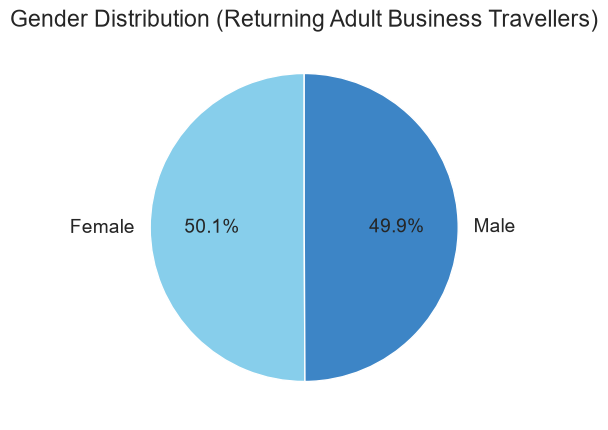

In [862]:
# Gender distribution
gen_count = df_ret_business['gender'].value_counts()
gen_count.plot(kind='pie', labels=['Female', 'Male'], autopct='%.1f%%', colors=[sky_blue, medium_blue], startangle=90)
plt.title('Gender Distribution (Returning Adult Business Travellers)');

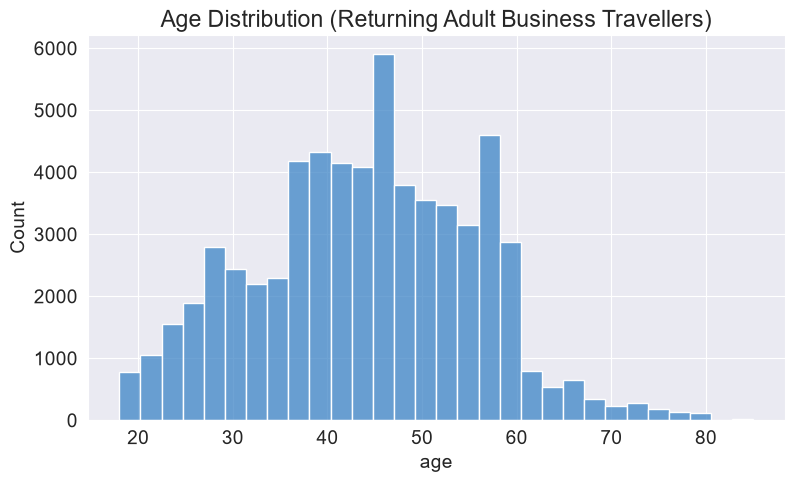

In [864]:
# Age distribution
sns.histplot(df_ret_business['age'], bins=30, color=medium_blue)
plt.title('Age Distribution (Returning Adult Business Travellers)');

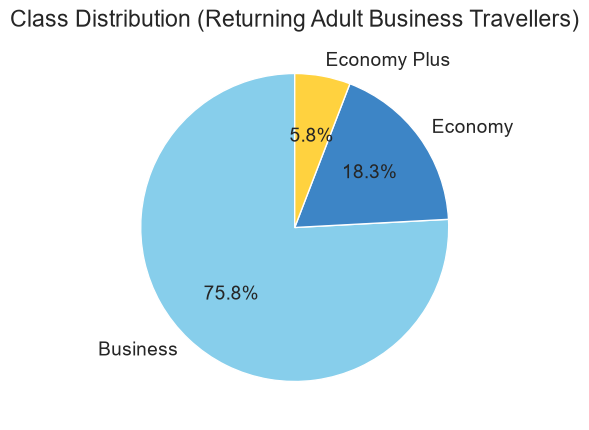

In [1082]:
# Class distribution
cl_count = df_ret_business['class'].value_counts()
cl_count.plot(kind='pie', labels=['Business', 'Economy', 'Economy Plus'], autopct='%.1f%%', colors=[sky_blue, medium_blue, sunny_yellow], startangle=90)
plt.title('Class Distribution (Returning Adult Business Travellers)');

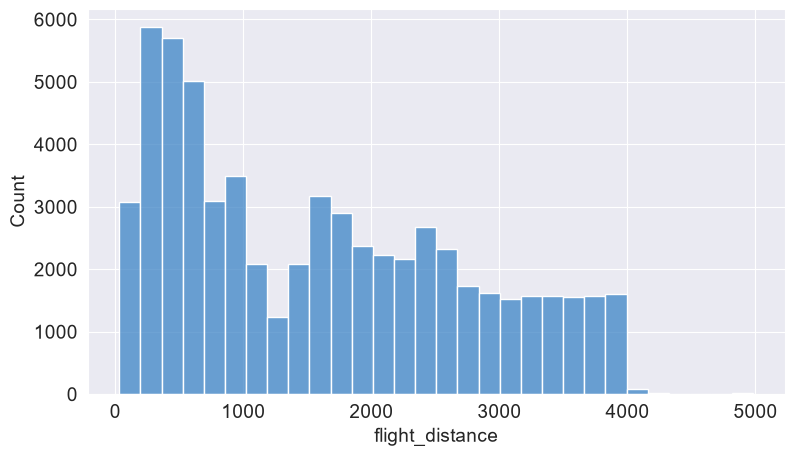

In [1111]:
# Flight distnace distribution histogram
sns.histplot(df_ret_business['flight_distance'], bins=30, color=medium_blue);

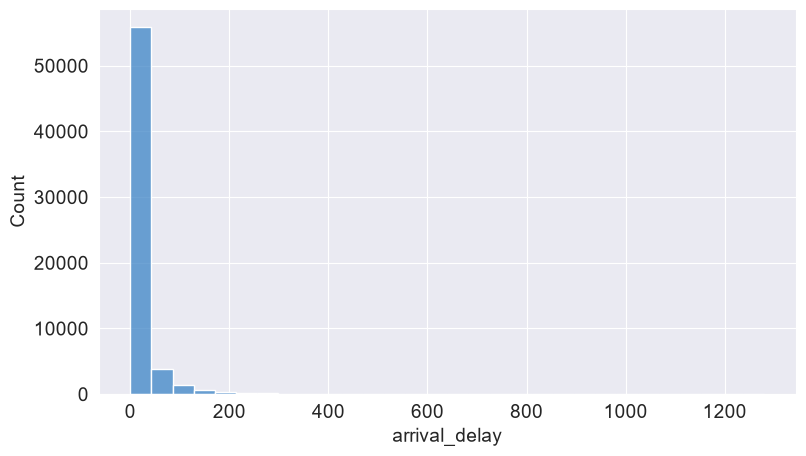

In [1110]:
# Arrival delay distribution histogram
sns.histplot(df_ret_business['arrival_delay'], bins=30, color=medium_blue);

### TAKEAWAYS: Eckdaten Returning Adult Business Travellers:
- Alter: 18-85, mit Häufung zwischen Mitte 30-60
- Geschlecht: nach wie vor fast 50/50, ähnlich wie im gesamten Datensatz
- Reiseklasse: mehrheitlich Business Class (~76%), nur 18% Economy, ~6% Economy Plus
- Die Verteillung der Flugstrecken hat sich im Vergleich zum gesamten Datensatz etwas verändert: Zwar sind die Kurzstrecken nach wie vor am häufigsten, aber die Geschäftsreisenden fliegen auch genug Mittel- und Langstrecken 
- Ankunftsverspätung: ähnlich wie im gesamten Datensatz - überweigend gering, 0 Min bis 1,5 Stunde

## FRAGE 1: Wie zufrieden sind die Fluggäste (hier: die wiederkehrenden erwachsenen Geschäftsreisenden) insgesamt und wie unterscheidet sich die Zufriedenheit nach Kunden- und Flugmerkmalen?

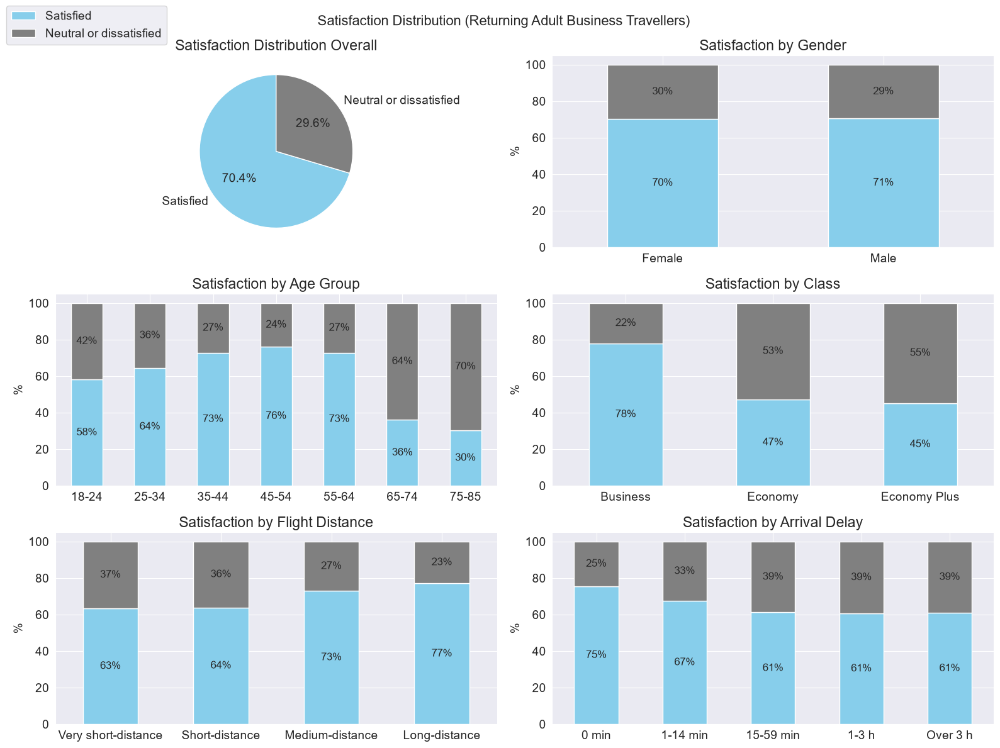

In [1109]:
# Create a plot with 6 subplots to show satisfaction distribution overall 
# and by: gender, age group, class, distance category, arrival delay category 

fig, axes = plt.subplots(3, 2, figsize=(16, 12))

# Satisfaction distribution overall as a pie chart
sat_count = df_ret_business['is_satisfied'].value_counts().reindex([True, False])
axes[0, 0].pie(sat_count, labels=['Satisfied', 'Neutral or dissatisfied'],
               autopct='%.1f%%', colors=[sky_blue, 'gray'], startangle=90)
axes[0, 0].set_title('Satisfaction Distribution Overall')

# Satisfaction distribution by: gender, age_group, class - as bar charts
for ax, col, title in [
    (axes[0, 1], 'gender', 'by Gender'),
    (axes[1, 0], 'age_group', 'by Age Group'),
    (axes[1, 1], 'class', 'by Class'),
    (axes[2, 0], 'distance_category', 'by Flight Distance'),
    (axes[2, 1], 'arrival_delay_category', 'by Arrival Delay')
]:
    ct = pd.crosstab(df_ret_business[col], df_ret_business['is_satisfied'], normalize='index') * 100
    ct = ct.reindex(columns=[True, False])
    ct.plot(kind='bar', stacked=True, color=[sky_blue, 'gray'], ax=ax, legend=False)
    
    for container in ax.containers:
        ax.bar_label(container, fmt='%.0f%%', label_type='center', fontsize=12)
        
    ax.set_title('Satisfaction ' + title)
    ax.set_ylabel('%')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=0)

fig.legend(['Satisfied', 'Neutral or dissatisfied'], loc='upper left')
fig.suptitle('Satisfaction Distribution (Returning Adult Business Travellers)', fontsize=16)
plt.tight_layout();

In [1113]:
# Re-check connection between long-distance and class, that we've seen earlier in the complete dataset
pd.crosstab(df_ret_business[df_ret_business['type_of_travel'] == 'Business']['distance_category'], df_ret_business['class'], normalize='index')

class,Business,Economy,Economy Plus
distance_category,,,
Very short-distance,0.466462,0.406792,0.126747
Short-distance,0.561658,0.331701,0.106641
Medium-distance,0.842889,0.119467,0.037644
Long-distance,0.987657,0.008871,0.003471


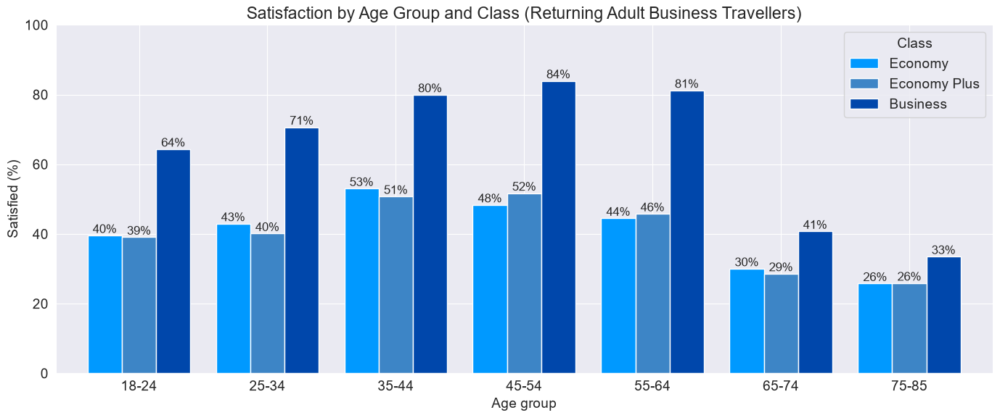

In [1120]:
# Check for "business class effect" in age related satisfaction - satisfaction by age group and class

rate = df_ret_business.groupby(['age_group', 'class'])['is_satisfied'].mean().unstack() * 100
rate = rate[['Economy', 'Economy Plus', 'Business']]

ax = rate.plot(kind='bar', color=[bright_blue, medium_blue, trendy_blue], figsize=(14, 6), width=0.8)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%', fontsize=12)

plt.title('Satisfaction by Age Group and Class (Returning Adult Business Travellers)')
plt.ylabel('Satisfied (%)')
plt.xlabel('Age group')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title='Class')
plt.tight_layout();

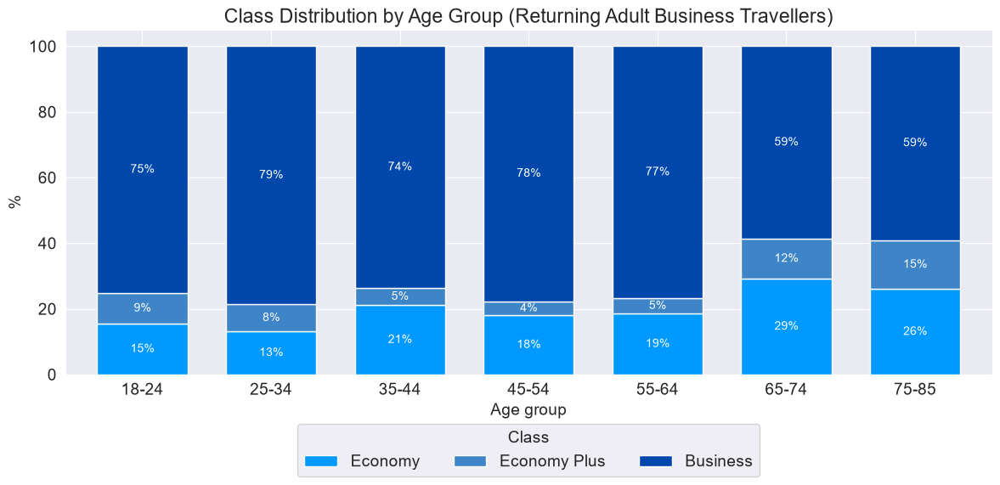

In [1123]:
# Class distribution by age group

ct = pd.crosstab(df_ret_business['age_group'], df_ret_business['class'], normalize='index') * 100
ct = ct[['Economy', 'Economy Plus', 'Business']]

ax = ct.plot(kind='bar', stacked=True, color=[bright_blue, medium_blue, trendy_blue], figsize=(12, 6), width=0.7)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%', label_type='center', fontsize=10, color='white')

plt.title('Class Distribution by Age Group (Returning Adult Business Travellers)')
plt.ylabel('%')
plt.xlabel('Age group')
plt.xticks(rotation=0)
plt.legend(title='Class', loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3)
plt.tight_layout();

In [1124]:
# Count 65-85 y.o.
(df_ret_business['age'] >= 65).sum()

np.int64(1934)

In [1125]:
# Count 65-74 and 75-85
df_ret_business['age_group'].value_counts().loc[['65-74', '75-85']]

age_group
65-74    1545
75-85     389
Name: count, dtype: int64

In [1128]:
# Count all age groups
df_ret_business['age_group'].value_counts()

age_group
45-54    18306
35-44    18013
25-34    10378
55-64    10356
18-24     3376
65-74     1545
75-85      389
7-11         0
12-17        0
Name: count, dtype: int64

### Ergebnisse zu Frage 1: 

### Zufriedenheit der wiederkehrenden erwachsenen Geschäftsreisenden insgesamt und Unterschiede nach Kunden- und Flugmerkmalen
- Die wiederkehrenden erwachsenen Geschäftsreisenden sind mehrheitlich zufrieden (~70%), und zwar unabhängig vom Geschlecht. Die höhere Zufriedenheit im Vergleich zum ursprünglichen Datensatz liegt verständlicherweise am Ausschließen der weniger zufriedenen Privatreisenden und Neukunden
- Altersgruppen:
  - Die Zufriedenheitsverteilung nach Altersgruppen ähnelt grundsätzlich der Verteilung im ursprünglichen Datensatz (vor der Ausschliessung der vermeintlichen Artefakten), bloß mit durchgehend höheren Zufriedenheitesquoten:
  - Die 45-54-jährigen sind am zufriedensten (76%), gefolgt von 35-44- und 55-64-jährigen (beide Gruppen 73%), 25-34-jährigen (64%) und 18-24-jährigen (58%)
  - Ältere Fluggäste zeigen sich weniger zufrieden: 65-74 (36%), 75-85 (30%)
  - Neue Erkenntnis: Ältere Fluggäste (65+) fliegen seltener Business Class, was ihre geringere Zufriedenheit aber nur zum Teil erklärt. Auch innerhalb derselben Reiseklasse sind sie deutlich weniger zufrieden als Fluggäste zwischen 35 und 64.
- Reiseklasse: Business Class am zufriedensten (78%), die anderen beiden Reiseklassen deutlich weniger zufrieden: Economy 47%, Economy Plus 45% (jedoch verständlicherweise deutlich zufriedener als im ursprünglichen Datensatz)
- Flugstrecke:
  - Long-distance am meisten zufrieden (77%), gefolgt von Medium-distance (73%), Short-distance (64%) und Very short-distance (63%)
  - Im Vergleich zum ursprünglichen Datensatz, sehen wir hier weniger Unterschiede zwischen den Strecken. Das erklärt sich u.a. dadurch, dass die höhrere Zufriedenheit bei den längeren Strecken immer mit der Business Class in Verbindung stand, und die Geschäftsreisenden auch bei kürzeren Strecken vermehrt Business Class fliegen (47% Business Class bei very short-distance, 56% bei short-distance) 
- Ankunftsverspätung:
  - 0 Min Verspätung verständlicherweise am zufriedensten (75%)
  - dann 8 Punkte Verschlechterung bei 1-14 Min Verspätung (von 75% auf 67%)
  - weitere 6 Punkte Verschlechterung bei 15-59 Min Verspätung (von 67% auf 61%)
  - anschließend Plateau unabhängig von Verspätungsdauer - ob 1 Stunde oder über 3 Stunden (61%)
  - bei diesem Muster hat sich im Vergleich zum ursprünglichen Datensatz wenig verändert 

## FRAGE 2: Gibt es besonders zufriedene oder besonders unzufriedene Kundensegmente?

In [1130]:
# New tree - returning adult business customers
# Use DecisionTreeClassifier to identify customer segments that are most satisfied and least satisfied

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

features = ['age', 'is_female', 'class_num', 'flight_distance']

X = df_ret_business[features]
y = df_ret_business['is_satisfied']

tree_ret_business = DecisionTreeClassifier(max_depth=3, min_samples_leaf=1000,
                              min_impurity_decrease=0.001, random_state=42)
tree_ret_business.fit(X, y)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1000
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.001
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively insp

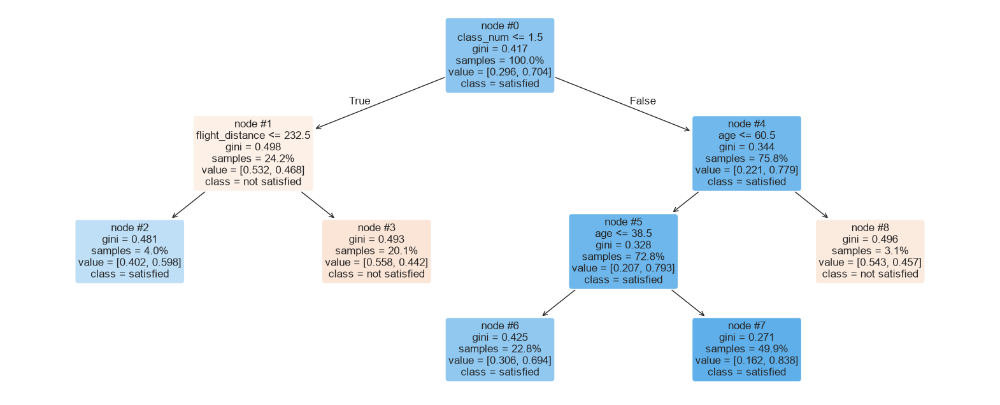

In [1100]:
# Plot tree
plt.figure(figsize=(20, 8))
plot_tree(tree_ret_business, feature_names=features, class_names=['not satisfied', 'satisfied'],
          filled=True, proportion=True, rounded=True, fontsize=12, node_ids=True)
plt.show()

In [783]:
# Segments as a table, sorted by satisfaction
df_seg = df_ret_business.assign(segment=tree_ret_business.apply(X))
df_seg.groupby('segment').agg(passengers=('is_satisfied', 'size'),
                              satisfied=('is_satisfied', 'mean')).sort_values('satisfied', ascending=False)

,passengers,satisfied
segment,,
7,31136,0.838354
6,14243,0.693604
2,2497,0.597918
8,1921,0.456533
3,12566,0.441907


In [880]:
# Add column sample_size_%
seg = df_seg.groupby('segment').agg(passengers=('is_satisfied', 'size'),
                                    satisfied=('is_satisfied', 'mean'))
seg['sample_size_%'] = (seg['passengers'] / seg['passengers'].sum() * 100).round(1)
seg = seg.sort_values('satisfied', ascending=False)
seg

,passengers,satisfied,sample_size_%
segment,,,
7,31136,0.838354,49.9
6,14243,0.693604,22.8
2,2497,0.597918,4.0
8,1921,0.456533,3.1
3,12566,0.441907,20.1


In [881]:
# Display satisfied in %
seg['satisfied'] = (seg['satisfied'] * 100).round(1)
seg

,passengers,satisfied,sample_size_%
segment,,,
7,31136,83.8,49.9
6,14243,69.4,22.8
2,2497,59.8,4.0
8,1921,45.7,3.1
3,12566,44.2,20.1


In [868]:
# Add column 'description'
descriptions = {
    2:  'Economy/Economy Plus, flight distance <= 232 miles',
    3:  'Economy/Economy Plus, flight distance > 232 miles',
    6:  'Business Class, age 18-38',
    7:  'Business Class, age 39-60',
    8:  'Business Class, age > 60',
}

seg['description'] = seg.index.map(descriptions)
seg

,passengers,satisfied,sample_size_%,description
segment,,,,
7,31136,83.8,49.9,"Business Class, age 39-60"
6,14243,69.4,22.8,"Business Class, age 18-38"
2,2497,59.8,4.0,"Economy/Economy Plus, flight distance <= 232 miles"
8,1921,45.7,3.1,"Business Class, age > 60"
3,12566,44.2,20.1,"Economy/Economy Plus, flight distance > 232 miles"


### Ergebnisse zu Frage 2: 

### Zufriedenheit nach Kundensegmenten (innerhalb von wiederkehrenden erwachsenen Geschäftsreisenden)
1. Am zufriedensten: **Business Class**, Alter **39–60** (ca. 50% der wiederkehrenden erwachsenen Geschäftsreisenden): ca. 84% zufrieden
2. **Business Class**, Alter **18–38** (ca. 23%): ca. 69% zufrieden
3. **Am wenigsten zufrieden**: **Economy/Economy Plus**, Flugstrecke **über 232 Meilen** (20 %): 44% zufrieden
4. Segmente von geringerer Größe:
    - Economy/Economy Plus, Flugstrecke bis 232 Meilen (4%): ca. 60% zufrieden
    - Business Class, Alter über 60 (ca. 3%): ca. 46% zufrieden

Insgesamt ist die Zufriedenheit unter den wiederkehrenden erwachsenen Geschäftsreisenden recht hoch. Selbst im am wenigsten zufriedenen Segment ist noch fast die Hälfte der Fluggäste zufrieden.

### Abgeleitete Segmente für die weitere Analyse

#### Zusammenfassung der Segmente
- Da die meisten Fluggäste in Economy/Economy Plus mehr als 232 Meilen fliegen (12.566 gegenüber 2.497 auf sehr kurzen Strecken), lässt sich **Economy/Economy Plus als ein gemeinsames Segment mit geringerer Zufriedenheit** betrachten. Die kleine Gruppe auf sehr kurzen Strecken ist zwar zufriedener (60% vs. 44%), macht aber nur 4% der wiederkehrenden erwachsenen Geschäftsreisenden aus.

#### Vertiefung der Baumergebnisse
- Ein Vergleich der **Altersgruppen 18–38, 39–60 und 61+** ist unabhängig von der Reiseklasse ebenfalls aufschlussreich. Bei der ältesten Gruppe kann er helfen, die zuvor beobachtete deutlich geringere Zufriedenheit älterer Fluggäste zu verstehen: Wie bewerten ältere Geschäftsreisende die einzelnen Faktoren, und worin unterscheiden sie sich von jüngeren?

## Ergänzung zur Frage 1 (Zufriedenheitsverteilung): 
#### - Economy/Economy Plus zusammenfassen und nochmal mit Business Class vegleichen
#### - Zufriedenheit nach Altersgruppen 18-38, 39-60, 61+ vergleichen

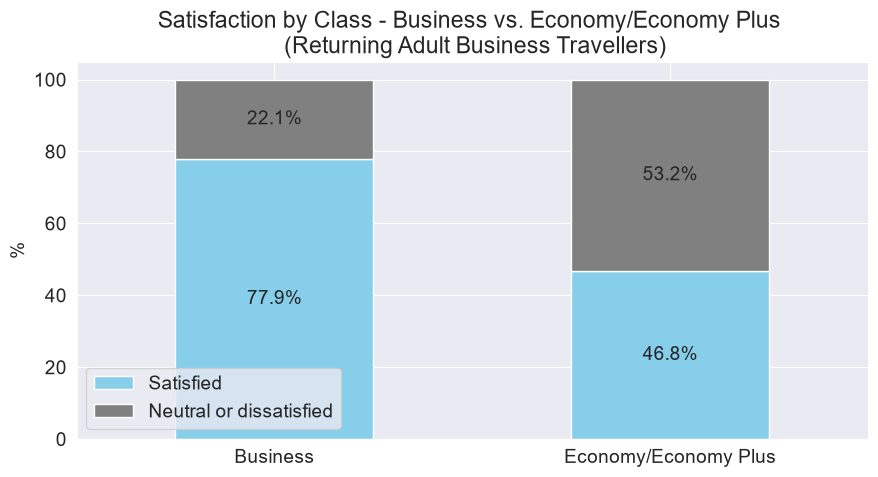

In [1146]:
# Compare satisfaction in Business class vs. Economy/Economy Plus
class_group = df_ret_business['class'].replace({'Economy': 'Economy/Economy Plus',
                                                'Economy Plus': 'Economy/Economy Plus'})

ct = pd.crosstab(class_group, df_ret_business['is_satisfied'], normalize='index') * 100
ct = ct.rename(columns={True: 'Satisfied', False: 'Neutral or dissatisfied'})
ct = ct[['Satisfied', 'Neutral or dissatisfied']]

ax = ct.plot(kind='bar', stacked=True, color=[sky_blue, 'gray'])
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', label_type='center')

plt.ylabel('%')
plt.xlabel('')
plt.title('Satisfaction by Class - Business vs. Economy/Economy Plus \n (Returning Adult Business Travellers)')
plt.xticks(rotation=0)
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

In [1147]:
# Count passengers in business class vs. economy/economy plus
df_ret_business['class'].value_counts().sort_index()

class
Business        47300
Economy         11426
Economy Plus     3637
Name: count, dtype: int64

In [1149]:
# % of passengers in business class vs. economy/economy plus
df_ret_business['class'].value_counts(normalize=True).mul(100).round(1).sort_index()

class
Business        75.8
Economy         18.3
Economy Plus     5.8
Name: proportion, dtype: float64

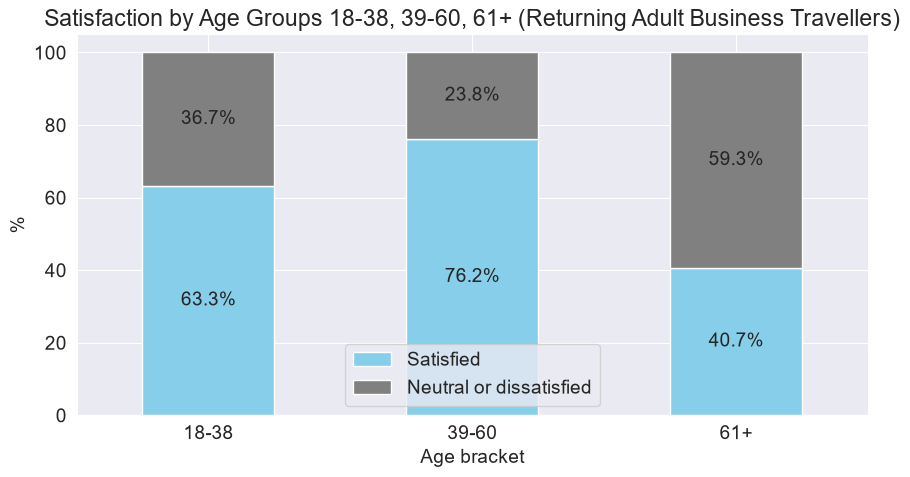

In [1145]:
# Satisfaction by age groups 18-38, 39-60, 61+
df_ret_business['age_bracket'] = pd.cut(df_ret_business['age'], bins=[17, 38, 60, np.inf],
                                        labels=['18-38', '39-60', '61+'])

ct = pd.crosstab(df_ret_business['age_bracket'], df_ret_business['is_satisfied'],
                 normalize='index') * 100

ax = ct.reindex(columns=[True, False]).plot(kind='bar', stacked=True, color=[sky_blue, 'gray'])
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', label_type='center')

plt.title('Satisfaction by Age Groups 18-38, 39-60, 61+ (Returning Adult Business Travellers)')
plt.ylabel('%')
plt.xlabel('Age bracket')
plt.legend(['Satisfied', 'Neutral or dissatisfied'], loc='lower center')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [1143]:
# Count returning adult business travellers by age bracket
df_ret_business['age_bracket'].value_counts().sort_index()

age_bracket
18-38    19190
39-60    39913
61+       3260
Name: count, dtype: int64

In [1150]:
# Returning adult business travellers by age bracket in %
(df_ret_business['age_bracket'].value_counts(normalize=True) * 100).round(1).sort_index()

age_bracket
18-38    30.8
39-60    64.0
61+       5.2
Name: proportion, dtype: float64

### Ergänzende Erkenntnisse und Anmerkungen zur Zufriedenheitsverteilung (Frage 1) und zu den Kundensegmenten (Frage 2)

#### Zufriedenheitsverteilung (ergänzend)
- Class:
  - Economy und Economy Plus zusammen: ~47% zufrieden 
- Alter:
  - 18-38-jährige: ~63% zufrieden
  - 39-60-jährige: ~76% zufrieden
  - **61+: <41% zufrieden --> das am wenigsten zufriedene Kundensegment, allerdings recht klein** (~5%, 3260 Fluggäste)

#### Kundensegmente (nach Zufriedenheit, absteigend)
1. Business Class, 39-60-jährige (~50%) - 84% zufrieden
2. Business Class unabhängig vom Alter (76%) - 78% zufrieden
3. 39-60-jährige unabhängig von Reiseklasse (64%) - 76% zufrieden
4. Business Class, 18-38-jährige (~23%) - 69% zufrieden
5. 18-38-jährige unabhängig von Reiseklasse (~31%) - 63% zufrieden
6. Economy/Economy Plus (~24%) - 47% zufrieden
7. Ältere Fluggäste 61+ (~5%) - 41% zufrieden

+Kontrollsegment - alle (100%) - 70% zufrieden

## FRAGE 3: Welche Faktoren hängen am stärksten mit der Zufriedenheit zusammen, welche kaum?

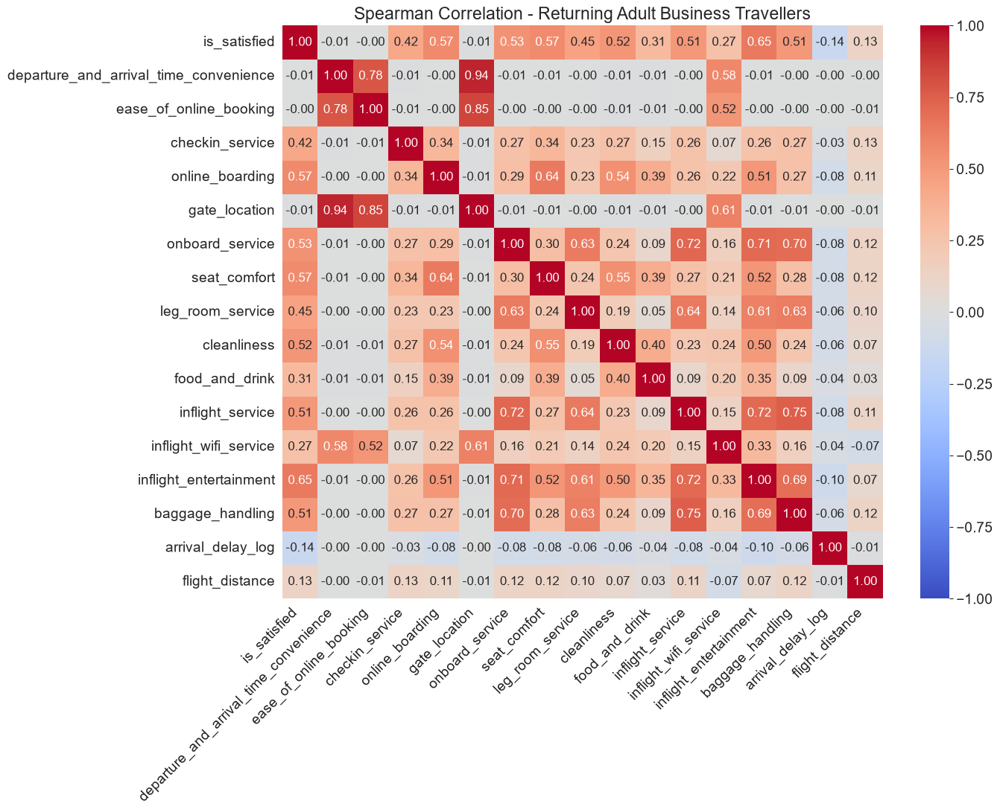

In [1140]:
# Correlations overall

# Fetch relevant columns - is_satisfied + ratings + flight charecteristics (arrival delay, distance)
cols = ['is_satisfied'] + rated_cols + ['arrival_delay_log', 'flight_distance']

# Calculate correlation
corr = df_ret_business[cols].corr(method='spearman')

# Create heatmap
plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, annot_kws={'size': 12})
plt.title('Spearman Correlation - Returning Adult Business Travellers')
plt.xticks(rotation=45, ha='right');

### Ergebnisse zu Frage 3: 

### Zusammenhänge zwischen Faktoren und Zufriedenheit - Interpretation der Spearman-Korrelation für die wiederkehrenden erwachsenen Geschäftsreisenden:
- #### Faktoren, die am stärksten mit der Zufriedenheit zusammenhängen (Korrelation >=0,5):
  - In-Flight Entertainment (0,65)
  - Online Boarding (0,57)
  - Seat Comfort (0,57)
  - On-board Service (0,53)
  - Cleanliness (0,52)
  - In-flight Service (0,51)
  - Baggage Handling (0,51)
- #### Faktoren, die einen mittleren Zusammenhang mit der Zufriedenheit haben (Korrelation 0,3-0,49):
  - Leg Room Service (0,45)
  - Check-in Service (0,42)
  - Food and Drink (0,31)
- #### Faktoren, die am wenigsten mit der Zufriedenheit zusammenhängen
  - **Schwacher Zusammenhang** (Korrelation 0,1-0,29):
    - In-Flight Wifi (0,27)
    - Arrival Delay (-0,14) - der einzige negative Zusammenhang, aber recht schwach
    - Flight Distance (0,13)
  - **Kein Zusammenhang bzw. vernachlässigbar** (Korrelation <0,1):
    - Ease of Online Booking (0,00)
    - Departure and Arrival Time Convenience (0,01)
    - Gate Location (0,01)

Anmerkung: Einteilung der Korrelationsgrenzen nach Cohen (1988)

## FRAGE 4: Wie unterscheiden sich Kundensegmente darin, welche Faktoren mit ihrer Zufriedenheit zusammenhängen?

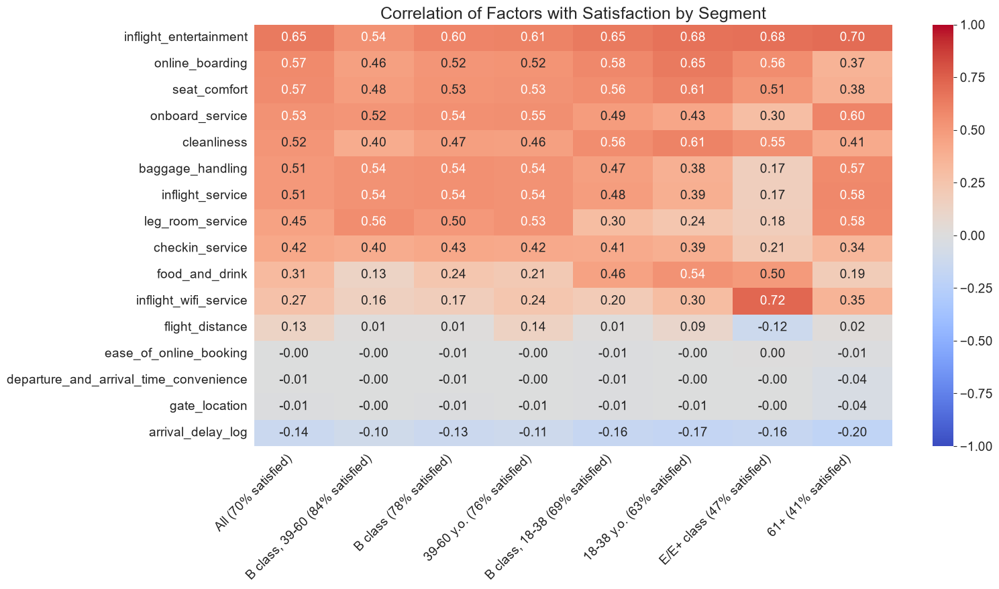

In [1160]:
# Compare correlations between segments - satisfaction vs. factors (ratings, flight distance, ariival delay)

business_class = df_ret_business['class'] == 'Business'

segments = {
    'All (70% satisfied)':                     pd.Series(True, index=df_ret_business.index),
    'B class, 39-60 (84% satisfied)':          business_class & df_ret_business['age'].between(39, 60),
    'B class (78% satisfied)':                 business_class,
    '39-60 y.o. (76% satisfied)':              df_ret_business['age'].between(39, 60),
    'B class, 18-38 (69% satisfied)':          business_class & df_ret_business['age'].between(18, 38),
    '18-38 y.o. (63% satisfied)':              df_ret_business['age'].between(18, 38),
    'E/E+ class (47% satisfied)':              ~business_class,
    '61+ (41% satisfied)':                     df_ret_business['age'] > 60
}

cols = rated_cols + ['arrival_delay_log', 'flight_distance']

sat_corr = pd.DataFrame({
    name: df_ret_business.loc[mask, cols].corrwith(df_ret_business.loc[mask, 'is_satisfied'], method='spearman')
    for name, mask in segments.items()
}).sort_values('All (70% satisfied)', ascending=False)

plt.figure(figsize=(16, 9))
sns.heatmap(sat_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation of Factors with Satisfaction by Segment', fontsize=18)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Ergebnisse zu Frage 4

### Zusammenhänge mit der Zufriedenheit nach Segment - Gemeinsamkeiten und Unterschiede

#### Gemeinsam in allen Segmenten:
- In-flight Entertainment hängt in allen Segmenten stark und in den meisten am stärksten mit der Zufriedenheit zusammen (0,54-0,70)
- Online Booking, Time Convenience und Gate Location zeigen überall keinen Zusammenhang
- Ankunftsverspätung ist überall schwach negativ (-0,10 bis -0,20), am deutlichsten bei 61+

#### Unterschiede zwischen den Segmenten:
- **Economy/Economy+**:
  - Wifi Service ist hier von auffällig großer Wichtigkeit (0,72)
  - In-flight Service, Check-in Service und Baggage Handling spielen kaum eine Rolle (0,17-0,21), anders als in den restlichen Segmenten
- **Eonomy/Economy Plus** und **Jüngere (18-38)**:
    - Essen und Trinken hängt nur in diesen Segmenten deutlich mit der Zufriedenheit zusammen (0,46-0,54)
    - Cleanliness ist hier besonders stark (0,55–0,61), aber auch in anderen Segmenten mittel bis stark
    - Bei Leg Room (0,18-0,24) ist es umgekehrt: deutlich weniger Gewicht im Vergleich zu den anderen Segmenten
- Bei **61+** spielt Online Boarding und Seat Comfort eine geringere Rolle (0,37–0,38) als in den anderen Segmenten
- **39-60**, **Business Class 39–60** und **61+**:
    - On-board Service, In-flight Service, Baggage Handling und Leg Room hängen hier stark mit der Zufriedenheit zusammen (0,50-0,60)
- Flight Distance hat einen schwachen positiven Zusammenhang im 39-60 Segment (0,14), einen schwachen negativen Zusammenhang in Economy/Economy Plus, sonst eher irrelevant
- **Top 5 Faktoren im am wenigsten zufriedenen Kundensegment 61+**:
  - In-flight Entertainement (0,70), Onboard Service (0,60), In-flight Service und Leg Room (0,58), Baggage Handling (0,57)
- **Top 6 Faktoren im am wenigsten zufriedenen Kundensegment von relevanterer Größe - Economy/Economy Plus**:
   - Wifi (0,72), In-Flight Entertainmeint (0,68), Online Boarding (0,56), Cleanliness (0,55), Seat Comfort (0,51), Food and Drink (0,50)

#### Interpretation:

Was mit Zufriedenheit zusammenhängt, unterscheidet sich je nach Segment: 
- Für ältere Fluggäste und die Business Class zählen eher Service und reibungslose Abläufe
- für jüngere und Economy/Economy Plus eher Sauberkeit, Verpflegung und (in Economy) WLAN
- Entertainment ist der einzige durchgängig starke Faktor

**Vorbehalt:** Es sind Zusammenhänge, keine Ursachen

## FRAGE 5: Wie gut werden die einzelnen Kategorien bewertet, insgesamt und nach Segment? 

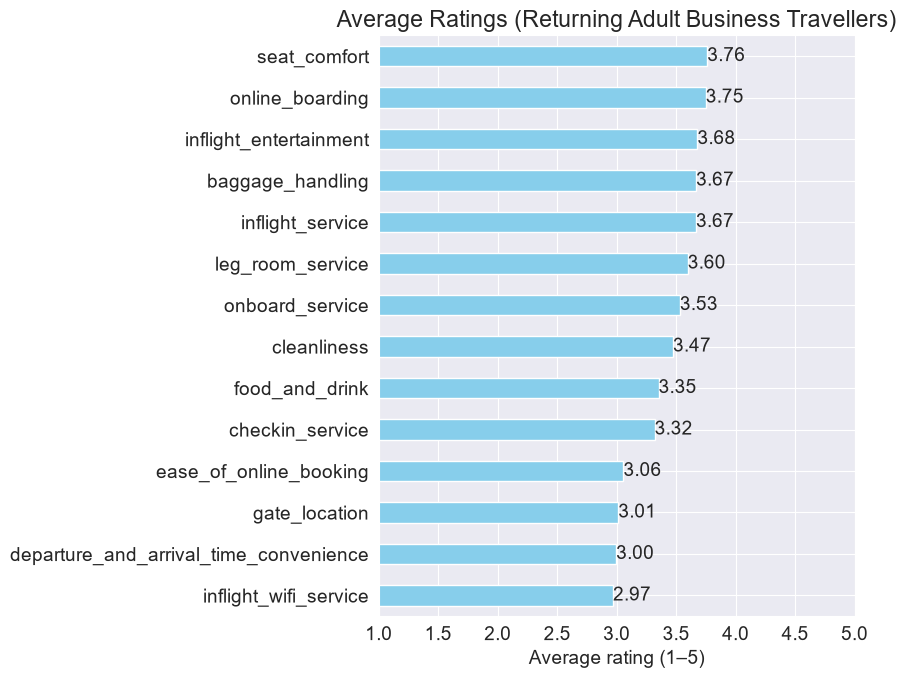

In [1221]:
# Average ratings by category overall

overall = df_ret_business[rated_cols].mean().sort_values()

ax = overall.plot(kind='barh', color=sky_blue, figsize=(9, 7))
ax.bar_label(ax.containers[0], fmt='%.2f')
plt.xlim(1, 5)
plt.xlabel('Average rating (1–5)')
plt.title('Average Ratings (Returning Adult Business Travellers)')
plt.tight_layout();

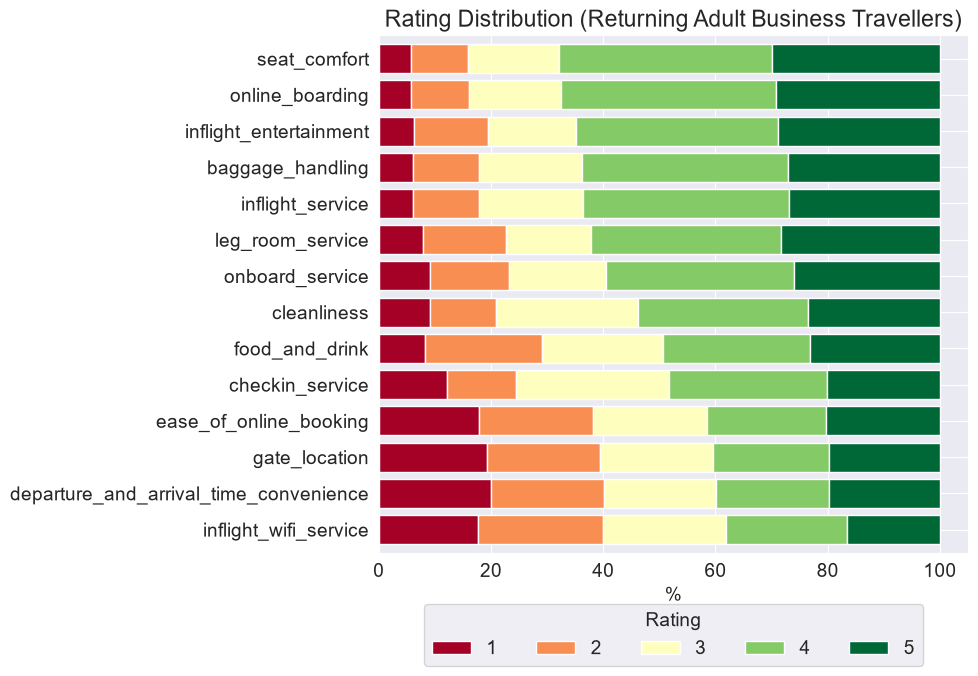

In [1220]:
dist = df_ret_business[rated_cols].apply(lambda s: s.value_counts(normalize=True)).T * 100
dist = dist.sort_index(axis=1)
dist.columns = dist.columns.astype(int)
dist = dist.loc[overall.index]          # gleiche Reihenfolge wie das Balkendiagramm

dist.plot(kind='barh', stacked=True, colormap='RdYlGn', figsize=(10, 7), width=0.8)
plt.xlabel('%')
plt.title('Rating Distribution (Returning Adult Business Travellers)')
plt.legend(title='Rating', loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=5)
plt.tight_layout();

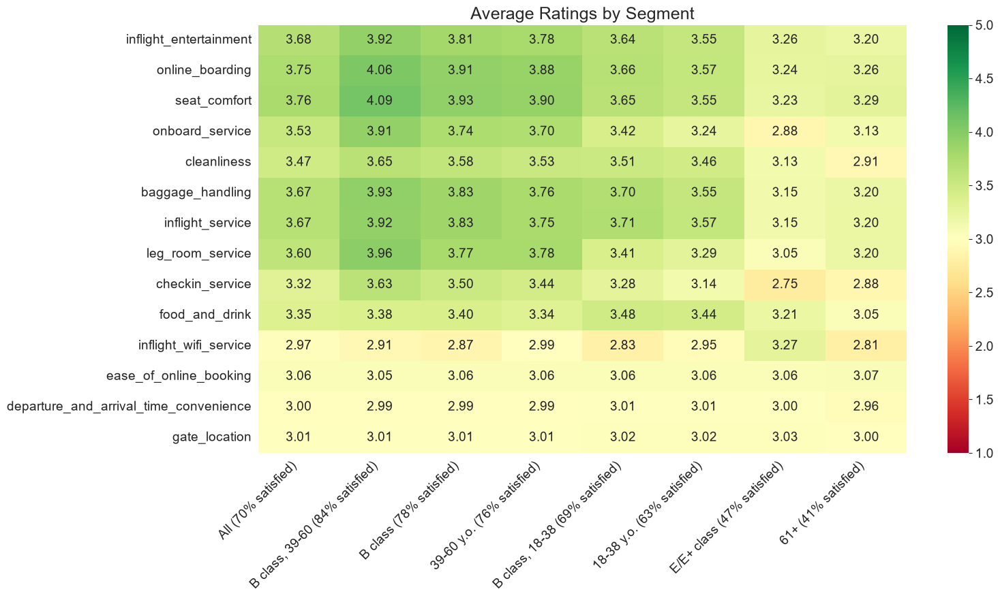

In [1223]:
# Heatmap - average rating per category per segment

means = pd.DataFrame({
    name: df_ret_business.loc[mask, rated_cols].mean()
    for name, mask in segments.items()
}).loc[sat_corr.index]          # same row order as the correlation heatmap

plt.figure(figsize=(16, 9))
sns.heatmap(means, annot=True, fmt='.2f', cmap='RdYlGn', vmin=1, vmax=5)
plt.title('Average Ratings by Segment', fontsize=18)
plt.xticks(rotation=45, ha='right')
plt.tight_layout();

### Ergebnisse zu Frage 5

### Wie gut werden die Kategorien bewertet?

#### Insgesamt (Balken- und Verteilungsdiagramm)
- Die Durchschnittsbewertungen liegen zwischen 2,97 (In-flight Wifi Service) und 3,76 (Seat Comfort), also im mittleren bis guten Bereich
- Keine Kategorie erreicht im Schnitt 4
- Die Kategorien lassen sich grob in drei Gruppen teilen:
    1. Gut bewertet (~3,6-3,8): Seat Comfort, Online Boarding, In-flight Entertainment, Baggage Handling, In-flight Service und Leg Room. Hier vergeben rund 2/3 der Fluggäste eine 4 oder 5
    2. Mittel bewertet (~3,3-3,5): On-board Service, Cleanliness, Food und Drink und Check-in Service. Rund die Hälfte gibt eine 4 oder 5
    3. Schwach bewertet (~3,0): Online Booking, Gate Location, Time Convenience und Wifi. Nur etwa 40% geben eine 4 oder 5

#### Nach Segment (Heatmap)
- Die Bewertungen sinken parallel zur Zufriedenheit: Je zufriedener ein Segment, desto besser bewertet es fast alle Kategorien
- Business Class 39–60 bewertet am besten. Nur hier erreichen Seat Comfort (4,09) und Online Boarding (4,06) einen Durchschnitt über 4
- Economy/Economy Plus und 61+ bewerten am schlechtesten. Die niedrigsten Werte zeigen Check-in (2,75) und On-board Service (2,88) in Economy/Economy Plus, sowie Wifi (2,81), Check-in (2,88) und Cleanliness (2,91) bei 61+
- Food and Drink wird über alle Segmente hinweg ähnlich bewertet (3,05–3,48)
- Online Booking, Time Convenience und Gate Location liegen in allen Segmenten nahezu identisch bei ~3,0

## FRAGE 6: Wie lassen sich die Kategorien nach Wichtigkeit und Bewertung priorisieren (Importance-Performance-Analyse)? 

### Zur IPA-Methode

Die Importance-Performance-Analyse (IPA) ist eine Priorisierungsmethode, bei der für jedes Merkmal dargestellt wird, wie wichtig es für die Kunden ist und wie gut es tatsächlich bewertet wird. Das Ergebnis wird als Prioritätenmatrix mit zwei Achsen und vier Quadranten interpretiert: Die vertikale Achse zeigt die Wichtigkeit, die horizontale Achse die Performance. Die Achsen schneiden sich beim Durchschnitt der Wichtigkeit und der Performance über alle Merkmale und teilen die Fläche in vier Quadranten:

- Hohe Wichtigkeit, niedrige Performance: Das ist das Kernergebnis der Analyse --> hier konzentrieren
- Hohe Wichtigkeit, hohe Performance: Das sind die echten Stärken --> weiter so
- Niedrige Wichtigkeit, niedrige Performance: Die Performance ist schwach, den Kunden aber kaum wichtig --> geringe Priorität
- Niedrige Wichtigkeit, hohe Performance: Hier wird etwas sehr gut erfüllt, das den Kunden kaum wichtig ist --> möglicher Overkill

Quelle: https://www.koji.so/docs/importance-performance-analysis-guide

### Verwendete Schwellen
- Importance-Schwelle: 0,48 = durcschnittliche Zufriedenheitskorrelation über alle Segmente (unter den widerkehrenden erwachsenen Geschäftsreisenden) und alle Kategorien hinweg (Hinweis: Kategorien Online Booking, Time Convenience und Gate Location bei der Berechnung der Schwelle nicht berücksichtigt, weil die keinen Zusammenhang mit der Zufriedenheit zeigen)
- Performance-Schwelle: 3,4 = durchschnittliche Bewertung aller wiederkehrenden erwachsenen Geschäftsreisenden (einheitlich für alle Kundensegmente)

In [1175]:
# Calculate performance threshold based on average rating across all segments and all categories
perf_threshold = means['All (70% satisfied)'].mean()
perf_threshold

np.float64(3.41719089742011)

In [1199]:
# Calculate importance threshold based on average correlation across all segments and all categories - without categories with 0 correlation

sat_corr['All (70% satisfied)'].drop(['ease_of_online_booking', 'departure_and_arrival_time_convenience', 'gate_location']).mean()

np.float64(0.48279416590671914)

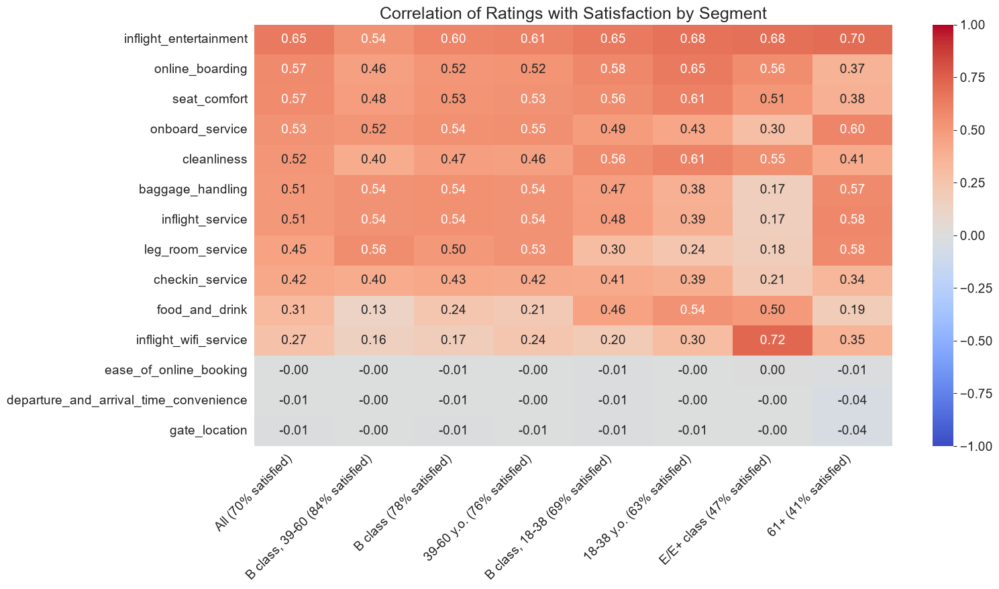

In [1167]:
# Correlation with satisfaction by segment - rated_cols only

sat_corr = pd.DataFrame({
    name: df_ret_business.loc[mask, rated_cols].corrwith(df_ret_business.loc[mask, 'is_satisfied'], method='spearman')
    for name, mask in segments.items()
}).sort_values('All (70% satisfied)', ascending=False)

plt.figure(figsize=(16, 9))
sns.heatmap(sat_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation of Ratings with Satisfaction by Segment', fontsize=18)
plt.xticks(rotation=45, ha='right')
plt.tight_layout();

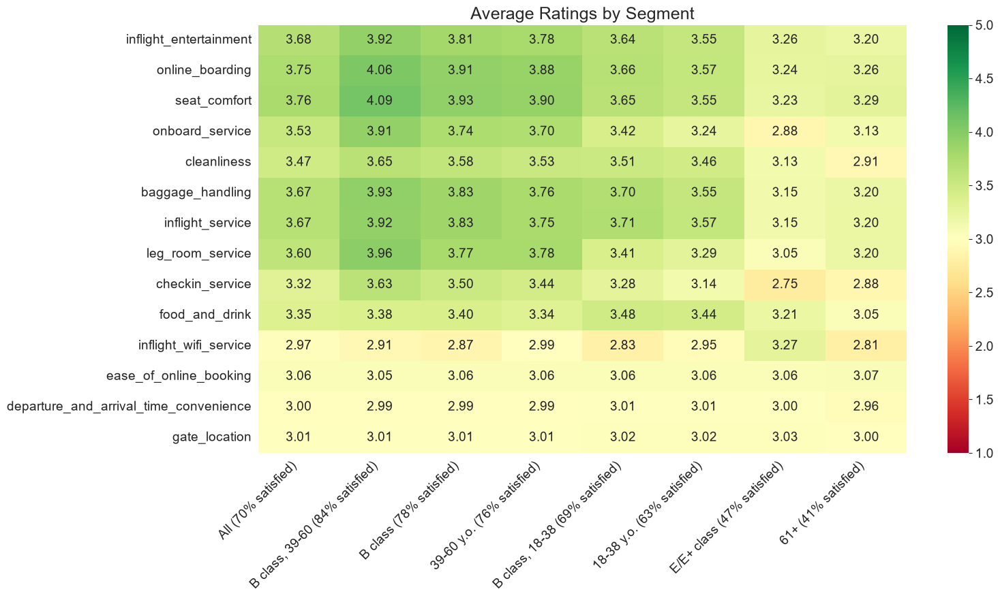

In [1222]:
# Heatmap with average rating per category per segment

means = pd.DataFrame({
    name: df_ret_business.loc[mask, rated_cols].mean()
    for name, mask in segments.items()
}).loc[sat_corr.index]          # same row order as the correlation heatmap

plt.figure(figsize=(16, 9))
sns.heatmap(means, annot=True, fmt='.2f', cmap='RdYlGn', vmin=1, vmax=5)
plt.title('Average Ratings by Segment', fontsize=18)
plt.xticks(rotation=45, ha='right')
plt.tight_layout();

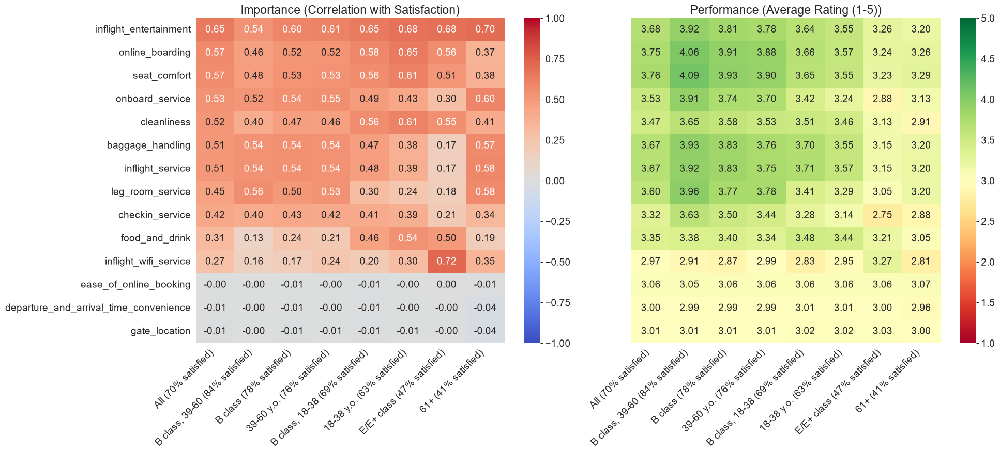

In [1171]:
# IPA analysis - correlation and average rating side by side

fig, axes = plt.subplots(1, 2, figsize=(20, 9), sharey=True)

sns.heatmap(sat_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Importance (Correlation with Satisfaction)')

sns.heatmap(means, annot=True, fmt='.2f', cmap='RdYlGn', vmin=1, vmax=5, ax=axes[1])
axes[1].set_title('Performance (Average Rating (1-5))')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)
    plt.setp(ax.get_xticklabels(), ha='right')
plt.tight_layout()
plt.show()

### Create a scatter plot for each segment to immitate an IPA table (High/low importance / high/low performance)

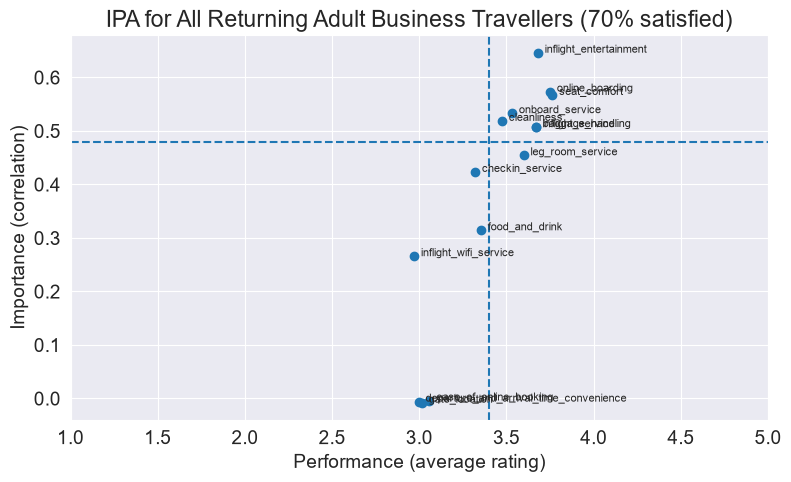

In [1200]:
# IPA scatter plot for all returning adult business travellers

seg_name = 'All (70% satisfied)'
plt.scatter(means[seg_name], sat_corr[seg_name])

for cat in rated_cols:
    plt.annotate(cat, (means.loc[cat, seg_name], sat_corr.loc[cat, seg_name]), fontsize=8, xytext=(5, 0), textcoords='offset points')
    
plt.axvline(3.4, linestyle='--')
plt.axhline(0.48, linestyle='--')
plt.xlabel('Performance (average rating)')
plt.ylabel('Importance (correlation)')
plt.title('IPA for All Returning Adult Business Travellers (70% satisfied)')
plt.xlim(1, 5)
plt.show()

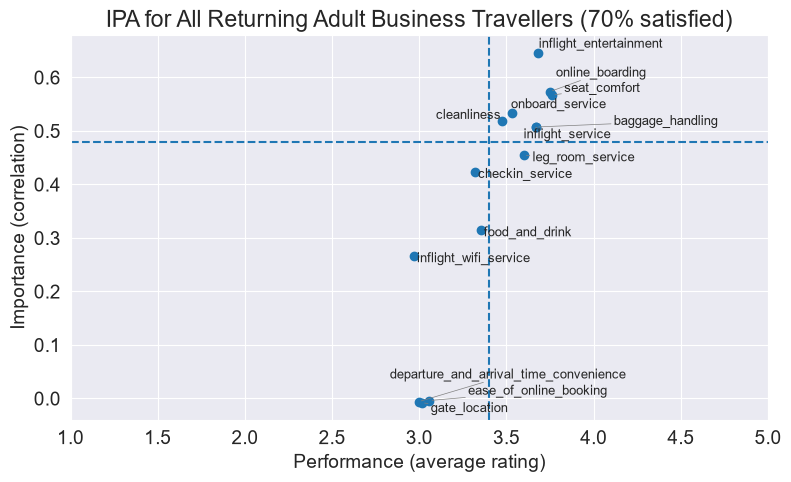

In [1201]:
# IPA scatter plot for all returning adult business travellers

# Import adjustText to fix the overlapping texts
from adjustText import adjust_text

# Plot
seg_name = 'All (70% satisfied)'
plt.scatter(means[seg_name], sat_corr[seg_name])
plt.axvline(3.4, linestyle='--')
plt.axhline(0.48, linestyle='--')
plt.xlabel('Performance (average rating)')
plt.ylabel('Importance (correlation)')
plt.title('IPA for All Returning Adult Business Travellers (70% satisfied)')
plt.xlim(1, 5)

# Texts without overlapping
texts = [plt.text(means.loc[cat, seg_name], sat_corr.loc[cat, seg_name], cat, fontsize=9)
         for cat in rated_cols]
adjust_text(texts, arrowprops=dict(arrowstyle='-', color='gray', lw=0.5))

plt.show()

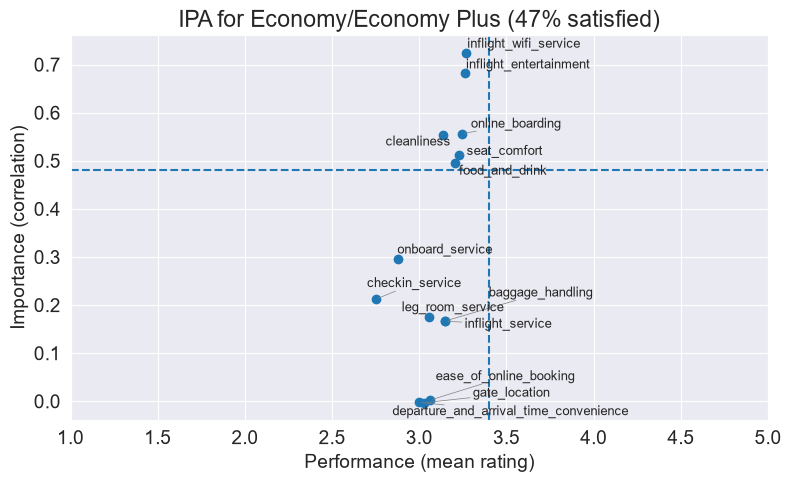

In [1202]:
# IPA for Economy/Economy Plus (47% satisfied)
seg_name_e = 'E/E+ class (47% satisfied)'
plt.scatter(means[seg_name_e], sat_corr[seg_name_e])
plt.axvline(3.4, linestyle='--')
plt.axhline(0.48, linestyle='--')
plt.xlabel('Performance (mean rating)')
plt.ylabel('Importance (correlation)')
plt.title('IPA for Economy/Economy Plus (47% satisfied)')
plt.xlim(1, 5)

# Category names without overlapping
texts = [plt.text(means.loc[cat, seg_name_e], sat_corr.loc[cat, seg_name_e], cat, fontsize=9)
         for cat in rated_cols]
adjust_text(texts, arrowprops=dict(arrowstyle='-', color='gray', lw=0.5))

plt.show()

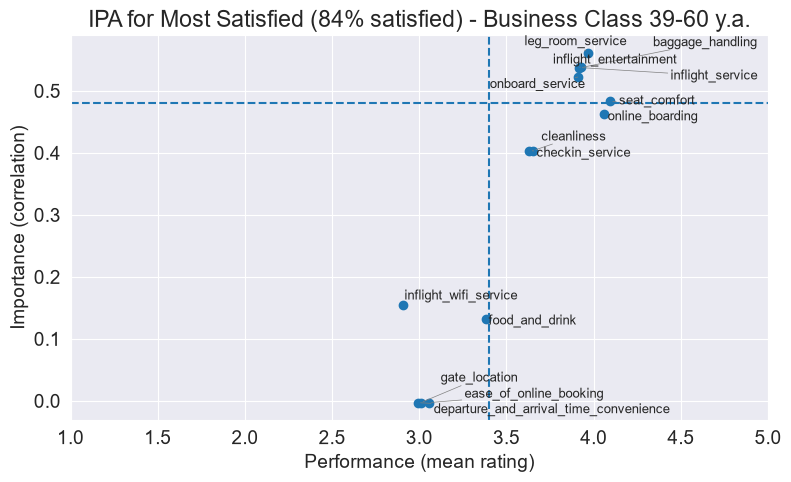

In [1206]:
# IPA scatter plot for most satisfied - B class, 39-60 (84% satisfied, ~50% sample)
seg_name_b_39_60 = 'B class, 39-60 (84% satisfied)'
plt.scatter(means[seg_name_b_39_60], sat_corr[seg_name_b_39_60])
plt.axvline(3.4, linestyle='--')
plt.axhline(0.48, linestyle='--')
plt.xlabel('Performance (mean rating)')
plt.ylabel('Importance (correlation)')
plt.title('IPA for Most Satisfied (84% satisfied) - Business Class 39-60 y.a.')
plt.xlim(1, 5)

# Category names without overlapping
texts = [plt.text(means.loc[cat, seg_name_b_39_60], sat_corr.loc[cat, seg_name_b_39_60], cat, fontsize=9)
         for cat in rated_cols]
adjust_text(texts, arrowprops=dict(arrowstyle='-', color='gray', lw=0.5))

plt.show()

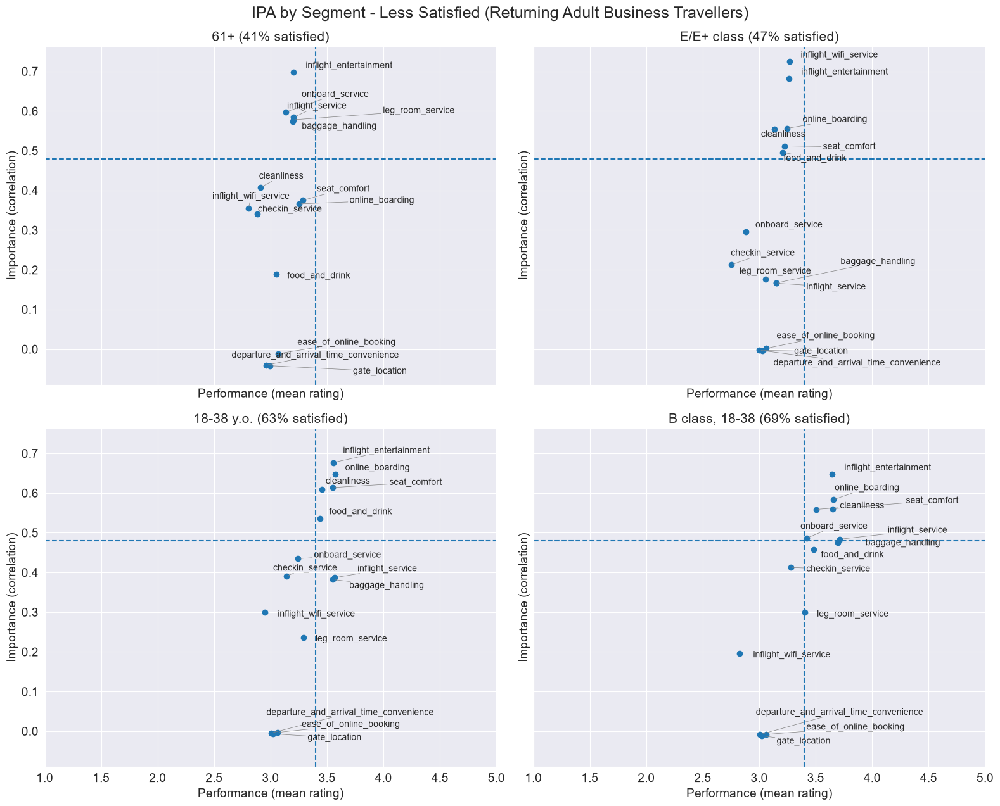

In [1211]:
# IPAs - less satisfied segments
# Display 4 IPAs in one plot: 61+, E/E+, 18-38, B class 18-38

seg_names = ['61+ (41% satisfied)',
             'E/E+ class (47% satisfied)',
             '18-38 y.o. (63% satisfied)',
             'B class, 18-38 (69% satisfied)']

fig, axes = plt.subplots(2, 2, figsize=(16, 13), sharex=True, sharey=True)

for ax, seg in zip(axes.flat, seg_names):
    ax.scatter(means[seg], sat_corr[seg])
    ax.axvline(3.4, linestyle='--')
    ax.axhline(0.48, linestyle='--')
    ax.set_xlim(1, 5)
    ax.set_title(seg, fontsize=15)
    ax.set_xlabel('Performance (mean rating)')
    ax.set_ylabel('Importance (correlation)')

    texts = [ax.text(means.loc[cat, seg], sat_corr.loc[cat, seg], cat, fontsize=10)
             for cat in rated_cols]
    adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color='gray', lw=0.5))

fig.suptitle('IPA by Segment - Less Satisfied (Returning Adult Business Travellers)', fontsize=18)
plt.tight_layout()
plt.show()

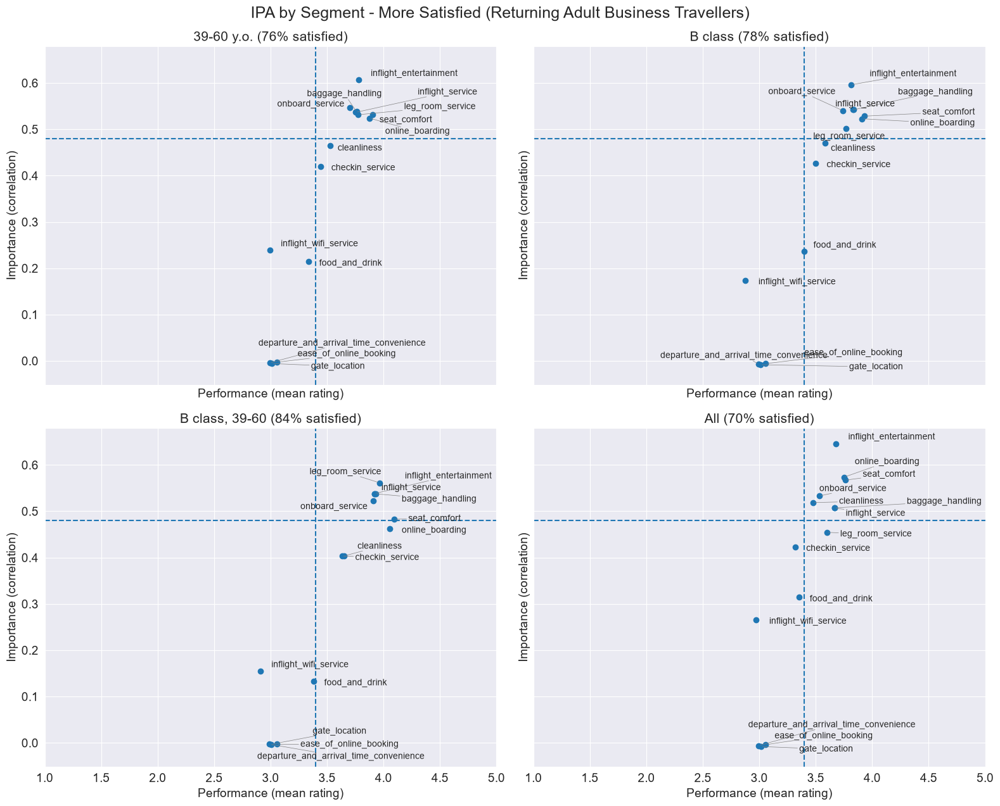

In [1213]:
# IPAs - more satisfied segments
# Display 4 IPAs in one plot: 39-60, B class, B clas 39-60, All

seg_names = ['39-60 y.o. (76% satisfied)',
             'B class (78% satisfied)',
             'B class, 39-60 (84% satisfied)',
             'All (70% satisfied)']

fig, axes = plt.subplots(2, 2, figsize=(16, 13), sharex=True, sharey=True)

for ax, seg in zip(axes.flat, seg_names):
    ax.scatter(means[seg], sat_corr[seg])
    ax.axvline(3.4, linestyle='--')
    ax.axhline(0.48, linestyle='--')
    ax.set_xlim(1, 5)
    ax.set_title(seg, fontsize=15)
    ax.set_xlabel('Performance (mean rating)')
    ax.set_ylabel('Importance (correlation)')

    texts = [ax.text(means.loc[cat, seg], sat_corr.loc[cat, seg], cat, fontsize=10)
             for cat in rated_cols]
    adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color='gray', lw=0.5))

fig.suptitle('IPA by Segment - More Satisfied (Returning Adult Business Travellers)', fontsize=18)
plt.tight_layout()
plt.show()

## Ergebnisse zu Frage 6

### Ergebnisse der IPA-Analyse: Priorisierung der Kategorien nach Wichtigkeit und Bewertung

### Alle wiederkehrenden erwachsenen Geschäftsreisenden (70% zufrieden)
- Hohe Importance, niedrige Performance = Hier konzentrieren:
  - nichts
- Hohe Importance, hohe Performance = Weiter so:
  - Entertainment, Online Boarding, Seat Comfort, On-board Service, Cleanliness, Baggage Handling, In-flight Service
- Niedrige Importance, niedrige Performance = Geringe Priorität:
  - Check-in Service, Food and Drink, Wifi
- Niedrige Importance, hohe Performance = Möglicher Overkill:
  - Leg Room

### Segmente, die mehrheitlich neutral oder unzufrieden sind:
#### 61+ (41% zufrieden)
- Hohe Importance, niedrige Performance = Hier konzentrieren:
  - Entertainment
  - On-board Service
  - In-flight Service
  - Leg Room
  - Baggage Handling
- Hohe Importance, hohe Performance = Weiter so:
  - nichts
- Niedrige Importance, niedrige Performance = Geringe Priorität:
  - Cleanliness, Seat Comfort, Online Boarding. Check-in Service, Wifi, Food and Drink
- Niedrige Importance, hohe Performance = Möglicher Overkill:
  - nichts

#### Economy/Economy Plus (47% zufrieden)
- Hohe Importance, niedrige Performance = Hier konzentrieren:
  - Wifi
  - Entertainment
  - Online Boarding
  - Cleanliness
  - Seat Comfort
  - Food and Drink
- Hohe Importance, hohe Performance = Weiter so:
  - nichts
- Niedrige Importance, niedrige Performance = Geringe Priorität:
  - On-board Service, Check-in Service, Leg Room, Baggage Handling, In-flight Service
- Niedrige Importance, hohe Performance = Möglicher Overkill:
  - nichts

### Mehrheitlich zufriedene Segmente
#### 18-38-jährige (63% zufrieden)
- Hohe Importance, niedrige Performance = Hier konzentrieren:
  - nichts
- Hohe Importance, hohe Performance = Weiter so:
  - Entertainment, Online Boarding, Seat Comfort
  - Grenzfälle: Cleanliness, Food and Drink (Performance knapp über 3,4)
- Niedrige Importance, niedrige Performance = Geringe Priorität:
  - On-board Service, Check-in Service, Wifi, Leg Room
- Niedrige Importance, hohe Performance = Möglicher Overkill:
  - In-flight Service, Baggage Handling

#### Business Class 18-38-jährige (69% zufrieden)
- Hohe Importance, niedrige Performance = Hier konzentrieren
  - nichts
- Hohe Importance, hohe Performance = Weiter so:
  - Entertainment, Online Boarding, Seat Comfort, Cleanliness
  - Grenzfälle: On-board, In-flight Service, Baggage (Importance um 0,48)
- Niedrige Importance, niedrige Performance = Geringe Priorität:
  - Check-in Service, Wifi
- Niedrige Importance, hohe Performance = Möglicher Overkill:
  - Food and Drink

#### 39-60 (76% zufrieden)
- Hohe Importance, niedrige Performance = Hier konzentrieren:
  - nichts
- Hohe Importance, hohe Performance = Weiter so:
  - Entertainment, Baggage Handling, In-flight Service, On-board Service, Leg Room, Seat Comfort, Online Boarding
- Niedrige Importance, niedrige Performance = Geringe Priorität:
  - Wifi, Food and Drink
- Niedrige Importance, hohe Performance = Möglicher Overkill:
  - Cleanliness, Check-in Service
 
#### Business Class (78% zufrieden)
- Hohe Importance, niedrige Performance = Hier konzentrieren:
  - nichts
- Hohe Importance, hohe Performance = Weiter so:
  - Entertainment, On-board Service, In-flight Service, Baggage Handling, Seat Comfort, Online Boarding, Leg Room
- Niedrige Importance, niedrige Performance = Geringe Priorität:
  - Wifi
- Niedrige Importance, hohe Performance = Möglicher Overkill:
  - Cleanliness, Check-in Service

#### Business Class 39-60 (84% zufrieden)
- Hohe Importance, niedrige Performance = Hier konzentrieren:
  - nichts
- Hohe Importance, hohe Performance = Weiter so:
  - Leg Room, Entertainment, In-flight Service, Baggage Handling, On-board Service
  - Grenzfall: Seat Comfort
- Niedrige Importance, niedrige Performance = Geringe Priorität:
  - Wifi, Food and Drink
- Niedrige Importance, hohe Performance = Möglicher Overkill:
  - Online Boarding, Cleanliness, Check-in Service

**Anmerkung:** Online Booking, Time Convenience und Gate Location liegen überall bei Wichtigkeit ~0 und schwacher Performance, also „geringe Prio“.

### Interpretation
1. Handlungsbedarf gibt es nur bei 61+ und Economy/Economy Plus, genau den beiden am wenigsten zufriedenen Segmenten. In allen anderen liegen die wichtigen Faktoren über dem Durchschnitt.
2. Die beiden Segmente brauchen Unterschiedliches: 61+ vor allem Service und Abläufe, Economy/Economy Plus vor allem Komfort und digitale Angebote.
3. Entertainment ist überall wichtig, wird aber nur bei 61+ und Economy/Economy Plus unterdurchschnittlich bewertet. Es ist damit der einzige Faktor, der in beiden Problemsegmenten oben links steht.

# Frage 7: Wo liegen Ansatzpunkte zur Steigerung der Zufriedenheit, insgesamt und in einzelnen Kundensegmenten?

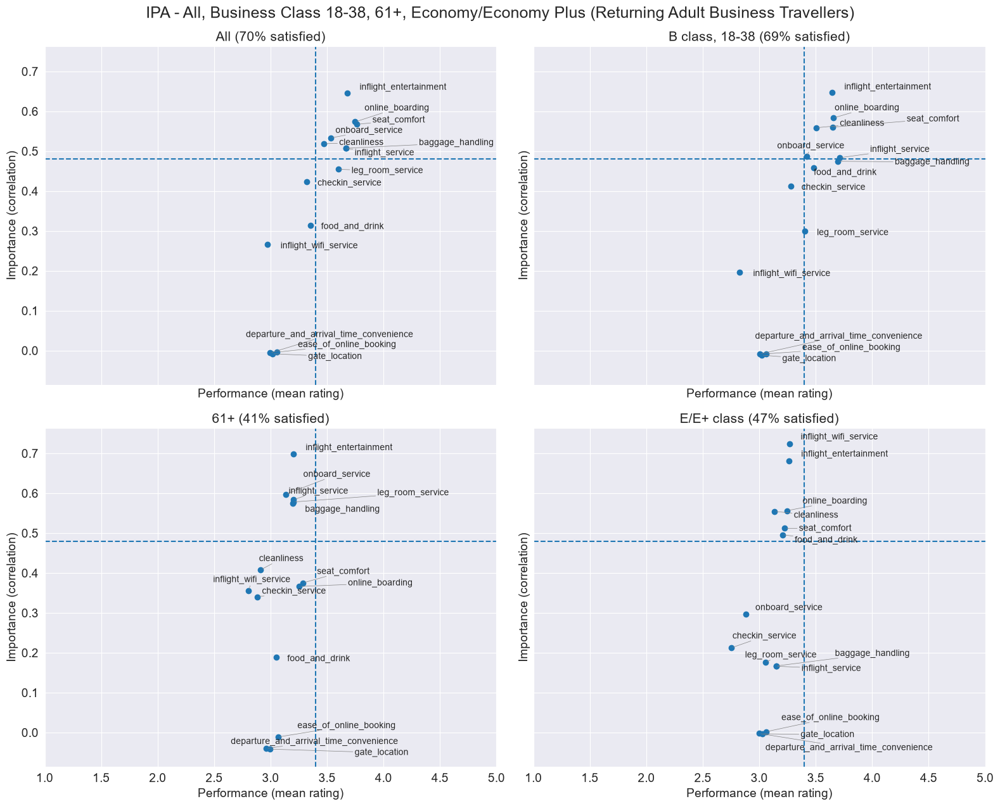

In [1228]:
# Display 4 IPAs in one plot: 61+, E/E+, B class 18-38, All

seg_names = ['All (70% satisfied)',
             'B class, 18-38 (69% satisfied)',
             '61+ (41% satisfied)',
             'E/E+ class (47% satisfied)']

fig, axes = plt.subplots(2, 2, figsize=(16, 13), sharex=True, sharey=True)

for ax, seg in zip(axes.flat, seg_names):
    ax.scatter(means[seg], sat_corr[seg])
    ax.axvline(3.4, linestyle='--')
    ax.axhline(0.48, linestyle='--')
    ax.set_xlim(1, 5)
    ax.set_title(seg, fontsize=15)
    ax.set_xlabel('Performance (mean rating)')
    ax.set_ylabel('Importance (correlation)')

    texts = [ax.text(means.loc[cat, seg], sat_corr.loc[cat, seg], cat, fontsize=10)
             for cat in rated_cols]
    adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color='gray', lw=0.5))

fig.suptitle('IPA - All, Business Class 18-38, 61+, Economy/Economy Plus (Returning Adult Business Travellers)', fontsize=18)
plt.tight_layout()
plt.show()

## Ergebnisse zu Frage 7 

## Ansatzpunkte zur Steigerung der Zufriedenheit - Handlungsempfehlungen basierend auf der IPA-Analyse

Für alle wiederkehrenden erwachsenen Geschäftsreisenden ergibt sich kein akuter Handlungsbedarf. Die wichtigen Faktoren werden überdurchschnittlich bewertet und sollten auf diesem Niveau gehalten werden. Verbesserungspotenzial zeigt sich vor allem in einzelnen Segmenten (Economy/Economy Plus, 61+).

### Fluggäste ab 61
1. Boarding-Prozess (On-board Service) verbessern: z.B. bevorzugtes Boarding, Unterstützung am Gate
2. Betreuung an Bord (In-flight Service): aufmerksamer Service durch das Kabinenpersonal
3. Gepäckabfertigung: z.B. Unterstützung bei Aufgabe und Abholung
4. Beinfreiheit: Sitzplätze mit mehr Beinfreiheit gezielt anbieten
5. Entertainment: einfache Bedienbarkeit und altersgerechtes Angebot prüfen

### Economy/Economy Plus
1. Entertainment und WLAN: Verfügbarkeit und Qualität in der Economy Klasse verbessern
2. Sauberkeit und Sitzkomfort: Qualitätskontrolle in der Economy-Kabine
3. Essen und Trinken: Angebot in der Economy Klasse prüfen
4. Online Boarding: digitalen Boarding-Prozess vereinfachen

## Anmerkungen und Vorbehalte
1. Grenzfälle (18–38: Cleanliness, Food and Drink; Business 18–38: On-board Service, In-flight Service, Baggage handling) können je nach Importance-/Performance-Schwelle wechseln.
2. Die Analyse zeigt Zusammenhänge, keine Ursachen. Die Empfehlungen sind Hypothesen.
3. Die Daten-Artefakte (Wifi, Reisezweck "personal", First-Time-Kunden) wurden zwar vor der finalen Kundensegmentierung und IPA Analyse entfernt, aber die Integrität der verbleibenden Daten ist damit nicht gesichert. Es empfiehlt sich eine tiefgehende Datenprüfung. Bis dahin sind die Empfehlungen mit Vorsicht zu genießen.

# ZUSAMMENFASSUNG

## Datengrundlage und Eingrenzung
Ausgangspunkt war der Kaggle-Datensatz „Airline Passenger Satisfaction“ mit 129.880 Datensätzen. Im Zuge der Datenprüfung zeigten sich mehrere Auffälligkeiten. Der Analyseumfang wurde daher schrittweise eingegrenzt:
1.	Entfernen von 0-Bewertungen in Kategorien mit nur wenigen Nullen (737 Datensätze)
2.	Ausschluss des WLAN-Artefakts: Alle Fluggäste ohne WLAN-Bewertung waren zu 100% zufrieden (3.675 Datensätze)
3.	Ausschluss der Privatreisenden: Ihre Zufriedenheit hing nahezu ausschließlich von den Kategorien WLAN, Online Booking und Online Boarding ab (39.009 Datensätze)
4.	Ausschluss Minderjähriger auf Geschäftsreise (2.739 Datensätze)
5.	Ausschluss der Neukunden: Ihre Zufriedenheit zeigte unplausible Zusammenhänge und hing von den Kategorien Wifi Service, Online Booking, Online Boarding und Time Convenience ab (21.357 Datensätze)

Die finale Analyse basiert auf 62.363 wiederkehrenden erwachsenen Geschäftsreisenden. Alle Projektfragen wurden auf dieser Grundlage beantwortet.

## Wichtigste Erkenntnisse
- **Zufriedenheit**: 70 % der wiederkehrenden erwachsenen Geschäftsreisenden sind zufrieden. Die Zufriedenheit hängt vor allem mit der Reiseklasse (Business 78% vs. Economy/Economy Plus 47%) und dem Alter zusammen (am höchsten bei 39-60, deutlich niedriger ab 61, auch innerhalb derselben Reiseklasse).
- **Segmente**: Am zufriedensten ist die Business Class im Alter von 39-60 Jahren (84%), am wenigsten zufrieden sind Fluggäste ab 61 (41%) und in Economy/Economy Plus (47%).
- **Zusammenhänge**: Am stärksten hängen In-flight Entertainment, Seat Comfort, Online Boarding, On-board Service, Cleanliness, Baggage Handling und In-flight Service mit der Zufriedenheit zusammen. Was zählt, unterscheidet sich je nach Segment: bei Älteren und in der Business Class eher Service und Abläufe, bei Jüngeren und in Economy/Economy Plus eher Sauberkeit, Verpflegung und (in Economy) WLAN.
- **Bewertungen**: Keine Kategorie erreicht im Durchschnitt 4.
- **IPA**: Handlungsbedarf ("Hier konzentrieren") zeigt sich nur in den beiden am wenigsten zufriedenen Segmenten: Economy/Economy Plus und 61+.

## Handlungsempfehlungen
- **Gesamtgruppe und zufriedenere Segmente**: Kein Handlungsbedarf. Servicestärken halten, Kategorien im Bereich "möglicher Overkill" nicht weiter ausbauen und Ressourcen in die Problemsegmente lenken.
- **Fluggäste ab 61**: Boarding-Prozess, Betreuung durch das Kabinenpersonal, Gepäckabfertigung, Beinfreiheit und Entertainment verbessern.
- **Economy/Economy Plus**: Entertainment, WLAN, Sauberkeit, Sitzkomfort, Verpflegung und Online Boarding verbessern.

Die Empfehlungen sind als Hypothesen zu verstehen, die vor einer Umsetzung zu prüfen wären, etwa durch A/B-Tests.

## Einschränkungen
- Der Datensatz ist sehr wahrscheinlich synthetisch. Inwiefern die Ergebnisse ein reales Fluggastverhalten demonstrieren ist unklar.
- Auch in der bereinigten Gruppe zeigen einzelne Variablen auffällige Muster (z.B. 100% Zufriedenheit bei Bewertung 5 für Online Boarding).
- Die Analysen zeigen Zusammenhänge, keine Ursachen.
- Die Ergebnisse gelten nur für wiederkehrende erwachsene Geschäftsreisende.

## Herausforderungen und Lessons Learned
- Auffällige Ergebnisse sollten nicht für bare Münze genommen werden. Ein scheinbar starker Befund (höhere Zufriedenheit ohne Online-Booking-Bewertung) kehrte sich nach Ausschluss des WLAN-Artefakts ins Gegenteil um.
- Plausibilitätsprüfungen und Sensitivitätsanalysen sind entscheidend für belastbare Aussagen.

## Ausblick
Mit realen Befragungsdaten ließe sich dieselbe Methodik ohne die beschriebenen Einschränkungen anwenden. Ergänzend wären Informationen zu Preis und Kundenbindung/Wiederbuchungen hilfreich.

In [1235]:
# Export final dataframe to csv
df_ret_business.to_csv('df_ret_business.csv', index=False)